In [1]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!pip -q install pandas numpy pyarrow

import os
from pathlib import Path
from collections import Counter

import pandas as pd
import numpy as np
import pyarrow.parquet as pq
import pyarrow.compute as pc

from IPython.display import display

DATA_DIR = Path("/content/drive/MyDrive/ThucTap/data")

if not DATA_DIR.exists():
    raise FileNotFoundError(
        f"Không tìm thấy thư mục: {DATA_DIR}"
    )

parquet_files = sorted([
    p for p in DATA_DIR.rglob("*")
    if p.is_file()
    and p.suffix.lower() in [".parquet", ".pq"]
])

print("=" * 70)
print("DANH SÁCH FILE PARQUET")
print("=" * 70)

print(f"Tổng số file tìm thấy: {len(parquet_files)}")

for i, file_path in enumerate(parquet_files, 1):
    size_mb = file_path.stat().st_size / (1024 ** 2)

    print(f"\nFile {i}: {file_path.name}")
    print(f"Đường dẫn: {file_path}")
    print(f"Dung lượng: {size_mb:.2f} MB")

if len(parquet_files) == 0:
    raise ValueError("Không tìm thấy file Parquet nào!")

if len(parquet_files) != 5:
    print("\nCẢNH BÁO: Số file tìm thấy khác 5.")
    print("Hãy kiểm tra lại thư mục dữ liệu.")

DANH SÁCH FILE PARQUET
Tổng số file tìm thấy: 5

File 1: Benign-Monday.parquet
Đường dẫn: /content/drive/MyDrive/ThucTap/data/Benign-Monday.parquet
Dung lượng: 49.99 MB

File 2: Bruteforce-Tuesday.parquet
Đường dẫn: /content/drive/MyDrive/ThucTap/data/Bruteforce-Tuesday.parquet
Dung lượng: 41.80 MB

File 3: DoS-Wednesday.parquet
Đường dẫn: /content/drive/MyDrive/ThucTap/data/DoS-Wednesday.parquet
Dung lượng: 63.58 MB

File 4: Infiltration-Webattacks-Thursday.parquet
Đường dẫn: /content/drive/MyDrive/ThucTap/data/Infiltration-Webattacks-Thursday.parquet
Dung lượng: 39.31 MB

File 5: Portscan-DDos-Botnet-Friday.parquet
Đường dẫn: /content/drive/MyDrive/ThucTap/data/Portscan-DDos-Botnet-Friday.parquet
Dung lượng: 53.13 MB


In [3]:
file_summary = []

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

print("=" * 80)
print("KHẢO SÁT TỪNG FILE PARQUET")
print("=" * 80)

for i, file_path in enumerate(parquet_files, 1):

    print(f"\n{'=' * 80}")
    print(f"FILE {i}: {file_path.name}")
    print("=" * 80)

    parquet_file = pq.ParquetFile(file_path)

    total_rows = parquet_file.metadata.num_rows
    total_columns = len(parquet_file.schema_arrow.names)
    column_names = parquet_file.schema_arrow.names

    print(f"\nSố dòng: {total_rows:,}")
    print(f"Số cột: {total_columns}")

    file_summary.append({
        "File": file_path.name,
        "So_dong": total_rows,
        "So_cot": total_columns
    })

    print("\nDANH SÁCH CÁC CỘT:")

    for j, column in enumerate(column_names, 1):
        print(f"{j:02d}. {column}")

    print("\n5 DÒNG DỮ LIỆU ĐẦU TIÊN:")

    batch = next(
        parquet_file.iter_batches(batch_size=5),
        None
    )

    if batch is not None:
        df_head = batch.to_pandas()
        display(df_head)
    else:
        print("File không có dữ liệu.")

# Bảng tổng hợp cả 5 file
summary_df = pd.DataFrame(file_summary)

print("\n" + "=" * 80)
print("BẢNG TỔNG HỢP 5 FILE")
print("=" * 80)

display(summary_df)

print(f"Tổng số dòng (chưa xử lý trùng): "
      f"{summary_df['So_dong'].sum():,}")

KHẢO SÁT TỪNG FILE PARQUET

FILE 1: Benign-Monday.parquet

Số dòng: 350,718
Số cột: 83

DANH SÁCH CÁC CỘT:
01. Protocol
02. Flow Duration
03. Total Fwd Packets
04. Total Backward Packets
05. Fwd Packets Length Total
06. Bwd Packets Length Total
07. Fwd Packet Length Max
08. Fwd Packet Length Min
09. Fwd Packet Length Mean
10. Fwd Packet Length Std
11. Bwd Packet Length Max
12. Bwd Packet Length Min
13. Bwd Packet Length Mean
14. Bwd Packet Length Std
15. Flow Bytes/s
16. Flow Packets/s
17. Flow IAT Mean
18. Flow IAT Std
19. Flow IAT Max
20. Flow IAT Min
21. Fwd IAT Total
22. Fwd IAT Mean
23. Fwd IAT Std
24. Fwd IAT Max
25. Fwd IAT Min
26. Bwd IAT Total
27. Bwd IAT Mean
28. Bwd IAT Std
29. Bwd IAT Max
30. Bwd IAT Min
31. Fwd PSH Flags
32. Bwd PSH Flags
33. Fwd URG Flags
34. Bwd URG Flags
35. Fwd RST Flags
36. Bwd RST Flags
37. Fwd Header Length
38. Bwd Header Length
39. Fwd Packets/s
40. Bwd Packets/s
41. Packet Length Min
42. Packet Length Max
43. Packet Length Mean
44. Packet Length S

,Protocol,Flow Duration,Total Fwd Packets,Total Backward Packets,Fwd Packets Length Total,Bwd Packets Length Total,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd RST Flags,Bwd RST Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Packet Length Min,Packet Length Max,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWR Flag Count,ECE Flag Count,Down/Up Ratio,Avg Packet Size,Avg Fwd Segment Size,Avg Bwd Segment Size,Fwd Avg Bytes/Bulk,Fwd Avg Packets/Bulk,Fwd Avg Bulk Rate,Bwd Avg Bytes/Bulk,Bwd Avg Packets/Bulk,Bwd Avg Bulk Rate,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,Init Fwd Win Bytes,Init Bwd Win Bytes,Fwd Act Data Packets,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,ICMP Code,ICMP Type,Total TCP Flow Time,Label
0,0,119719148,231,0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.000000,1.929516,5.205180e+05,2274525.75,20694308.0,0.0,119719152.0,5.205180e+05,2274525.75,20694308.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,0,0,1.929516,0.000000,0.0,0.0,0.000000,0.000000,0.000000,0,0,0,0,0,0,0,0,0.0,0.000000,0.000000,0.0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,8721244.0,8761761.0,22509460.0,17.0,12685486.0,5296658.0,20694308.0,6499982.0,-1,-1,0,Benign
1,17,65511209,6,6,288.0,288.0,48.0,48.0,48.000000,0.000000,48.0,48.0,48.0,0.0,8.792388,0.183175,5.955564e+06,19258082.00,64004884.0,3.0,65511096.0,1.310222e+07,28462970.00,64004960.0,3.0,65511104.0,13102221.0,28462988.0,64004996.0,3.0,0,0,0,0,0,0,48,48,0.091587,0.091587,48.0,48.0,48.000000,0.000000,0.000000,0,0,0,0,0,0,0,0,1.0,48.000000,48.000000,48.0,0,0,0,0,0,0,0,24,0,24,0,0,5,8,1506210.0,0.0,1506210.0,1506210.0,64004884.0,0.0,64004884.0,64004884.0,-1,-1,0,Benign
2,17,113976922,267,0,20447.0,0.0,153.0,37.0,76.580521,44.140625,0.0,0.0,0.0,0.0,179.395966,2.342579,4.284847e+05,3701805.25,48523116.0,0.0,113976920.0,4.284847e+05,3701805.25,48523116.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,2136,0,2.342580,0.000000,37.0,153.0,76.580521,44.140625,1948.394775,0,0,0,0,0,0,0,0,0.0,76.580521,76.580521,0.0,2044,26,4794,0,0,0,1,76,0,0,0,0,266,8,2745981.5,5491934.5,10983883.0,14.0,25498178.0,18833046.0,48523116.0,5463561.0,-1,-1,0,Benign
3,17,67037196,8,8,384.0,384.0,48.0,48.0,48.000000,0.000000,48.0,48.0,48.0,0.0,11.456326,0.238673,4.469146e+06,14271655.00,55956316.0,44916.0,66990996.0,9.570142e+06,20477636.00,56001260.0,992873.0,66991088.0,9570156.0,20478190.0,56002516.0,991683.0,0,0,0,0,0,0,64,64,0.119337,0.119337,48.0,48.0,48.000000,0.000000,0.000000,0,0,0,0,0,0,0,0,1.0,48.000000,48.000000,48.0,0,0,0,0,0,0,0,24,0,24,0,0,7,8,11034681.0,0.0,11034681.0,11034681.0,55956316.0,0.0,55956316.0,55956316.0,-1,-1,0,Benign
4,17,68045057,8,8,384.0,384.0,48.0,48.0,48.000000,0.000000,48.0,48.0,48.0,0.0,11.286639,0.235138,4.536337e+06,14525054.00,56943904.0,57451.0,67987504.0,9.712500e+06,20855822.00,57001356.0,989295.0,67987528.0,9712504.0,20855866.0,57001460.0,989348.0,0,0,0,0,0,0,64,64,0.117569,0.117569,48.0,48.0,48.000000,0.000000,0.000000,0,0,0,0,0,0,0,0,1.0,48.000000,48.000000,48.0,0,0,0,0,0,0,0,24,0,24,0,0,7,8,11043596.0,0.0,11043596.0,11043596.0,56943904.0,0.0,56943904.0,56943904.0,-1,-1,0,Benign



FILE 2: Bruteforce-Tuesday.parquet

Số dòng: 307,071
Số cột: 83

DANH SÁCH CÁC CỘT:
01. Protocol
02. Flow Duration
03. Total Fwd Packets
04. Total Backward Packets
05. Fwd Packets Length Total
06. Bwd Packets Length Total
07. Fwd Packet Length Max
08. Fwd Packet Length Min
09. Fwd Packet Length Mean
10. Fwd Packet Length Std
11. Bwd Packet Length Max
12. Bwd Packet Length Min
13. Bwd Packet Length Mean
14. Bwd Packet Length Std
15. Flow Bytes/s
16. Flow Packets/s
17. Flow IAT Mean
18. Flow IAT Std
19. Flow IAT Max
20. Flow IAT Min
21. Fwd IAT Total
22. Fwd IAT Mean
23. Fwd IAT Std
24. Fwd IAT Max
25. Fwd IAT Min
26. Bwd IAT Total
27. Bwd IAT Mean
28. Bwd IAT Std
29. Bwd IAT Max
30. Bwd IAT Min
31. Fwd PSH Flags
32. Bwd PSH Flags
33. Fwd URG Flags
34. Bwd URG Flags
35. Fwd RST Flags
36. Bwd RST Flags
37. Fwd Header Length
38. Bwd Header Length
39. Fwd Packets/s
40. Bwd Packets/s
41. Packet Length Min
42. Packet Length Max
43. Packet Length Mean
44. Packet Length Std
45. Packet Length V

,Protocol,Flow Duration,Total Fwd Packets,Total Backward Packets,Fwd Packets Length Total,Bwd Packets Length Total,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd RST Flags,Bwd RST Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Packet Length Min,Packet Length Max,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWR Flag Count,ECE Flag Count,Down/Up Ratio,Avg Packet Size,Avg Fwd Segment Size,Avg Bwd Segment Size,Fwd Avg Bytes/Bulk,Fwd Avg Packets/Bulk,Fwd Avg Bulk Rate,Bwd Avg Bytes/Bulk,Bwd Avg Packets/Bulk,Bwd Avg Bulk Rate,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,Init Fwd Win Bytes,Init Bwd Win Bytes,Fwd Act Data Packets,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,ICMP Code,ICMP Type,Total TCP Flow Time,Label
0,6,90030854,10,10,8.0,2.0,1.0,0.0,0.8,0.421637,1.0,0.0,0.2,0.421637,0.111073,0.222146,4738466.0,11232767.0,30013372.0,3.0,90030816.0,10003424.0,14988119.0,30013426.0,3.0,90030800.0,10003422.0,14988137.0,30013420.0,3.0,0,0,0,0,0,0,224,296,0.111073,0.111073,0.0,1.0,0.5,0.512989,0.263158,0,0,0,0,20,0,0,0,1.0,0.5,0.8,0.2,0,0,0,0,0,0,0,0,0,0,254,2049,7,20,2.276133e+04,3.931813e+04,68162.0,57.0,29987508.0,35592.5,30013372.0,29946916.0,-1,-1,90030854,Benign
1,0,106007973,26,0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000,0.000000,0.245265,4240319.0,8677062.0,27220170.0,1.0,106007976.0,4240319.0,8677062.0,27220170.0,1.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,0,0,0.245265,0.000000,0.0,0.0,0.0,0.000000,0.000000,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1.730944e+06,2.273625e+06,4789258.0,19.0,19816840.0,8154880.5,27220170.0,7234941.0,-1,-1,0,Benign
2,17,64015367,4,4,192.0,192.0,48.0,48.0,48.0,0.000000,48.0,48.0,48.0,0.000000,5.998559,0.124970,9145052.0,24195428.0,64015128.0,3.0,64015268.0,21338424.0,36959228.0,64015264.0,3.0,64015232.0,21338410.0,36959204.0,64015224.0,4.0,0,0,0,0,0,0,32,32,0.062485,0.062485,48.0,48.0,48.0,0.000000,0.000000,0,0,0,0,0,0,0,0,1.0,48.0,48.0,48.0,0,0,0,0,0,0,0,24,0,24,0,0,3,8,1.390000e+02,0.000000e+00,139.0,139.0,64015128.0,0.0,64015128.0,64015128.0,-1,-1,0,Benign
3,17,46870,1,1,44.0,240.0,44.0,44.0,44.0,0.000000,240.0,240.0,240.0,0.000000,6059.312988,42.671219,46870.0,0.0,46870.0,46870.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,8,8,21.335609,21.335609,44.0,240.0,142.0,138.592926,19208.000000,0,0,0,0,0,0,0,0,1.0,142.0,44.0,240.0,0,0,0,0,0,0,0,22,0,120,0,0,0,8,0.000000e+00,0.000000e+00,0.0,0.0,0.0,0.0,0.0,0.0,-1,-1,0,Benign
4,17,62958,1,1,48.0,80.0,48.0,48.0,48.0,0.000000,80.0,80.0,80.0,0.000000,2033.101440,31.767210,62958.0,0.0,62958.0,62958.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,8,8,15.883605,15.883605,48.0,80.0,64.0,22.627417,512.000000,0,0,0,0,0,0,0,0,1.0,64.0,48.0,80.0,0,0,0,0,0,0,0,24,0,40,0,0,0,8,0.000000e+00,0.000000e+00,0.0,0.0,0.0,0.0,0.0,0.0,-1,-1,0,Benign



FILE 3: DoS-Wednesday.parquet

Số dòng: 477,871
Số cột: 83

DANH SÁCH CÁC CỘT:
01. Protocol
02. Flow Duration
03. Total Fwd Packets
04. Total Backward Packets
05. Fwd Packets Length Total
06. Bwd Packets Length Total
07. Fwd Packet Length Max
08. Fwd Packet Length Min
09. Fwd Packet Length Mean
10. Fwd Packet Length Std
11. Bwd Packet Length Max
12. Bwd Packet Length Min
13. Bwd Packet Length Mean
14. Bwd Packet Length Std
15. Flow Bytes/s
16. Flow Packets/s
17. Flow IAT Mean
18. Flow IAT Std
19. Flow IAT Max
20. Flow IAT Min
21. Fwd IAT Total
22. Fwd IAT Mean
23. Fwd IAT Std
24. Fwd IAT Max
25. Fwd IAT Min
26. Bwd IAT Total
27. Bwd IAT Mean
28. Bwd IAT Std
29. Bwd IAT Max
30. Bwd IAT Min
31. Fwd PSH Flags
32. Bwd PSH Flags
33. Fwd URG Flags
34. Bwd URG Flags
35. Fwd RST Flags
36. Bwd RST Flags
37. Fwd Header Length
38. Bwd Header Length
39. Fwd Packets/s
40. Bwd Packets/s
41. Packet Length Min
42. Packet Length Max
43. Packet Length Mean
44. Packet Length Std
45. Packet Length Varian

...


FILE 5: Portscan-DDos-Botnet-Friday.parquet

Số dòng: 370,259
Số cột: 83

DANH SÁCH CÁC CỘT:
01. Protocol
02. Flow Duration
03. Total Fwd Packets
04. Total Backward Packets
05. Fwd Packets Length Total
06. Bwd Packets Length Total
07. Fwd Packet Length Max
08. Fwd Packet Length Min
09. Fwd Packet Length Mean
10. Fwd Packet Length Std
11. Bwd Packet Length Max
12. Bwd Packet Length Min
13. Bwd Packet Length Mean
14. Bwd Packet Length Std
15. Flow Bytes/s
16. Flow Packets/s
17. Flow IAT Mean
18. Flow IAT Std
19. Flow IAT Max
20. Flow IAT Min
21. Fwd IAT Total
22. Fwd IAT Mean
23. Fwd IAT Std
24. Fwd IAT Max
25. Fwd IAT Min
26. Bwd IAT Total
27. Bwd IAT Mean
28. Bwd IAT Std
29. Bwd IAT Max
30. Bwd IAT Min
31. Fwd PSH Flags
32. Bwd PSH Flags
33. Fwd URG Flags
34. Bwd URG Flags
35. Fwd RST Flags
36. Bwd RST Flags
37. Fwd Header Length
38. Bwd Header Length
39. Fwd Packets/s
40. Bwd Packets/s
41. Packet Length Min
42. Packet Length Max
43. Packet Length Mean
44. Packet Length Std
45. Packet

,Protocol,Flow Duration,Total Fwd Packets,Total Backward Packets,Fwd Packets Length Total,Bwd Packets Length Total,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd RST Flags,Bwd RST Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Packet Length Min,Packet Length Max,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWR Flag Count,ECE Flag Count,Down/Up Ratio,Avg Packet Size,Avg Fwd Segment Size,Avg Bwd Segment Size,Fwd Avg Bytes/Bulk,Fwd Avg Packets/Bulk,Fwd Avg Bulk Rate,Bwd Avg Bytes/Bulk,Bwd Avg Packets/Bulk,Bwd Avg Bulk Rate,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,Init Fwd Win Bytes,Init Bwd Win Bytes,Fwd Act Data Packets,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,ICMP Code,ICMP Type,Total TCP Flow Time,Label
0,6,112740690,32,16,6448.0,1152.0,403.0,0.0,201.50,204.724197,72.0,72.0,72.0,0.0,67.411331,0.425756,2.398738e+06,5.798698e+06,16399772.0,3.0,112740688.0,3.636796e+06,6.848761e+06,16399772.0,3.0,112740352.0,7516023.0,8323385.0,16400110.0,3.0,16,16,0,0,0,0,1024,512,0.283837,0.141919,0.0,403.0,158.333328,177.341751,31450.099609,0,0,0,32,48,0,0,0,0.5,158.333328,201.50,72.0,0,0,0,0,0,0,0,134,0,24,377,2079,15,32,3.594286e+02,1.199802e+01,380.0,343.0,16105402.0,4.988048e+05,16399772.0,15375229.0,-1,-1,112740690,Benign
1,6,112740560,32,16,6448.0,5056.0,403.0,0.0,201.50,204.724197,316.0,316.0,316.0,0.0,102.039589,0.425756,2.398735e+06,5.798710e+06,16399782.0,2.0,112740560.0,3.636792e+06,6.848777e+06,16399782.0,2.0,112740240.0,7516016.0,8323376.0,16400110.0,4.0,16,16,0,0,0,0,1024,512,0.283837,0.141919,0.0,403.0,239.666672,174.984177,30619.460938,0,0,0,32,48,0,0,0,0.5,239.666672,201.50,316.0,0,0,0,0,0,0,0,134,0,105,955,2079,15,32,3.202857e+02,1.574499e+01,330.0,285.0,16105427.0,4.987937e+05,16399782.0,15375263.0,-1,-1,112740560,Benign
2,0,113757377,545,0,0.0,0.0,0.0,0.0,0.00,0.000000,0.0,0.0,0.0,0.0,0.000000,4.790898,2.091128e+05,1.395543e+06,20757030.0,0.0,113757376.0,2.091128e+05,1.395543e+06,20757030.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,0,0,4.790898,0.000000,0.0,0.0,0.000000,0.000000,0.000000,0,0,0,0,0,0,0,0,0.0,0.000000,0.00,0.0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,9.361829e+06,7.324646e+06,18851792.0,19.0,12210358.0,6.935824e+06,20757030.0,5504997.0,-1,-1,0,Benign
3,17,91997219,388,0,37151.0,0.0,227.0,37.0,95.75,55.785320,0.0,0.0,0.0,0.0,403.827423,4.217519,2.377189e+05,1.511622e+06,19776792.0,0.0,91997216.0,2.377189e+05,1.511622e+06,19776792.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,3104,0,4.217519,0.000000,37.0,227.0,95.750000,55.785320,3112.001953,0,0,0,0,0,0,0,0,0.0,95.750000,95.75,0.0,1857,19,9453,0,0,0,1,95,0,0,0,0,387,8,9.801664e+06,1.152782e+07,24721964.0,16.0,13197637.0,5.826904e+06,19776792.0,5817470.0,-1,-1,0,Benign
4,17,66966070,6,6,288.0,288.0,48.0,48.0,48.00,0.000000,48.0,48.0,48.0,0.0,8.601371,0.179195,6.087824e+06,1.953823e+07,64974432.0,191.0,66942604.0,1.338852e+07,2.886155e+07,64997740.0,23560.0,66942656.0,13388531.0,28861632.0,64997896.0,23604.0,0,0,0,0,0,0,48,48,0.089598,0.089598,48.0,48.0,48.000000,0.000000,0.000000,0,0,0,0,0,0,0,0,1.0,48.000000,48.00,48.0,0,0,0,0,0,0,0,24,0,24,0,0,5,8,1.968172e+06,0.000000e+00,1968172.0,1968172.0,64974432.0,0.000000e+00,64974432.0,64974432.0,-1,-1,0,Benign



BẢNG TỔNG HỢP 5 FILE


,File,So_dong,So_cot
0,Benign-Monday.parquet,350718,83
1,Bruteforce-Tuesday.parquet,307071,83
2,DoS-Wednesday.parquet,477871,83
3,Infiltration-Webattacks-Thursday.parquet,281439,83
4,Portscan-DDos-Botnet-Friday.parquet,370259,83


Tổng số dòng (chưa xử lý trùng): 1,787,358


In [4]:
SAMPLE_SIZE = 10000000

for i, file_path in enumerate(parquet_files, 1):

    print("\n" + "=" * 90)
    print(f"THỐNG KÊ FILE {i}: {file_path.name}")
    print("=" * 90)

    parquet_file = pq.ParquetFile(file_path)

    batch = next(
        parquet_file.iter_batches(
            batch_size=SAMPLE_SIZE
        ),
        None
    )

    if batch is None:
        print("File không có dữ liệu.")
        continue

    df_sample = batch.to_pandas()

    print(f"\nSố dòng khảo sát: {len(df_sample):,}")
    print(f"Tổng số cột: {len(df_sample.columns)}")

    statistics = []

    for col in df_sample.columns:

        series = df_sample[col]

        example_values = (
            series.dropna()
            .astype(str)
            .unique()[:5]
            .tolist()
        )

        statistics.append({
            "Column": col,
            "Data_Type": str(series.dtype),
            "Missing_Values": int(series.isna().sum()),
            "Unique_Values": int(series.nunique(dropna=True)),
            "Example_Values": example_values
        })

    stats_df = pd.DataFrame(statistics)

    display(stats_df)

    numeric_df = df_sample.select_dtypes(
        include=[np.number]
    )

    if not numeric_df.empty:

        print("\nTHỐNG KÊ CÁC CỘT DẠNG SỐ:")
        numeric_df = numeric_df.replace(
            [np.inf, -np.inf],
            np.nan
        )

        display(numeric_df.describe().T)


THỐNG KÊ FILE 1: Benign-Monday.parquet

Số dòng khảo sát: 350,718
Tổng số cột: 83


,Column,Data_Type,Missing_Values,Unique_Values,Example_Values
0,Protocol,int8,0,4,"[0, 17, 6, 1]"
1,Flow Duration,int32,0,205967,"[119719148, 65511209, 113976922, 67037196, 680..."
2,Total Fwd Packets,int32,0,659,"[231, 6, 267, 8, 3]"
3,Total Backward Packets,int32,0,849,"[0, 6, 8, 3, 9]"
4,Fwd Packets Length Total,float32,0,9233,"[0.0, 288.0, 20447.0, 384.0, 144.0]"
...,...,...,...,...,...
78,Idle Min,float32,0,83358,"[6499982.0, 64004884.0, 5463561.0, 55956316.0,..."
79,ICMP Code,int8,0,4,"[-1, 0, 3, 10]"
80,ICMP Type,int8,0,4,"[-1, 8, 11, 3]"
81,Total TCP Flow Time,int64,0,144807,"[0, 96404610, 96843647, 82470362, 119539920]"



THỐNG KÊ CÁC CỘT DẠNG SỐ:


,count,mean,std,min,25%,50%,75%,max
Protocol,350718.0,1.236500e+01,5.441436e+00,0.0,6.0,17.0,17.00,1.700000e+01
Flow Duration,350718.0,1.573018e+07,3.425464e+07,1.0,30701.0,95415.0,5562522.25,1.200000e+08
Total Fwd Packets,350718.0,1.537330e+01,1.096933e+03,0.0,2.0,2.0,10.00,2.197590e+05
Total Backward Packets,350718.0,1.763292e+01,1.442225e+03,0.0,2.0,2.0,8.00,2.919220e+05
Fwd Packets Length Total,350718.0,7.317001e+02,4.005467e+03,0.0,64.0,92.0,658.00,9.087860e+05
...,...,...,...,...,...,...,...,...
Idle Max,350718.0,6.211066e+06,1.682953e+07,0.0,0.0,0.0,5173122.50,1.199997e+08
Idle Min,350718.0,5.509922e+06,1.590512e+07,0.0,0.0,0.0,5089377.00,1.199997e+08
ICMP Code,350718.0,-9.987739e-01,8.873439e-02,-1.0,-1.0,-1.0,-1.00,1.000000e+01
ICMP Type,350718.0,-9.987027e-01,8.964450e-02,-1.0,-1.0,-1.0,-1.00,1.100000e+01



THỐNG KÊ FILE 2: Bruteforce-Tuesday.parquet

Số dòng khảo sát: 307,071
Tổng số cột: 83


...

,count,mean,std,min,25%,50%,75%,max
Protocol,281439.0,1.261160e+01,5.399680e+00,0.0,6.0,17.0,17.0,1.700000e+01
Flow Duration,281439.0,1.675131e+07,3.596232e+07,1.0,23615.0,71450.0,5599290.5,1.200000e+08
Total Fwd Packets,281439.0,1.478554e+01,8.770597e+02,0.0,2.0,2.0,9.0,2.007540e+05
Total Backward Packets,281439.0,1.734202e+01,1.168230e+03,0.0,2.0,2.0,7.0,2.706870e+05
Fwd Packets Length Total,281439.0,7.397188e+02,2.625646e+04,0.0,60.0,84.0,432.0,1.287025e+07
...,...,...,...,...,...,...,...,...
Idle Max,281439.0,5.494834e+06,1.524897e+07,0.0,0.0,0.0,5269986.5,1.199760e+08
Idle Min,281439.0,5.005209e+06,1.465324e+07,0.0,0.0,0.0,5142924.5,1.199760e+08
ICMP Code,281439.0,-9.972250e-01,1.470875e-01,-1.0,-1.0,-1.0,-1.0,1.000000e+01
ICMP Type,281439.0,-9.966991e-01,1.578213e-01,-1.0,-1.0,-1.0,-1.0,8.000000e+00



THỐNG KÊ FILE 5: Portscan-DDos-Botnet-Friday.parquet

Số dòng khảo sát: 370,259
Tổng số cột: 83


,Column,Data_Type,Missing_Values,Unique_Values,Example_Values
0,Protocol,int8,0,4,"[6, 0, 17, 1]"
1,Flow Duration,int32,0,246401,"[112740690, 112740560, 113757377, 91997219, 66..."
2,Total Fwd Packets,int32,0,660,"[32, 545, 388, 6, 124]"
3,Total Backward Packets,int32,0,828,"[16, 0, 6, 115, 9]"
4,Fwd Packets Length Total,float32,0,8341,"[6448.0, 0.0, 37151.0, 288.0, 34190.0]"
...,...,...,...,...,...
78,Idle Min,float32,0,118480,"[15375229.0, 15375263.0, 5504997.0, 5817470.0,..."
79,ICMP Code,int8,0,5,"[-1, 3, 0, 1, 10]"
80,ICMP Type,int8,0,4,"[-1, 3, 8, 0]"
81,Total TCP Flow Time,int64,0,192488,"[112740690, 112740560, 0, 106176490, 79593267]"



THỐNG KÊ CÁC CỘT DẠNG SỐ:


,count,mean,std,min,25%,50%,75%,max
Protocol,370259.0,1.110764e+01,5.496692e+00,0.0,6.0,6.0,17.0,1.700000e+01
Flow Duration,370259.0,1.368257e+07,3.076167e+07,1.0,30877.0,628885.0,7978884.5,1.200000e+08
Total Fwd Packets,370259.0,1.235964e+01,7.887769e+02,0.0,2.0,5.0,8.0,2.079630e+05
Total Backward Packets,370259.0,1.345450e+01,1.063350e+03,0.0,2.0,3.0,6.0,2.846030e+05
Fwd Packets Length Total,370259.0,5.485247e+02,3.743877e+03,0.0,20.0,66.0,154.0,6.247760e+05
...,...,...,...,...,...,...,...,...
Idle Max,370259.0,5.495952e+06,1.405700e+07,0.0,0.0,0.0,7051005.0,1.199912e+08
Idle Min,370259.0,5.104282e+06,1.345372e+07,0.0,0.0,0.0,6019893.0,1.199912e+08
ICMP Code,370259.0,-9.989197e-01,6.050739e-02,-1.0,-1.0,-1.0,-1.0,1.000000e+01
ICMP Type,370259.0,-9.977097e-01,1.136463e-01,-1.0,-1.0,-1.0,-1.0,8.000000e+00


In [5]:
print("=" * 80)
print("THỐNG KÊ NHÃN TRONG DATASET")
print("=" * 80)

all_label_counts = Counter()

for i, file_path in enumerate(parquet_files, 1):

    print(f"\nFILE {i}: {file_path.name}")

    parquet_file = pq.ParquetFile(file_path)

    # Tìm cột nhãn, không phân biệt chữ hoa/chữ thường
    columns = parquet_file.schema_arrow.names
    label_candidates = [
        col for col in columns
        if "label" in col.strip().lower()
    ]

    if len(label_candidates) == 0:
        print("Không tìm thấy cột Label!")
        continue

    print(f"Cột nhãn tìm thấy: {label_candidates}")

    # Nếu có nhiều cột chứa chữ label, ưu tiên cột Label
    exact_matches = [
        col for col in label_candidates
        if col.strip().lower() == "label"
    ]

    if exact_matches:
        label_col = exact_matches[0]
    elif len(label_candidates) == 1:
        label_col = label_candidates[0]
    else:
        print("Có nhiều cột nhãn, cần xác nhận trước khi đếm.")
        continue

    label_counts = Counter()

    # Chỉ đọc cột nhãn, chia thành từng batch
    for batch in parquet_file.iter_batches(
        batch_size=100000,
        columns=[label_col]
    ):

        # Đếm các giá trị trong batch bằng PyArrow
        counts = pc.value_counts(
            batch.column(0)
        ).to_pylist()

        for item in counts:

            value = item["values"]
            count = item["counts"]

            label = (
                "<NULL>" if value is None else str(value)
            )

            label_counts[label] += count

    # Cộng dồn nhãn của cả 5 file
    all_label_counts.update(label_counts)

    df_labels = pd.DataFrame(
        label_counts.items(),
        columns=["Label", "Count"]
    ).sort_values(
        "Count", ascending=False
    )

    display(df_labels)

# Tổng hợp tất cả nhãn
print("\n" + "=" * 80)
print("TỔNG HỢP NHÃN CỦA TẤT CẢ 5 FILE")
print("=" * 80)

labels_df = pd.DataFrame(
    all_label_counts.items(),
    columns=["Label", "Count"]
)

labels_df = labels_df.sort_values(
    "Count", ascending=False
).reset_index(drop=True)

total_samples = labels_df["Count"].sum()

labels_df["Percentage"] = (
    labels_df["Count"] / total_samples * 100
).round(4)

display(labels_df)

print(f"\nTổng số bản ghi: {total_samples:,}")
print(f"Số nhãn khác nhau: {len(labels_df)}")

THỐNG KÊ NHÃN TRONG DATASET

FILE 1: Benign-Monday.parquet
Cột nhãn tìm thấy: ['Label']


,Label,Count
0,Benign,350718



FILE 2: Bruteforce-Tuesday.parquet
Cột nhãn tìm thấy: ['Label']


,Label,Count
0,Benign,300099
2,FTP-Patator,3972
3,SSH-Patator,2961
1,Attempted-relabel-as-Benign,39



FILE 3: DoS-Wednesday.parquet
Cột nhãn tìm thấy: ['Label']


...


FILE 5: Portscan-DDos-Botnet-Friday.parquet
Cột nhãn tìm thấy: ['Label']


,Label,Count
0,Benign,271498
4,DDoS,95144
3,Portscan,1683
1,Attempted-relabel-as-Benign,1198
2,Botnet,736



TỔNG HỢP NHÃN CỦA TẤT CẢ 5 FILE


,Label,Count,Percentage
0,Benign,1496505,83.7272
1,DoS Hulk,158449,8.8650
2,DDoS,95144,5.3232
3,Attempted-relabel-as-Benign,8966,0.5016
4,DoS GoldenEye,7567,0.4234
5,Infiltration - Portscan,5485,0.3069
6,DoS Slowloris,3998,0.2237
7,FTP-Patator,3972,0.2222
8,SSH-Patator,2961,0.1657
9,DoS Slowhttptest,1741,0.0974



Tổng số bản ghi: 1,787,358
Số nhãn khác nhau: 17


Gộp dữ liệu và chuẩn hóa nhãn

In [6]:
import gc

print("=" * 80)
print("BƯỚC 2.1 - GỘP 5 FILE PARQUET")
print("=" * 80)

assert len(parquet_files) == 5, \
    "Số lượng file Parquet không đúng 5!"

# Kiểm tra các file có cùng tên và thứ tự cột
reference_columns = pq.ParquetFile(
    parquet_files[0]
).schema_arrow.names

for file_path in parquet_files:
    current_columns = pq.ParquetFile(
        file_path
    ).schema_arrow.names

    if current_columns != reference_columns:
        raise ValueError(
            f"Schema không khớp: {file_path.name}"
        )

print("Các file có cùng danh sách và thứ tự cột.")


dataframes = []

for i, file_path in enumerate(parquet_files, 1):

    print(f"\nĐang đọc file {i}/5: {file_path.name}")

    df_part = pd.read_parquet(file_path)

    df_part["_source_file"] = file_path.name

    print(f"Số dòng: {len(df_part):,}")

    dataframes.append(df_part)

# Gộp dữ liệu
df = pd.concat(
    dataframes,
    ignore_index=True
)

# Giải phóng bộ nhớ
del dataframes, df_part
gc.collect()

print("\n" + "=" * 80)
print("KẾT QUẢ GỘP DỮ LIỆU")
print("=" * 80)

print(f"Tổng số dòng: {df.shape[0]:,}")
print(f"Tổng số cột hiện tại: {df.shape[1]}")
print(f"Dung lượng RAM: "
      f"{df.memory_usage(deep=True).sum()/1024**2:.2f} MB")

print("\n5 dòng đầu:")
display(df.head())

BƯỚC 2.1 - GỘP 5 FILE PARQUET
Các file có cùng danh sách và thứ tự cột.

Đang đọc file 1/5: Benign-Monday.parquet
Số dòng: 350,718

Đang đọc file 2/5: Bruteforce-Tuesday.parquet
Số dòng: 307,071

Đang đọc file 3/5: DoS-Wednesday.parquet
Số dòng: 477,871

Đang đọc file 4/5: Infiltration-Webattacks-Thursday.parquet
Số dòng: 281,439

Đang đọc file 5/5: Portscan-DDos-Botnet-Friday.parquet
Số dòng: 370,259

KẾT QUẢ GỘP DỮ LIỆU
Tổng số dòng: 1,787,358
Tổng số cột hiện tại: 84
Dung lượng RAM: 702.37 MB

5 dòng đầu:


,Protocol,Flow Duration,Total Fwd Packets,Total Backward Packets,Fwd Packets Length Total,Bwd Packets Length Total,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd RST Flags,Bwd RST Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Packet Length Min,Packet Length Max,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWR Flag Count,ECE Flag Count,Down/Up Ratio,Avg Packet Size,Avg Fwd Segment Size,Avg Bwd Segment Size,Fwd Avg Bytes/Bulk,Fwd Avg Packets/Bulk,Fwd Avg Bulk Rate,Bwd Avg Bytes/Bulk,Bwd Avg Packets/Bulk,Bwd Avg Bulk Rate,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,Init Fwd Win Bytes,Init Bwd Win Bytes,Fwd Act Data Packets,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,ICMP Code,ICMP Type,Total TCP Flow Time,Label,_source_file
0,0,119719148,231,0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.000000,1.929516,5.205180e+05,2274525.75,20694308.0,0.0,119719152.0,5.205180e+05,2274525.75,20694308.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,0,0,1.929516,0.000000,0.0,0.0,0.000000,0.000000,0.000000,0,0,0,0,0,0,0,0,0.0,0.000000,0.000000,0.0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,8721244.0,8761761.0,22509460.0,17.0,12685486.0,5296658.0,20694308.0,6499982.0,-1,-1,0,Benign,Benign-Monday.parquet
1,17,65511209,6,6,288.0,288.0,48.0,48.0,48.000000,0.000000,48.0,48.0,48.0,0.0,8.792388,0.183175,5.955564e+06,19258082.00,64004884.0,3.0,65511096.0,1.310222e+07,28462970.00,64004960.0,3.0,65511104.0,13102221.0,28462988.0,64004996.0,3.0,0,0,0,0,0,0,48,48,0.091587,0.091587,48.0,48.0,48.000000,0.000000,0.000000,0,0,0,0,0,0,0,0,1.0,48.000000,48.000000,48.0,0,0,0,0,0,0,0,24,0,24,0,0,5,8,1506210.0,0.0,1506210.0,1506210.0,64004884.0,0.0,64004884.0,64004884.0,-1,-1,0,Benign,Benign-Monday.parquet
2,17,113976922,267,0,20447.0,0.0,153.0,37.0,76.580521,44.140625,0.0,0.0,0.0,0.0,179.395966,2.342579,4.284847e+05,3701805.25,48523116.0,0.0,113976920.0,4.284847e+05,3701805.25,48523116.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,2136,0,2.342580,0.000000,37.0,153.0,76.580521,44.140625,1948.394775,0,0,0,0,0,0,0,0,0.0,76.580521,76.580521,0.0,2044,26,4794,0,0,0,1,76,0,0,0,0,266,8,2745981.5,5491934.5,10983883.0,14.0,25498178.0,18833046.0,48523116.0,5463561.0,-1,-1,0,Benign,Benign-Monday.parquet
3,17,67037196,8,8,384.0,384.0,48.0,48.0,48.000000,0.000000,48.0,48.0,48.0,0.0,11.456326,0.238673,4.469146e+06,14271655.00,55956316.0,44916.0,66990996.0,9.570142e+06,20477636.00,56001260.0,992873.0,66991088.0,9570156.0,20478190.0,56002516.0,991683.0,0,0,0,0,0,0,64,64,0.119337,0.119337,48.0,48.0,48.000000,0.000000,0.000000,0,0,0,0,0,0,0,0,1.0,48.000000,48.000000,48.0,0,0,0,0,0,0,0,24,0,24,0,0,7,8,11034681.0,0.0,11034681.0,11034681.0,55956316.0,0.0,55956316.0,55956316.0,-1,-1,0,Benign,Benign-Monday.parquet
4,17,68045057,8,8,384.0,384.0,48.0,48.0,48.000000,0.000000,48.0,48.0,48.0,0.0,11.286639,0.235138,4.536337e+06,14525054.00,56943904.0,57451.0,67987504.0,9.712500e+06,20855822.00,57001356.0,989295.0,67987528.0,9712504.0,20855866.0,57001460.0,989348.0,0,0,0,0,0,0,64,64,0.117569,0.117569,48.0,48.0,48.000000,0.000000,0.000000,0,0,0,0,0,0,0,0,1.0,48.000000,48.000000,48.0,0,0,0,0,0,0,0,24,0,24,0,0,7,8,11043596.0,0.0,11043596.0,11043596.0,56943904.0,0.0,56943904.0,56943904.0,-1,-1,0,Benign,Benign-Monday.parquet


In [7]:
print("=" * 80)
print("BƯỚC 2.2 - CHUẨN HÓA NHÃN")
print("=" * 80)

print(f"Số dòng ban đầu: {len(df):,}")

# 1. Chuẩn hóa chuỗi nhãn
labels = df["Label"].astype("string").str.strip()

# 2. Kiểm tra nhãn thiếu hoặc rỗng
invalid_label_mask = (
    labels.isna() | labels.eq("")
).fillna(True)

print("Nhãn thiếu hoặc rỗng:",
      int(invalid_label_mask.sum()))

# 3. Tìm các nhãn chứa Attempted
attempted_mask = labels.str.contains(
    "Attempted",
    case=False,
    regex=False,
    na=False
)

print("Số dòng Attempted:",
      int(attempted_mask.sum()))

# 4. Chỉ giữ bản ghi có nhãn hợp lệ
# và không thuộc Attempted
keep_mask = (
    ~invalid_label_mask & ~attempted_mask
)

df = df.loc[keep_mask].copy()

# 5. Chuẩn hóa lại tên nhãn
df["Label"] = (
    df["Label"]
    .astype("string")
    .str.strip()
)

# 6. Chuyển nhãn nhị phân
# Benign = 0
# Các loại tấn công còn lại = 1
df["target"] = (
    df["Label"].str.casefold() != "benign"
).astype("int8")

# 7. Tiết kiệm RAM
df["Label"] = df["Label"].astype("category")

# Đặt lại index
df.reset_index(drop=True, inplace=True)

print("\n" + "=" * 80)
print("KẾT QUẢ SAU CHUYỂN NHÃN")
print("=" * 80)

print(f"Số dòng còn lại: {len(df):,}")
print(f"Số cột: {df.shape[1]}")

print("\nPhân bố nhãn nhị phân:")
target_counts = df["target"].value_counts().sort_index()

display(target_counts.rename(index={
    0: "BENIGN (0)",
    1: "ATTACK (1)"
}).to_frame("Count"))

print("\nTỷ lệ phần trăm:")
print(
    (df["target"].value_counts(normalize=True)
     .sort_index() * 100).round(4)
)

# Kiểm tra cách chuyển từng nhãn gốc
print("\nKiểm tra nhãn gốc và nhãn nhị phân:")
display(
    pd.crosstab(df["Label"], df["target"])
)

# Xác nhận chỉ còn 2 nhãn
assert set(df["target"].unique()) == {0, 1}, \
    "Lỗi: target không đúng nhị phân!"

print("\nChuyển nhãn thành công!")

BƯỚC 2.2 - CHUẨN HÓA NHÃN
Số dòng ban đầu: 1,787,358
Nhãn thiếu hoặc rỗng: 0
Số dòng Attempted: 8966

KẾT QUẢ SAU CHUYỂN NHÃN
Số dòng còn lại: 1,778,392
Số cột: 85

Phân bố nhãn nhị phân:


,Count
target,
BENIGN (0),1496505
ATTACK (1),281887



Tỷ lệ phần trăm:
target
0    84.1493
1    15.8507
Name: proportion, dtype: float64

Kiểm tra nhãn gốc và nhãn nhị phân:


target,0,1
Label,,
Benign,1496505,0
Botnet,0,736
DDoS,0,95144
DoS GoldenEye,0,7567
DoS Hulk,0,158449
DoS Slowhttptest,0,1741
DoS Slowloris,0,3998
FTP-Patator,0,3972
Heartbleed,0,11



Chuyển nhãn thành công!


Kiểm tra dữ liệu thiếu, vô hạn và trùng lặp

In [8]:
print("=" * 80)
print("KIỂM TRA CHẤT LƯỢNG DỮ LIỆU")
print("=" * 80)

# Danh sách đặc trưng đầu vào
feature_cols = [
    col for col in df.columns
    if col not in ["Label", "target", "_source_file"]
]

print(f"\nSố đặc trưng: {len(feature_cols)}")

# Kiểm tra các cột không phải số
non_numeric_cols = df[feature_cols].select_dtypes(
    exclude=[np.number]
).columns.tolist()

print("\nCác đặc trưng không phải số:")
print(non_numeric_cols)

# Thống kê NaN và Infinity
quality_stats = []

for col in feature_cols:

    series = df[col]

    # Đếm NaN
    nan_count = int(series.isna().sum())

    # Đếm Infinity ở cột số thực
    inf_count = 0

    if pd.api.types.is_float_dtype(series):
        inf_count = int(
            np.isinf(series.to_numpy()).sum()
        )

    quality_stats.append({
        "Feature": col,
        "NaN_Count": nan_count,
        "Infinity_Count": inf_count
    })

quality_df = pd.DataFrame(quality_stats)

print("\nTỔNG HỢP:")
print("Tổng giá trị NaN:",
      quality_df["NaN_Count"].sum())

print("Tổng giá trị Infinity:",
      quality_df["Infinity_Count"].sum())

print("\nCác cột có vấn đề:")

problem_cols = quality_df[
    (quality_df["NaN_Count"] > 0) |
    (quality_df["Infinity_Count"] > 0)
]

if len(problem_cols) > 0:
    display(problem_cols)
else:
    print("Không phát hiện NaN hoặc Infinity.")

# Kiểm tra trùng lặp chính xác
print("\nĐANG KIỂM TRA DỮ LIỆU TRÙNG...")

exact_duplicates = df.duplicated(
    subset=feature_cols + ["target"],
    keep="first"
)

duplicate_count = int(exact_duplicates.sum())

print(f"Số dòng trùng hoàn toàn "
      f"(đặc trưng + target): {duplicate_count:,}")

print(f"Tỷ lệ dòng trùng: "
      f"{duplicate_count / len(df) * 100:.4f}%")

# Kiểm tra thêm: cùng đặc trưng
# có thể xuất hiện nhiều lần dù nhãn khác
feature_duplicates = df.duplicated(
    subset=feature_cols,
    keep=False
)

print(f"Số dòng có bộ đặc trưng xuất hiện "
      f"nhiều lần: {int(feature_duplicates.sum()):,}")

# Chưa xóa bản ghi nào tại đây
print("\nHoàn tất kiểm tra. Chưa xóa dữ liệu trùng.")

KIỂM TRA CHẤT LƯỢNG DỮ LIỆU

Số đặc trưng: 82

Các đặc trưng không phải số:
[]

TỔNG HỢP:
Tổng giá trị NaN: 0
Tổng giá trị Infinity: 0

Các cột có vấn đề:
Không phát hiện NaN hoặc Infinity.

ĐANG KIỂM TRA DỮ LIỆU TRÙNG...
Số dòng trùng hoàn toàn (đặc trưng + target): 39,357
Tỷ lệ dòng trùng: 2.2131%
Số dòng có bộ đặc trưng xuất hiện nhiều lần: 74,522

Hoàn tất kiểm tra. Chưa xóa dữ liệu trùng.


In [9]:
print("=" * 80)
print("PHAN TICH DU LIEU TRUNG LAP")
print("=" * 80)

# Tìm tất cả các dòng có bộ đặc trưng trùng nhau
feature_duplicate_mask = df.duplicated(
    subset=feature_cols,
    keep=False
)

duplicate_rows = df.loc[
    feature_duplicate_mask,
    feature_cols + ["target"]
]

print("Số dòng thuộc các nhóm trùng đặc trưng:",
      len(duplicate_rows))

# Kiểm tra một bộ đặc trưng có nhiều nhãn
# nhị phân khác nhau hay không
conflicting_mask = (
    duplicate_rows
    .groupby(
        feature_cols,
        dropna=False,
        sort=False
    )["target"]
    .transform("nunique")
    .gt(1)
)

# Index các dòng thuộc nhóm mâu thuẫn nhãn
conflict_indices = duplicate_rows.index[
    conflicting_mask
]

# Đếm số nhóm đặc trưng mâu thuẫn
conflict_group_count = (
    df.loc[conflict_indices, feature_cols]
    .drop_duplicates()
    .shape[0]
)

print("\nKET QUA KIEM TRA:")
print(f"Số nhóm đặc trưng mâu thuẫn nhãn: "
      f"{conflict_group_count:,}")

print(f"Số dòng thuộc nhóm mâu thuẫn: "
      f"{len(conflict_indices):,}")

# Xem một số dòng mâu thuẫn
if len(conflict_indices) > 0:

    print("\nVí dụ các dòng có nhãn mâu thuẫn:")

    display(
        df.loc[
            conflict_indices[:15],
            ["Label", "target", "_source_file"]
            + feature_cols[:5]
        ]
    )

else:
    print("\nKhông tìm thấy nhóm trùng đặc trưng "
          "nhưng khác nhãn nhị phân.")

PHAN TICH DU LIEU TRUNG LAP
Số dòng thuộc các nhóm trùng đặc trưng: 74522

KET QUA KIEM TRA:
Số nhóm đặc trưng mâu thuẫn nhãn: 746
Số dòng thuộc nhóm mâu thuẫn: 1,494

Ví dụ các dòng có nhãn mâu thuẫn:


,Label,target,_source_file,Protocol,Flow Duration,Total Fwd Packets,Total Backward Packets,Fwd Packets Length Total
1194688,Infiltration - Portscan,1,Infiltration-Webattacks-Thursday.parquet,6,47,1,1,0.0
1194693,Infiltration - Portscan,1,Infiltration-Webattacks-Thursday.parquet,6,49,1,1,0.0
1194708,Infiltration - Portscan,1,Infiltration-Webattacks-Thursday.parquet,6,48,1,1,0.0
1194715,Infiltration - Portscan,1,Infiltration-Webattacks-Thursday.parquet,6,44,1,1,0.0
1194718,Infiltration - Portscan,1,Infiltration-Webattacks-Thursday.parquet,6,1,1,1,0.0
1194721,Infiltration - Portscan,1,Infiltration-Webattacks-Thursday.parquet,6,46,1,1,0.0
1195098,Infiltration - Portscan,1,Infiltration-Webattacks-Thursday.parquet,6,13,1,1,0.0
1195829,Infiltration - Portscan,1,Infiltration-Webattacks-Thursday.parquet,6,45,1,1,0.0
1196035,Benign,0,Infiltration-Webattacks-Thursday.parquet,6,48,1,1,0.0
1196036,Benign,0,Infiltration-Webattacks-Thursday.parquet,6,46,1,1,0.0


In [10]:
import gc

print("=" * 80)
print("XU LY DU LIEU TRUNG LAP")
print("=" * 80)

original_count = len(df)

print(f"Số dòng trước xử lý: {original_count:,}")

# Lưu phân bố nhãn trước khi làm sạch
before_counts = df["target"].value_counts().sort_index()

# Loại các nhóm có nhãn nhị phân mâu thuẫn
df_clean = df.drop(
    index=conflict_indices
)

removed_conflicts = original_count - len(df_clean)

print(f"\nSố dòng loại do mâu thuẫn nhãn: "
      f"{removed_conflicts:,}")

# Loại các bộ đặc trưng trùng nhau
# Giữ lại bản ghi xuất hiện đầu tiên
before_dedup = len(df_clean)

df_clean = df_clean.drop_duplicates(
    subset=feature_cols,
    keep="first"
)

removed_duplicates = before_dedup - len(df_clean)

print(f"Số dòng trùng đã loại: "
      f"{removed_duplicates:,}")

# Đặt lại chỉ số
df_clean = df_clean.reset_index(drop=True)

# Kiểm tra kết quả
print("\n" + "=" * 80)
print("KET QUA SAU LAM SACH")
print("=" * 80)

print(f"Số dòng ban đầu: {original_count:,}")
print(f"Loại do mâu thuẫn: {removed_conflicts:,}")
print(f"Loại do trùng lặp: {removed_duplicates:,}")
print(f"Số dòng cuối cùng: {len(df_clean):,}")

# Phân bố nhãn sau xử lý
after_counts = df_clean["target"].value_counts().sort_index()

comparison = pd.DataFrame({
    "Before": before_counts,
    "After": after_counts
}).fillna(0).astype(int)

comparison["Removed"] = (
    comparison["Before"] - comparison["After"]
)

comparison.index = [
    "BENIGN (0)" if x == 0 else "ATTACK (1)"
    for x in comparison.index
]

print("\nPhân bố nhãn trước và sau làm sạch:")
display(comparison)

print("\nTỷ lệ nhãn sau làm sạch:")

display(
    (df_clean["target"]
     .value_counts(normalize=True)
     .sort_index() * 100)
    .round(4)
    .to_frame("Percentage")
)

# Kiểm tra lại
remaining_duplicates = df_clean.duplicated(
    subset=feature_cols
).sum()

print(f"\nSố dòng trùng còn lại: "
      f"{remaining_duplicates:,}")

assert remaining_duplicates == 0, \
    "Vẫn còn dữ liệu trùng!"

assert df_clean["target"].isin([0, 1]).all(), \
    "Nhãn nhị phân không hợp lệ!"

print("\nHoàn tất làm sạch dữ liệu!")

gc.collect()

XU LY DU LIEU TRUNG LAP
Số dòng trước xử lý: 1,778,392

Số dòng loại do mâu thuẫn nhãn: 1,494
Số dòng trùng đã loại: 39,355

KET QUA SAU LAM SACH
Số dòng ban đầu: 1,778,392
Loại do mâu thuẫn: 1,494
Loại do trùng lặp: 39,355
Số dòng cuối cùng: 1,737,543

Phân bố nhãn trước và sau làm sạch:


,Before,After,Removed
BENIGN (0),1496505,1456415,40090
ATTACK (1),281887,281128,759



Tỷ lệ nhãn sau làm sạch:


,Percentage
target,
0,83.8204
1,16.1796



Số dòng trùng còn lại: 0

Hoàn tất làm sạch dữ liệu!


0

In [11]:
import json
from pathlib import Path

print("=" * 80)
print("LUU DU LIEU SACH")
print("=" * 80)

# Thư mục lưu dữ liệu đã xử lý
OUTPUT_DIR = Path(
    "/content/drive/MyDrive/ThucTap/processed"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Lưu dataset sạch
output_file = OUTPUT_DIR / "ids_binary_clean.parquet"

df_clean.to_parquet(
    output_file,
    engine="pyarrow",
    compression="snappy",
    index=False
)

print(f"Đã lưu: {output_file}")

# Lưu danh sách đặc trưng
feature_file = OUTPUT_DIR / "feature_columns.json"

with open(feature_file, "w", encoding="utf-8") as f:
    json.dump(
        {
            "feature_columns": feature_cols,
            "target_column": "target",
            "benign_label": 0,
            "attack_label": 1,
            "excluded_from_model": [
                "Label",
                "_source_file"
            ]
        },
        f,
        indent=4,
        ensure_ascii=False
    )

print(f"Đã lưu: {feature_file}")

# Lưu báo cáo quá trình làm sạch
cleaning_report = {
    "original_after_attempted_filter": original_count,
    "removed_conflicting_rows": int(removed_conflicts),
    "removed_duplicate_rows": int(removed_duplicates),
    "final_rows": int(len(df_clean)),
    "num_features": int(len(feature_cols)),
    "benign_rows": int((df_clean["target"] == 0).sum()),
    "attack_rows": int((df_clean["target"] == 1).sum())
}

report_file = OUTPUT_DIR / "cleaning_report.json"

with open(report_file, "w", encoding="utf-8") as f:
    json.dump(
        cleaning_report,
        f,
        indent=4,
        ensure_ascii=False
    )

print(f"Đã lưu: {report_file}")

# Đọc lại để kiểm tra file
saved_df = pd.read_parquet(output_file)

assert saved_df.shape == df_clean.shape
assert saved_df["target"].isin([0, 1]).all()

print("\nKIỂM TRA FILE ĐÃ LƯU")
print(f"Số dòng: {saved_df.shape[0]:,}")
print(f"Số cột: {saved_df.shape[1]}")
print(f"Số đặc trưng ML: {len(feature_cols)}")

print("\n5 dòng đầu:")
display(saved_df.head())

del saved_df
gc.collect()

print("\nĐã lưu và kiểm tra dữ liệu thành công!")

LUU DU LIEU SACH
Đã lưu: /content/drive/MyDrive/ThucTap/processed/ids_binary_clean.parquet
Đã lưu: /content/drive/MyDrive/ThucTap/processed/feature_columns.json
Đã lưu: /content/drive/MyDrive/ThucTap/processed/cleaning_report.json

KIỂM TRA FILE ĐÃ LƯU
Số dòng: 1,737,543
Số cột: 85
Số đặc trưng ML: 82

5 dòng đầu:


,Protocol,Flow Duration,Total Fwd Packets,Total Backward Packets,Fwd Packets Length Total,Bwd Packets Length Total,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd RST Flags,Bwd RST Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Packet Length Min,Packet Length Max,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWR Flag Count,ECE Flag Count,Down/Up Ratio,Avg Packet Size,Avg Fwd Segment Size,Avg Bwd Segment Size,Fwd Avg Bytes/Bulk,Fwd Avg Packets/Bulk,Fwd Avg Bulk Rate,Bwd Avg Bytes/Bulk,Bwd Avg Packets/Bulk,Bwd Avg Bulk Rate,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,Init Fwd Win Bytes,Init Bwd Win Bytes,Fwd Act Data Packets,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,ICMP Code,ICMP Type,Total TCP Flow Time,Label,_source_file,target
0,0,119719148,231,0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.000000,1.929516,5.205180e+05,2274525.75,20694308.0,0.0,119719152.0,5.205180e+05,2274525.75,20694308.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,0,0,1.929516,0.000000,0.0,0.0,0.000000,0.000000,0.000000,0,0,0,0,0,0,0,0,0.0,0.000000,0.000000,0.0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,8721244.0,8761761.0,22509460.0,17.0,12685486.0,5296658.0,20694308.0,6499982.0,-1,-1,0,Benign,Benign-Monday.parquet,0
1,17,65511209,6,6,288.0,288.0,48.0,48.0,48.000000,0.000000,48.0,48.0,48.0,0.0,8.792388,0.183175,5.955564e+06,19258082.00,64004884.0,3.0,65511096.0,1.310222e+07,28462970.00,64004960.0,3.0,65511104.0,13102221.0,28462988.0,64004996.0,3.0,0,0,0,0,0,0,48,48,0.091587,0.091587,48.0,48.0,48.000000,0.000000,0.000000,0,0,0,0,0,0,0,0,1.0,48.000000,48.000000,48.0,0,0,0,0,0,0,0,24,0,24,0,0,5,8,1506210.0,0.0,1506210.0,1506210.0,64004884.0,0.0,64004884.0,64004884.0,-1,-1,0,Benign,Benign-Monday.parquet,0
2,17,113976922,267,0,20447.0,0.0,153.0,37.0,76.580521,44.140625,0.0,0.0,0.0,0.0,179.395966,2.342579,4.284847e+05,3701805.25,48523116.0,0.0,113976920.0,4.284847e+05,3701805.25,48523116.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,2136,0,2.342580,0.000000,37.0,153.0,76.580521,44.140625,1948.394775,0,0,0,0,0,0,0,0,0.0,76.580521,76.580521,0.0,2044,26,4794,0,0,0,1,76,0,0,0,0,266,8,2745981.5,5491934.5,10983883.0,14.0,25498178.0,18833046.0,48523116.0,5463561.0,-1,-1,0,Benign,Benign-Monday.parquet,0
3,17,67037196,8,8,384.0,384.0,48.0,48.0,48.000000,0.000000,48.0,48.0,48.0,0.0,11.456326,0.238673,4.469146e+06,14271655.00,55956316.0,44916.0,66990996.0,9.570142e+06,20477636.00,56001260.0,992873.0,66991088.0,9570156.0,20478190.0,56002516.0,991683.0,0,0,0,0,0,0,64,64,0.119337,0.119337,48.0,48.0,48.000000,0.000000,0.000000,0,0,0,0,0,0,0,0,1.0,48.000000,48.000000,48.0,0,0,0,0,0,0,0,24,0,24,0,0,7,8,11034681.0,0.0,11034681.0,11034681.0,55956316.0,0.0,55956316.0,55956316.0,-1,-1,0,Benign,Benign-Monday.parquet,0
4,17,68045057,8,8,384.0,384.0,48.0,48.0,48.000000,0.000000,48.0,48.0,48.0,0.0,11.286639,0.235138,4.536337e+06,14525054.00,56943904.0,57451.0,67987504.0,9.712500e+06,20855822.00,57001356.0,989295.0,67987528.0,9712504.0,20855866.0,57001460.0,989348.0,0,0,0,0,0,0,64,64,0.117569,0.117569,48.0,48.0,48.000000,0.000000,0.000000,0,0,0,0,0,0,0,0,1.0,48.000000,48.000000,48.0,0,0,0,0,0,0,0,24,0,24,0,0,7,8,11043596.0,0.0,11043596.0,11043596.0,56943904.0,0.0,56943904.0,56943904.0,-1,-1,0,Benign,Benign-Monday.parquet,0



Đã lưu và kiểm tra dữ liệu thành công!


In [12]:
from pathlib import Path
import json
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from IPython.display import display

BASE_DIR = Path("/content/drive/MyDrive/ThucTap/processed")
SPLIT_DIR = BASE_DIR / "splits"
SPLIT_DIR.mkdir(parents=True, exist_ok=True)

DATA_PATH = BASE_DIR / "ids_binary_clean.parquet"
FEATURE_PATH = BASE_DIR / "feature_columns.json"

# Không đọc lại nếu df_clean vẫn còn trong RAM
if "df_clean" in globals():
    data = df_clean
else:
    data = pd.read_parquet(DATA_PATH)

with open(FEATURE_PATH, "r", encoding="utf-8") as f:
    feature_cols = json.load(f)["feature_columns"]

# Kiểm tra các cột cần thiết
required = set(feature_cols) | {
    "Label", "target", "_source_file"
}

missing = required - set(data.columns)
assert not missing, f"Thiếu cột: {missing}"

# Xác định thứ tự ngày
DAY_NAMES = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday"
]

DAY_TO_INT = {
    day.lower(): i
    for i, day in enumerate(DAY_NAMES)
}

def file_to_day(filename):
    matches = [
        day for day in DAY_NAMES
        if day.lower() in str(filename).lower()
    ]

    if len(matches) != 1:
        raise ValueError(
            f"Không xác định được ngày: {filename}"
        )

    return matches[0]

file_day_map = {
    name: file_to_day(name)
    for name in data["_source_file"].dropna().unique()
}

assert not data["_source_file"].isna().any()

capture_days = data["_source_file"].map(file_day_map)

day_codes = (
    capture_days.str.lower()
    .map(DAY_TO_INT)
    .to_numpy(dtype=np.int8)
)

y = data["target"].to_numpy(dtype=np.int8)

print(f"Tổng số dòng: {len(data):,}")
print(f"Số đặc trưng ML: {len(feature_cols)}")

# Thống kê nhãn theo ngày
day_table = pd.crosstab(
    pd.Categorical(
        capture_days,
        categories=DAY_NAMES,
        ordered=True
    ),
    data["target"]
)

display(day_table)

Tổng số dòng: 1,737,543
Số đặc trưng ML: 82


target,0,1
row_0,,
Monday,350718,0
Tuesday,299878,6933
Wednesday,288065,171766
Thursday,256525,4879
Friday,261229,97550


In [13]:
print("=" * 75)
print("STRATIFIED SPLIT 70 / 15 / 15")
print("=" * 75)

SEED = 42

# Tạo chỉ số dòng, chưa sao chép toàn bộ DataFrame
all_positions = np.arange(
    len(data),
    dtype=np.int32
)

# Lần 1: 70% train, 30% tạm
train_idx, temp_idx = train_test_split(
    all_positions,
    test_size=0.30,
    stratify=y,
    random_state=SEED
)

# Lần 2: 15% validation, 15% test
val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    stratify=y[temp_idx],
    random_state=SEED
)

# Kiểm tra không trùng vị trí giữa ba tập
assert (
    len(train_idx) + len(val_idx) + len(test_idx)
    == len(data)
)

assert len(np.unique(
    np.concatenate([train_idx, val_idx, test_idx])
)) == len(data)

# Thống kê phân bố nhãn
summary = []

for name, idx in [
    ("Train", train_idx),
    ("Validation", val_idx),
    ("Test", test_idx)
]:
    labels = y[idx]

    benign = int((labels == 0).sum())
    attack = int((labels == 1).sum())

    summary.append({
        "Dataset": name,
        "Rows": len(idx),
        "Percentage": round(
            len(idx) / len(data) * 100, 4
        ),
        "BENIGN": benign,
        "ATTACK": attack,
        "ATTACK (%)": round(
            attack / len(idx) * 100, 4
        )
    })

summary_df = pd.DataFrame(summary)
display(summary_df)

print("Stratified Split hoàn thành!")

STRATIFIED SPLIT 70 / 15 / 15


,Dataset,Rows,Percentage,BENIGN,ATTACK,ATTACK (%)
0,Train,1216280,70.0,1019490,196790,16.1797
1,Validation,260631,15.0,218462,42169,16.1796
2,Test,260632,15.0,218463,42169,16.1795


Stratified Split hoàn thành!


In [14]:
print("=" * 75)
print("TEMPORAL SPLIT BÊN TRONG TRAIN 70%")
print("=" * 75)

# Lấy thông tin ngày và nhãn của Train 70%
outer_train_days = day_codes[train_idx]
outer_train_y = y[train_idx]

# Ba temporal folds
fold_specs = [
    ("fold1", 2),  # Train Mon-Tue, Val Wed
    ("fold2", 3),  # Train Mon-Wed, Val Thu
    ("fold3", 4),  # Train Mon-Thu, Val Fri
]

fold_positions = {}
fold_info = []

for fold_name, val_day_id in fold_specs:

    # Chỉ lấy các ngày trước ngày validation
    inner_train_pos = np.flatnonzero(
        outer_train_days < val_day_id
    ).astype(np.int32)

    # Validation là ngày tiếp theo
    inner_val_pos = np.flatnonzero(
        outer_train_days == val_day_id
    ).astype(np.int32)

    if len(inner_train_pos) == 0:
        raise ValueError(
            f"{fold_name}: Train rỗng!"
        )

    if len(inner_val_pos) == 0:
        raise ValueError(
            f"{fold_name}: Validation rỗng!"
        )

    # Mỗi tập train phải có đủ 2 lớp
    assert set(
        outer_train_y[inner_train_pos]
    ) == {0, 1}

    # Không có ngày tương lai trong train
    assert (
        outer_train_days[inner_train_pos].max()
        < outer_train_days[inner_val_pos].min()
    )

    # Lưu các vị trí tương đối bên trong Train 70%
    fold_positions[
        f"{fold_name}_train_pos"
    ] = inner_train_pos

    fold_positions[
        f"{fold_name}_val_pos"
    ] = inner_val_pos

    fold_info.append({
        "Fold": fold_name,
        "Train đến ngày": DAY_NAMES[val_day_id - 1],
        "Validation ngày": DAY_NAMES[val_day_id],
        "Train Rows": len(inner_train_pos),
        "Validation Rows": len(inner_val_pos),
        "Train ATTACK (%)": round(
            outer_train_y[inner_train_pos].mean() * 100,
            3
        ),
        "Val ATTACK (%)": round(
            outer_train_y[inner_val_pos].mean() * 100,
            3
        )
    })

fold_df = pd.DataFrame(fold_info)

print("\nKẾT QUẢ TEMPORAL FOLDS:")
display(fold_df)

print("\nTemporal Split hoàn thành!")

TEMPORAL SPLIT BÊN TRONG TRAIN 70%

KẾT QUẢ TEMPORAL FOLDS:


,Fold,Train đến ngày,Validation ngày,Train Rows,Validation Rows,Train ATTACK (%),Val ATTACK (%)
0,fold1,Tuesday,Wednesday,460665,321685,1.050,37.356
1,fold2,Wednesday,Thursday,782350,182667,15.978,1.849
2,fold3,Thursday,Friday,965017,251263,13.304,27.225



Temporal Split hoàn thành!


Giải thích: Fold 1 sử dụng dữ liệu thứ Hai–Ba để học, rồi kiểm tra trên thứ Tư. Fold 2 mở rộng train Thứ Hai đến thứ Tư và kiểm tra thứ Năm. Fold 3 mở rộng train Thứ Hai  đến thứ Năm và kiểm tra thứ Sáu.

In [15]:
import gc

print("=" * 75)
print("LƯU KẾT QUẢ CHIA DỮ LIỆU")
print("=" * 75)

# Lưu ba tập chính
partitions = [
    ("train70.parquet", train_idx),
    ("validation15.parquet", val_idx),
    ("test15.parquet", test_idx)
]

for filename, idx in partitions:

    path = SPLIT_DIR / filename

    data.iloc[idx].to_parquet(
        path,
        engine="pyarrow",
        compression="snappy",
        index=False
    )

    print(f"Đã lưu: {filename} - {len(idx):,} dòng")
    gc.collect()

# Lưu vị trí các temporal folds
np.savez_compressed(
    SPLIT_DIR / "temporal_folds_train70.npz",
    **fold_positions
)

# Lưu chỉ số của ba tập chính
np.savez_compressed(
    SPLIT_DIR / "outer_split_indices.npz",
    train_idx=train_idx,
    val_idx=val_idx,
    test_idx=test_idx
)

# Lưu cấu hình chia tập
manifest = {
    "random_state": SEED,
    "train_ratio": 0.70,
    "validation_ratio": 0.15,
    "test_ratio": 0.15,
    "stratified_by": "target",
    "temporal_source": "_source_file",
    "day_order": DAY_NAMES,
    "temporal_folds": fold_info,
    "feature_columns": feature_cols,
    "excluded_features": [
        "Label", "target", "_source_file"
    ],
    "note": (
        "Temporal folds chỉ chia theo ngày. "
        "Outer validation/test là stratified random."
    )
}

with open(
    SPLIT_DIR / "split_manifest.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        manifest, f,
        indent=4,
        ensure_ascii=False
    )

print("\nĐÃ LƯU THÀNH CÔNG!")

for file_path in sorted(SPLIT_DIR.iterdir()):
    print(file_path.name)

LƯU KẾT QUẢ CHIA DỮ LIỆU
Đã lưu: train70.parquet - 1,216,280 dòng
Đã lưu: validation15.parquet - 260,631 dòng
Đã lưu: test15.parquet - 260,632 dòng

ĐÃ LƯU THÀNH CÔNG!
outer_split_indices.npz
split_manifest.json
temporal_folds_train70.npz
test15.parquet
train70.parquet
validation15.parquet


In [16]:
import pyarrow.parquet as pq

train_path = SPLIT_DIR / "train70.parquet"

# Chỉ đọc metadata và 2 cột để tiết kiệm RAM
train_schema = pq.ParquetFile(
    train_path
).schema_arrow.names

train_meta = pd.read_parquet(
    train_path,
    columns=["target", "_source_file"]
)

folds_saved = np.load(
    SPLIT_DIR / "temporal_folds_train70.npz"
)

assert len(train_meta) == len(train_idx)
assert set(feature_cols).issubset(train_schema)

# Kiểm tra Fold 3
tr_pos = folds_saved["fold3_train_pos"]
va_pos = folds_saved["fold3_val_pos"]

print("TRAIN TEMPORAL FOLD 3:")
print(train_meta.iloc[tr_pos]["_source_file"].value_counts())

print("\nVALIDATION TEMPORAL FOLD 3:")
print(train_meta.iloc[va_pos]["_source_file"].value_counts())

print("\nSố dòng Train Fold 3:", len(tr_pos))
print("Số dòng Validation Fold 3:", len(va_pos))

assert not np.intersect1d(tr_pos, va_pos).size

print("\nKiểm tra thành công!")

TRAIN TEMPORAL FOLD 3:
_source_file
DoS-Wednesday.parquet                       321685
Benign-Monday.parquet                       245402
Bruteforce-Tuesday.parquet                  215263
Infiltration-Webattacks-Thursday.parquet    182667
Name: count, dtype: int64

VALIDATION TEMPORAL FOLD 3:
_source_file
Portscan-DDos-Botnet-Friday.parquet    251263
Name: count, dtype: int64

Số dòng Train Fold 3: 965017
Số dòng Validation Fold 3: 251263

Kiểm tra thành công!


In [17]:
!pip -q install imbalanced-learn

from pathlib import Path
import json
import time
import gc

import numpy as np
import pandas as pd
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score,
    average_precision_score
)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE

BASE_DIR = Path('/content/drive/MyDrive/ThucTap/processed')
SPLIT_DIR = BASE_DIR / 'splits'
REPORT_DIR = BASE_DIR / 'reports'
REPORT_DIR.mkdir(parents=True, exist_ok=True)

with open(BASE_DIR / 'feature_columns.json', encoding='utf-8') as f:
    feature_cols = json.load(f)['feature_columns']

with open(SPLIT_DIR / 'split_manifest.json', encoding='utf-8') as f:
    manifest = json.load(f)

# Chỉ đọc TRAIN 70%
needed_columns = feature_cols + ['target', '_source_file']
train70 = pd.read_parquet(
    SPLIT_DIR / 'train70.parquet',
    columns=needed_columns
)

with np.load(SPLIT_DIR / 'temporal_folds_train70.npz') as saved:
    fold3_train_pos = saved['fold3_train_pos'].copy()
    fold3_val_pos = saved['fold3_val_pos'].copy()

assert len(feature_cols) == 82
assert len(train70) == 1_216_280
assert 'Label' not in feature_cols
assert '_source_file' not in feature_cols
assert 'target' not in feature_cols
assert not np.intersect1d(fold3_train_pos, fold3_val_pos).size
assert train70.iloc[fold3_train_pos]['_source_file'].str.contains('Friday',case=False).sum() == 0
assert train70.iloc[fold3_val_pos]['_source_file'].str.contains('Friday',case=False).all()

print('Train 70%:', len(train70))
print('Đặc trưng:', len(feature_cols))
print('Fold 3 train:', len(fold3_train_pos), '| Fold 3 val:', len(fold3_val_pos))
print('Đã kiểm tra rằng Friday chỉ xuất hiện ở validation của Fold 3.')

Train 70%: 1216280
Đặc trưng: 82
Fold 3 train: 965017 | Fold 3 val: 251263
Đã kiểm tra rằng Friday chỉ xuất hiện ở validation của Fold 3.


In [18]:
N_PROTOTYPE = 50_000
SEED = 42

whole_train_targets = train70['target'].to_numpy(dtype=np.int8)

if len(fold3_train_pos) > N_PROTOTYPE:
    prototype_pos, _ = train_test_split(
        fold3_train_pos,
        train_size=N_PROTOTYPE,
        stratify=whole_train_targets[fold3_train_pos],
        random_state=SEED
    )
else:
    prototype_pos = fold3_train_pos.copy()

# .iloc dùng vị trí trong train70.parquet, nhất quán với các mảng .npz
X_train_proto = train70.iloc[prototype_pos][feature_cols].copy()
y_train_proto = train70.iloc[prototype_pos]['target'].to_numpy(dtype=np.int8)
X_temporal_val = train70.iloc[fold3_val_pos][feature_cols].copy()
y_temporal_val = train70.iloc[fold3_val_pos]['target'].to_numpy(dtype=np.int8)

for part_name, X in [('train', X_train_proto), ('validation', X_temporal_val)]:
    invalid_cols = X.select_dtypes(exclude=[np.number]).columns.tolist()
    assert not invalid_cols, f'{part_name} có cột không phải số: {invalid_cols}'
    assert all(np.isfinite(X[c].to_numpy()).all() for c in feature_cols),         f'{part_name} chứa NaN hoặc Infinity'

summary = []
for name, y_part in [('Train prototype', y_train_proto),
                     ('Temporal validation (Friday)', y_temporal_val)]:
    n0 = int(np.sum(y_part == 0))
    n1 = int(np.sum(y_part == 1))
    summary.append({
        'Part': name, 'Rows': len(y_part), 'BENIGN(0)': n0,
        'ATTACK(1)': n1, 'ATTACK(%)': round(100*n1/len(y_part), 3)
    })

display(pd.DataFrame(summary))
print('Không sử dụng dữ liệu outer Validation 15% và Test 15%.')

,Part,Rows,BENIGN(0),ATTACK(1),ATTACK(%)
0,Train prototype,50000,43348,6652,13.304
1,Temporal validation (Friday),251263,182856,68407,27.225


Không sử dụng dữ liệu outer Validation 15% và Test 15%.


In [19]:
# Định nghĩa pipeline: chỉ giảm BENIGN, chỉ tăng ATTACK
# TARGET_RATIO = ATTACK / BENIGN SAU KHI resampling.
# 0.5 nghĩa là 1 ATTACK : 2 BENIGN (không phải 50%/50%).
TARGET_RATIO = 0.5

# Hàm được gọi lại với y của đúng tập train của từng fold.
def build_lr_pipeline(mode, y_reference, seed=42, target_ratio=TARGET_RATIO):
    valid_modes = {'original', 'weighted', 'undersampling', 'smote'}
    if mode not in valid_modes:
        raise ValueError(f'Mode chưa hỗ trợ: {mode}')
    if not (0 < target_ratio <= 1):
        raise ValueError('target_ratio phải nằm trong (0, 1].')

    y_ref = np.asarray(y_reference).astype(np.int8)
    if not set(np.unique(y_ref)) == {0, 1}:
        raise ValueError('Dữ liệu train phải có đủ nhãn BENIGN=0, ATTACK=1.')

    n_benign = int(np.count_nonzero(y_ref == 0))
    n_attack = int(np.count_nonzero(y_ref == 1))

    # StandardScaler được fit trên TRAIN khi gọi pipeline.fit().
    # Dữ liệu validation/test chỉ được transform, không fit lại.
    steps = [('scaler', StandardScaler())]

    if mode == 'undersampling':
        # CHỈ giảm số dòng BENIGN (0). Không xóa dòng ATTACK (1).
        target_benign = int(np.ceil(n_attack / target_ratio))
        if target_benign > n_benign:
            raise ValueError('BENIGN không đủ nhiều để undersampling với tỷ lệ này.')
        if target_benign < n_benign:
            steps.append(('sampler', RandomUnderSampler(
                sampling_strategy={0: target_benign},
                random_state=seed
            )))

    elif mode == 'smote':
        # CHỈ tạo thêm dòng ATTACK (1). Không sinh thêm dòng BENIGN (0).
        target_attack = int(np.ceil(n_benign * target_ratio))
        if target_attack < n_attack:
            raise ValueError('ATTACK đã vượt tỷ lệ mục tiêu; không thể dùng SMOTE.')
        if target_attack > n_attack:
            if n_attack < 4:
                raise ValueError('SMOTE(k_neighbors=3) cần tối thiểu 4 ATTACK trong train.')
            steps.append(('sampler', SMOTE(
                sampling_strategy={1: target_attack},
                random_state=seed,
                k_neighbors=3
            )))

    # Class weight là thí nghiệm riêng, không kết hợp mặc định với resampling.
    lr = LogisticRegression(
        solver='lbfgs',
        max_iter=350,
        C=1.0,
        class_weight=('balanced' if mode == 'weighted' else None),
        random_state=seed
    )
    steps.append(('model', lr))
    return ImbPipeline(steps)

modes = ['original', 'weighted', 'undersampling', 'smote']

for mode in modes:
    pipeline = build_lr_pipeline(mode, y_train_proto, seed=SEED)
    sampler = pipeline.named_steps.get('sampler')
    print(f'{mode:16s} ->',
          sampler.sampling_strategy if sampler is not None else 'Không resampling')


original         -> Không resampling
weighted         -> Không resampling
undersampling    -> {0: 13304}
smote            -> {1: 21674}


BẢNG PHÂN BỐ CỦA RIÊNG TẬP TRAIN PROTOTYPE (FOLD 3):


,BENIGN (0),ATTACK (1),Tổng số dòng,ATTACK (%)
Trước xử lý,43348,6652,50000,13.30
Sau Undersampling (chỉ BENIGN),13304,6652,19956,33.33
Sau SMOTE (chỉ ATTACK),43348,21674,65022,33.33


Kiểm tra OK: Undersampling chỉ giảm BENIGN; SMOTE chỉ tăng ATTACK.


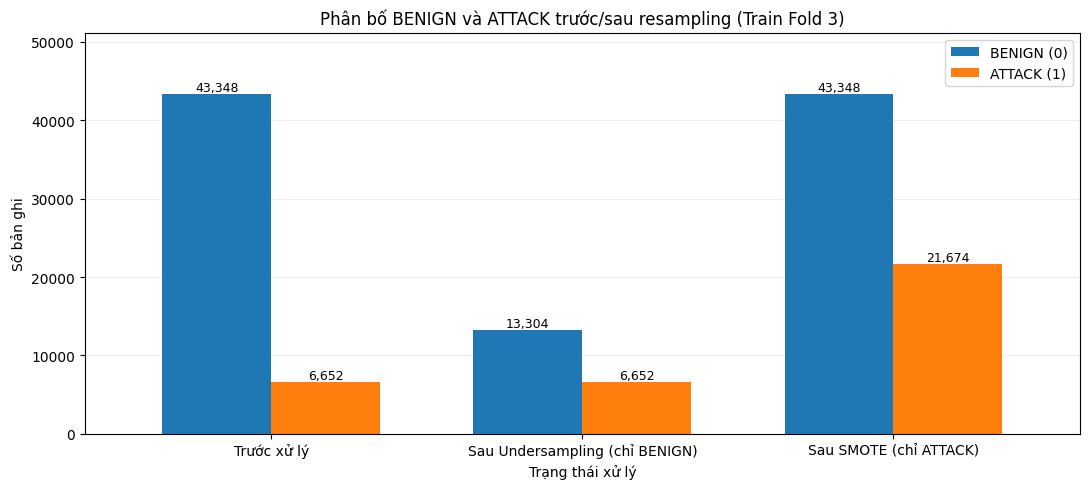

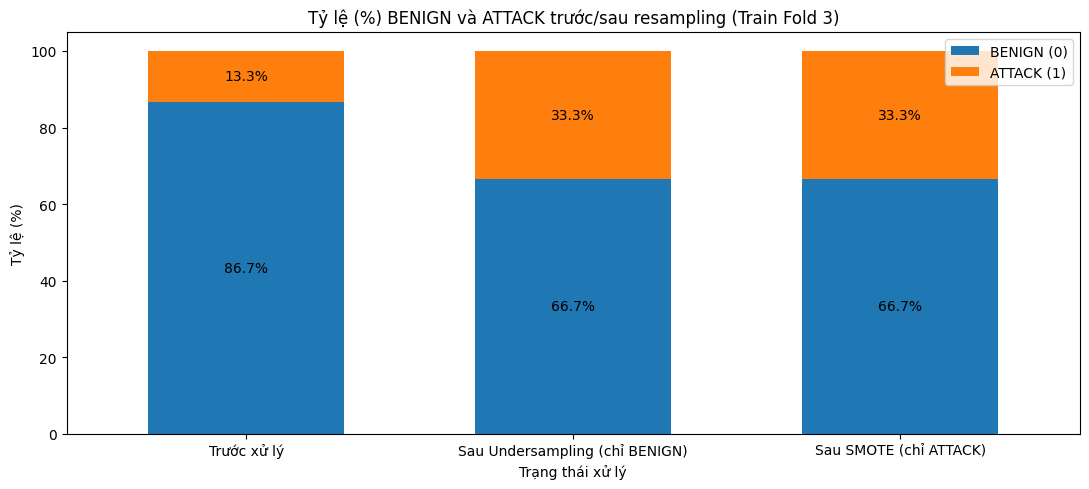

Đã lưu bảng phân bố: /content/drive/MyDrive/ThucTap/processed/reports/fold3_train_class_distribution_before_after.csv
Đã lưu 2 biểu đồ PNG trong: /content/drive/MyDrive/ThucTap/processed/reports
Validation Friday không bị thay đổi: {'BENIGN (0)': 182856, 'ATTACK (1)': 68407}


In [20]:
# Thống kê và biểu đồ phân bố lớp TRƯỚC/SAU resampling
# Chỉ fit sampler trên X_train_proto, y_train_proto.
# KHÔNG chạy SMOTE/Undersampling trên Friday validation hoặc outer test.
import matplotlib.pyplot as plt

# Đếm chính xác nhãn 0 và 1 từ kết quả thực tế của sampler.
def class_counts(y_values):
    y_arr = np.asarray(y_values)
    return {
        'BENIGN (0)': int(np.sum(y_arr == 0)),
        'ATTACK (1)': int(np.sum(y_arr == 1)),
    }

before = class_counts(y_train_proto)
count_dict = {
    'Trước xử lý': before,
}

for mode, caption in [
    ('undersampling', 'Sau Undersampling (chỉ BENIGN)'),
    ('smote', 'Sau SMOTE (chỉ ATTACK)'),
]:
    # Lấy phần tiền xử lý + sampler, bỏ estimator LogisticRegression.
    # .fit_resample() chỉ sử dụng phần TRAIN; scaler cũng được fit trên train.
    prep = build_lr_pipeline(mode, y_train_proto, seed=SEED)[:-1]
    X_resampled, y_resampled = prep.fit_resample(X_train_proto, y_train_proto)
    count_dict[caption] = class_counts(y_resampled)
    del prep, X_resampled, y_resampled
    gc.collect()

class_distribution = pd.DataFrame.from_dict(count_dict, orient='index')
class_distribution['Tổng số dòng'] = (
    class_distribution['BENIGN (0)'] + class_distribution['ATTACK (1)']
)
class_distribution['ATTACK (%)'] = (
    100 * class_distribution['ATTACK (1)'] / class_distribution['Tổng số dòng']
).round(2)

print('BẢNG PHÂN BỐ CỦA RIÊNG TẬP TRAIN PROTOTYPE (FOLD 3):')
display(class_distribution)

# Khẳng định đúng lớp thay đổi
assert (class_distribution.loc['Sau Undersampling (chỉ BENIGN)', 'ATTACK (1)']
        == before['ATTACK (1)']), 'Undersampling đã làm thay đổi ATTACK!'
assert (class_distribution.loc['Sau SMOTE (chỉ ATTACK)', 'BENIGN (0)']
        == before['BENIGN (0)']), 'SMOTE đã làm thay đổi BENIGN!'
assert (class_distribution.loc['Sau Undersampling (chỉ BENIGN)', 'BENIGN (0)']
        < before['BENIGN (0)'])
assert (class_distribution.loc['Sau SMOTE (chỉ ATTACK)', 'ATTACK (1)']
        > before['ATTACK (1)'])
print('Kiểm tra OK: Undersampling chỉ giảm BENIGN; SMOTE chỉ tăng ATTACK.')

# BIỂU ĐỒ 1: số lượng tuyệt đối trước/sau
counts_for_plot = class_distribution[['BENIGN (0)', 'ATTACK (1)']]
ax = counts_for_plot.plot(kind='bar', figsize=(11, 5), rot=0, width=0.7)
ax.set_title('Phân bố BENIGN và ATTACK trước/sau resampling (Train Fold 3)')
ax.set_ylabel('Số bản ghi')
ax.set_xlabel('Trạng thái xử lý')
ax.set_ylim(0, max(before['BENIGN (0)'],
                   class_distribution['ATTACK (1)'].max()) * 1.18)
ax.grid(axis='y', alpha=0.2)
ax.set_axisbelow(True)
for bar in ax.patches:
    height = bar.get_height()
    ax.annotate(f'{height:,.0f}',
                (bar.get_x() + bar.get_width() / 2, height),
                ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.savefig(REPORT_DIR / 'fold3_class_distribution_counts.png', dpi=180, bbox_inches='tight')
plt.show()

# BIỂU ĐỒ 2: tỷ lệ phần trăm trước/sau
proportions = counts_for_plot.div(counts_for_plot.sum(axis=1), axis=0) * 100
ax = proportions.plot(kind='bar', stacked=True, figsize=(11, 5), rot=0, width=0.6)
ax.set_title('Tỷ lệ (%) BENIGN và ATTACK trước/sau resampling (Train Fold 3)')
ax.set_ylabel('Tỷ lệ (%)')
ax.set_xlabel('Trạng thái xử lý')
ax.set_ylim(0, 105)
ax.legend(loc='upper right')
for i, (_, row) in enumerate(proportions.iterrows()):
    bottom = 0.0
    for value in row:
        ax.text(i, bottom + value / 2, f'{value:.1f}%',
                ha='center', va='center', fontsize=10)
        bottom += value
plt.tight_layout()
plt.savefig(REPORT_DIR / 'fold3_class_distribution_percent.png', dpi=180, bbox_inches='tight')
plt.show()

count_report_path = REPORT_DIR / 'fold3_train_class_distribution_before_after.csv'
class_distribution.to_csv(count_report_path, encoding='utf-8-sig')
print('Đã lưu bảng phân bố:', count_report_path)
print('Đã lưu 2 biểu đồ PNG trong:', REPORT_DIR)
print('Validation Friday không bị thay đổi:', class_counts(y_temporal_val))

In [21]:
# Huấn luyện Logistic Regression và so sánh bốn cấu hình
results = []
THRESHOLD = 0.5

for mode in modes:
    print('\n' + '=' * 75)
    print('Đang huấn luyện:', mode)
    print('=' * 75)

    pipeline = build_lr_pipeline(mode, y_train_proto, seed=SEED)
    started = time.perf_counter()

    pipeline.fit(X_train_proto, y_train_proto)
    fit_seconds = time.perf_counter() - started

    # Khi predict_proba: chỉ transform bằng scaler; KHÔNG resample validation.
    p_classes = pipeline.named_steps['model'].classes_
    positive_index = int(np.where(p_classes == 1)[0][0])
    predict_started = time.perf_counter()
    attack_score = pipeline.predict_proba(X_temporal_val)[:, positive_index]
    predict_seconds = time.perf_counter() - predict_started
    predicted = (attack_score >= THRESHOLD).astype(np.int8)

    tn, fp, fn, tp = confusion_matrix(
        y_temporal_val, predicted, labels=[0, 1]
    ).ravel()

    # Số lượng train thực tế được model nhìn thấy sau resampling.
    if mode == 'undersampling':
        effective_counts = class_distribution.loc['Sau Undersampling (chỉ BENIGN)']
    elif mode == 'smote':
        effective_counts = class_distribution.loc['Sau SMOTE (chỉ ATTACK)']
    else:
        effective_counts = class_distribution.loc['Trước xử lý']

    results.append({
        'Model': 'LR-' + mode,
        'Train_rows_before': len(y_train_proto),
        'Train_rows_after': int(effective_counts['Tổng số dòng']),
        'Train_BENIGN_after': int(effective_counts['BENIGN (0)']),
        'Train_ATTACK_after': int(effective_counts['ATTACK (1)']),
        'Val_rows': len(y_temporal_val),
        'Accuracy': accuracy_score(y_temporal_val, predicted),
        'Precision_Attack': precision_score(y_temporal_val, predicted, zero_division=0),
        'Recall_Attack': recall_score(y_temporal_val, predicted, zero_division=0),
        'F1_Attack': f1_score(y_temporal_val, predicted, zero_division=0),
        'FPR': fp / (fp + tn) if fp + tn else np.nan,
        'FNR': fn / (fn + tp) if fn + tp else np.nan,
        'ROC_AUC': roc_auc_score(y_temporal_val, attack_score),
        'Average_Precision': average_precision_score(y_temporal_val, attack_score),
        'TN': int(tn), 'FP': int(fp), 'FN': int(fn), 'TP': int(tp),
        'Train_seconds': round(fit_seconds, 2),
        'Predict_seconds': round(predict_seconds, 2),
        'Threshold': THRESHOLD
    })

    print(f'F1 Attack: {results[-1]["F1_Attack"]:.4f}')
    print(f'Recall: {results[-1]["Recall_Attack"]:.4f}')
    print(f'FPR: {results[-1]["FPR"]:.4f}')
    print(f'Average Precision: {results[-1]["Average_Precision"]:.4f}')
    print(f'Train: {fit_seconds:.1f}s | Predict: {predict_seconds:.1f}s')

    del pipeline, attack_score, predicted
    gc.collect()

results_df = pd.DataFrame(results)
print('\nSO SÁNH BỐN CẤU HÌNH — FOLD 3 (FRIDAY)')
display(results_df.round(4))

report_path = REPORT_DIR / 'lr_prototype_fold3_imbalance_comparison.csv'
results_df.to_csv(report_path, index=False)
print('Đã lưu:', report_path)
print('Thử nghiệm sơ bộ một fold; chưa đánh giá outer validation/test.')



Đang huấn luyện: original
F1 Attack: 0.9839
Recall: 0.9758
FPR: 0.0029
Average Precision: 0.9899
Train: 2.6s | Predict: 0.2s

Đang huấn luyện: weighted
F1 Attack: 0.9808
Recall: 0.9795
FPR: 0.0067
Average Precision: 0.9907
Train: 5.1s | Predict: 0.5s

Đang huấn luyện: undersampling
F1 Attack: 0.9808
Recall: 0.9787
FPR: 0.0064
Average Precision: 0.9878
Train: 2.2s | Predict: 0.3s

Đang huấn luyện: smote
F1 Attack: 0.9842
Recall: 0.9790
FPR: 0.0039
Average Precision: 0.9904
Train: 6.0s | Predict: 0.3s

SO SÁNH BỐN CẤU HÌNH — FOLD 3 (FRIDAY)


,Model,Train_rows_before,Train_rows_after,Train_BENIGN_after,Train_ATTACK_after,Val_rows,Accuracy,Precision_Attack,Recall_Attack,F1_Attack,FPR,FNR,ROC_AUC,Average_Precision,TN,FP,FN,TP,Train_seconds,Predict_seconds,Threshold
0,LR-original,50000,50000,43348,6652,251263,0.9913,0.9921,0.9758,0.9839,0.0029,0.0242,0.9900,0.9899,182326,530,1655,66752,2.65,0.25,0.5
1,LR-weighted,50000,50000,43348,6652,251263,0.9896,0.9821,0.9795,0.9808,0.0067,0.0205,0.9928,0.9907,181636,1220,1403,67004,5.08,0.47,0.5
2,LR-undersampling,50000,19956,13304,6652,251263,0.9896,0.9829,0.9787,0.9808,0.0064,0.0213,0.9922,0.9878,181693,1163,1460,66947,2.17,0.30,0.5
3,LR-smote,50000,65022,43348,21674,251263,0.9914,0.9894,0.9790,0.9842,0.0039,0.0210,0.9916,0.9904,182136,720,1437,66970,6.04,0.35,0.5


Đã lưu: /content/drive/MyDrive/ThucTap/processed/reports/lr_prototype_fold3_imbalance_comparison.csv
Thử nghiệm sơ bộ một fold; chưa đánh giá outer validation/test.


In [22]:
# ĐỌC TRAIN 70% VÀ TẢI 3 TEMPORAL FOLDS
import json
import time
import gc
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_auc_score, average_precision_score
)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE

SEED = 42
N_TRAIN_PER_FOLD = 50_000  # thí nghiệm ban đầu; sau đó tăng lên hoặc dùng toàn bộ train
THRESHOLD = 0.5
BASE_DIR = Path('/content/drive/MyDrive/ThucTap/processed')
SPLIT_DIR = BASE_DIR / 'splits'
REPORT_DIR = BASE_DIR / 'reports'
REPORT_DIR.mkdir(parents=True, exist_ok=True)

with open(BASE_DIR / 'feature_columns.json', encoding='utf-8') as f:
    feature_cols = json.load(f)['feature_columns']

# Đọc duy nhất outer TRAIN; KHÔNG đọc validation15/test15
train70 = pd.read_parquet(
    SPLIT_DIR / 'train70.parquet',
    columns=feature_cols + ['target', '_source_file']
)
y_all = train70['target'].to_numpy(dtype=np.int8)

with np.load(SPLIT_DIR / 'temporal_folds_train70.npz') as z:
    folds = {
        name: (z[f'{name}_train_pos'].copy(), z[f'{name}_val_pos'].copy())
        for name in ['fold1', 'fold2', 'fold3']
    }

DAY_ORDER = ['monday', 'tuesday', 'wednesday', 'thursday', 'friday']
def get_day_code(source_file):
    matches = [i for i, d in enumerate(DAY_ORDER) if d in str(source_file).lower()]
    if len(matches) != 1:
        raise ValueError(f'Không đọc được ngày của: {source_file}')
    return matches[0]

source_to_day = {
    v: get_day_code(v) for v in train70['_source_file'].unique()
}
all_day_codes = train70['_source_file'].map(source_to_day).to_numpy()

for fold_name, (tr_idx, va_idx) in folds.items():
    assert len(np.intersect1d(tr_idx, va_idx)) == 0
    assert set(np.unique(y_all[tr_idx])) == {0, 1}
    assert set(np.unique(y_all[va_idx])) == {0, 1}
    assert all_day_codes[tr_idx].max() < all_day_codes[va_idx].min()
    print(f'{fold_name}: Train {len(tr_idx):,} dòng, '
          f'Val {len(va_idx):,} dòng | ATTACK: '
          f'{y_all[tr_idx].mean():.2%} / {y_all[va_idx].mean():.2%}')

assert 'Label' not in feature_cols
assert 'target' not in feature_cols and '_source_file' not in feature_cols
print(f'\nĐã đọc {len(train70):,} dòng, {len(feature_cols)} đặc trưng.')


fold1: Train 460,665 dòng, Val 321,685 dòng | ATTACK: 1.05% / 37.36%
fold2: Train 782,350 dòng, Val 182,667 dòng | ATTACK: 15.98% / 1.85%
fold3: Train 965,017 dòng, Val 251,263 dòng | ATTACK: 13.30% / 27.23%

Đã đọc 1,216,280 dòng, 82 đặc trưng.


In [23]:
# CELL 6.2 — 12 THÍ NGHIỆM: 4 CẤU HÌNH x 3 TEMPORAL FOLDS
# Chỉ giảm BENIGN khi Undersampling; chỉ tăng ATTACK khi SMOTE.
# ratio = số ATTACK / số BENIGN SAU resampling.

CONFIGS = [
    ('LR-Original', 'original', None),
    ('LR-Weighted', 'weighted', None),
    ('LR-Under-0.5', 'undersampling', 0.5),
    ('LR-SMOTE-0.5', 'smote', 0.5),
]

def make_pipeline(mode, y_train, ratio=None):
    n0 = int(np.sum(y_train == 0))
    n1 = int(np.sum(y_train == 1))
    if n0 <= 0 or n1 <= 0:
        raise ValueError('Tập train phải có cả BENIGN (0) và ATTACK (1).')

    steps = [('scaler', StandardScaler())]
    # Dạng dictionary bảo đảm chính xác lớp muốn thay đổi
    if mode == 'undersampling':
        wanted_benign = int(np.ceil(n1 / ratio))
        if wanted_benign > n0:
            raise ValueError('Không thể giảm BENIGN đến tỷ lệ yêu cầu.')
        if wanted_benign < n0:
            steps.append(('sampler', RandomUnderSampler(
                sampling_strategy={0: wanted_benign}, random_state=SEED
            )))
        after0, after1 = wanted_benign, n1
    elif mode == 'smote':
        wanted_attack = int(np.ceil(n0 * ratio))
        if wanted_attack < n1:
            raise ValueError('Không thể SMOTE: ATTACK đã vượt mục tiêu.')
        if wanted_attack > n1:
            if n1 < 4:
                raise ValueError('SMOTE(k_neighbors=3) cần >=4 ATTACK trong train.')
            steps.append(('sampler', SMOTE(
                sampling_strategy={1: wanted_attack},
                random_state=SEED, k_neighbors=3
            )))
        after0, after1 = n0, wanted_attack
    else:
        after0, after1 = n0, n1

    steps.append(('model', LogisticRegression(
        C=1.0, solver='lbfgs', max_iter=350,
        class_weight='balanced' if mode == 'weighted' else None,
        random_state=SEED
    )))
    return ImbPipeline(steps), after0, after1

experiment_rows = []
distribution_rows = []
results_path = REPORT_DIR / 'lr_temporal_3fold_4configs_05.csv'
dist_path = REPORT_DIR / 'lr_temporal_3fold_distribution_05.csv'

for fold_name, (full_train_pos, val_pos) in folds.items():
    print(f'\n{"="*75}\n{fold_name.upper()}\n{"="*75}')
    # Cùng mẫu train và cùng validation được dùng cho tất cả 4 cấu hình
    if len(full_train_pos) > N_TRAIN_PER_FOLD:
        sample_pos, _ = train_test_split(
            full_train_pos, train_size=N_TRAIN_PER_FOLD,
            stratify=y_all[full_train_pos], random_state=SEED
        )
    else:
        sample_pos = full_train_pos

    # float32 tiết kiệm RAM trên Google Colab
    X_tr = train70.iloc[sample_pos][feature_cols].to_numpy(dtype=np.float32)
    y_tr = y_all[sample_pos]
    X_va = train70.iloc[val_pos][feature_cols].to_numpy(dtype=np.float32)
    y_va = y_all[val_pos]
    assert np.isfinite(X_tr).all() and np.isfinite(X_va).all()
    n0, n1 = int((y_tr == 0).sum()), int((y_tr == 1).sum())

    print(f'Train prototype: {len(y_tr):,} | BENIGN={n0:,}, ATTACK={n1:,}')
    print(f'Temporal validation: {len(y_va):,} | Attack={y_va.mean():.2%}')

    for label, mode, ratio in CONFIGS:
        print(f'  Đang chạy {label} ...', end=' ', flush=True)
        pipeline, after0, after1 = make_pipeline(mode, y_tr, ratio)
        started = time.perf_counter()
        pipeline.fit(X_tr, y_tr) # scaler và sampler CHỈ fit trên train fold
        fit_s = time.perf_counter() - started

        score_idx = int(np.flatnonzero(
            pipeline.named_steps['model'].classes_ == 1
        )[0])
        started = time.perf_counter()
        scores = pipeline.predict_proba(X_va)[:, score_idx]
        pred_s = time.perf_counter() - started
        pred = (scores >= THRESHOLD).astype(np.int8)

        tn, fp, fn, tp = confusion_matrix(y_va, pred, labels=[0, 1]).ravel()
        experiment_rows.append({
            'Fold': fold_name, 'Config': label, 'Ratio': ratio,
            'Train_Before': len(y_tr), 'Train_After': after0+after1,
            'Train_BENIGN_After': after0, 'Train_ATTACK_After': after1,
            'Val_Rows': len(y_va), 'Val_ATTACK_Rate': float(y_va.mean()),
            'Accuracy': accuracy_score(y_va, pred),
            'Precision_Attack': precision_score(y_va, pred, zero_division=0),
            'Recall_Attack': recall_score(y_va, pred, zero_division=0),
            'F1_Attack': f1_score(y_va, pred, zero_division=0),
            'FPR': fp / (fp + tn) if fp + tn else np.nan,
            'FNR': fn / (fn + tp) if fn + tp else np.nan,
            'ROC_AUC': roc_auc_score(y_va, scores),
            'Average_Precision': average_precision_score(y_va, scores),
            'TN': int(tn), 'FP': int(fp), 'FN': int(fn), 'TP': int(tp),
            'Train_seconds': round(fit_s, 2),
            'Predict_seconds': round(pred_s, 2),
            'Threshold': THRESHOLD,
        })
        distribution_rows.append({
            'Fold': fold_name, 'Config': label,
            'BENIGN': after0, 'ATTACK': after1,
            'Total': after0+after1,
            'ATTACK_Percent': 100*after1/(after0+after1)
        })
        print(f'F1={experiment_rows[-1]["F1_Attack"]:.4f} '
              f'Recall={experiment_rows[-1]["Recall_Attack"]:.4f} '
              f'FPR={experiment_rows[-1]["FPR"]:.4f}')
        # Lưu sau từng lần fit đề phòng Colab bị ngắt
        pd.DataFrame(experiment_rows).to_csv(results_path, index=False)
        pd.DataFrame(distribution_rows).to_csv(dist_path, index=False)
        del pipeline, scores, pred
        gc.collect()

    del X_tr, y_tr, X_va, y_va
    gc.collect()

results_temporal = pd.DataFrame(experiment_rows)
dist_temporal = pd.DataFrame(distribution_rows)
print('\nKẾT QUẢ 12 THÍ NGHIỆM:')
display(results_temporal.round(4))
print('Đã lưu:', results_path)
print('Đã lưu:', dist_path)



FOLD1
Train prototype: 50,000 | BENIGN=49,475, ATTACK=525
Temporal validation: 321,685 | Attack=37.36%
  Đang chạy LR-Original ... F1=0.0000 Recall=0.0000 FPR=0.0002
  Đang chạy LR-Weighted ... F1=0.0000 Recall=0.0000 FPR=0.0003
  Đang chạy LR-Under-0.5 ... F1=0.0000 Recall=0.0000 FPR=0.0025
  Đang chạy LR-SMOTE-0.5 ... F1=0.0000 Recall=0.0000 FPR=0.0004

FOLD2
Train prototype: 50,000 | BENIGN=42,011, ATTACK=7,989
Temporal validation: 182,667 | Attack=1.85%
  Đang chạy LR-Original ... F1=0.3325 Recall=0.2132 FPR=0.0013
  Đang chạy LR-Weighted ... F1=0.5361 Recall=0.4628 FPR=0.0050
  Đang chạy LR-Under-0.5 ... F1=0.5972 Recall=0.5271 FPR=0.0045
  Đang chạy LR-SMOTE-0.5 ... F1=0.4288 Recall=0.3225 FPR=0.0034

FOLD3
Train prototype: 50,000 | BENIGN=43,348, ATTACK=6,652
Temporal validation: 251,263 | Attack=27.23%
  Đang chạy LR-Original ... F1=0.9839 Recall=0.9757 FPR=0.0029
  Đang chạy LR-Weighted ... F1=0.9808 Recall=0.9795 FPR=0.0067
  Đang chạy LR-Under-0.5 ... F1=0.9807 Recall=0.978

,Fold,Config,Ratio,Train_Before,Train_After,Train_BENIGN_After,Train_ATTACK_After,Val_Rows,Val_ATTACK_Rate,Accuracy,Precision_Attack,Recall_Attack,F1_Attack,FPR,FNR,ROC_AUC,Average_Precision,TN,FP,FN,TP,Train_seconds,Predict_seconds,Threshold
0,fold1,LR-Original,NaN,50000,50000,49475,525,321685,0.3736,0.6263,0.0000,0.0000,0.0000,0.0002,1.0000,0.0186,0.2176,201483,32,120170,0,1.06,0.62,0.5
1,fold1,LR-Weighted,NaN,50000,50000,49475,525,321685,0.3736,0.6262,0.0000,0.0000,0.0000,0.0003,1.0000,0.0133,0.2167,201445,70,120170,0,1.55,0.62,0.5
2,fold1,LR-Under-0.5,0.5,50000,1575,1050,525,321685,0.3736,0.6248,0.0000,0.0000,0.0000,0.0025,1.0000,0.0136,0.2162,201002,513,120170,0,0.20,0.56,0.5
3,fold1,LR-SMOTE-0.5,0.5,50000,74213,49475,24738,321685,0.3736,0.6262,0.0000,0.0000,0.0000,0.0004,1.0000,0.0149,0.2170,201435,80,120170,0,1.44,0.54,0.5
4,fold2,LR-Original,NaN,50000,50000,42011,7989,182667,0.0185,0.9842,0.7547,0.2132,0.3325,0.0013,0.7868,0.8912,0.5005,179056,234,2657,720,2.98,0.22,0.5
5,fold2,LR-Weighted,NaN,50000,50000,42011,7989,182667,0.0185,0.9852,0.6369,0.4628,0.5361,0.0050,0.5372,0.8918,0.5417,178399,891,1814,1563,1.96,0.22,0.5
6,fold2,LR-Under-0.5,0.5,50000,23967,15978,7989,182667,0.0185,0.9869,0.6889,0.5271,0.5972,0.0045,0.4729,0.9162,0.5818,178486,804,1597,1780,0.78,0.19,0.5
7,fold2,LR-SMOTE-0.5,0.5,50000,63017,42011,21006,182667,0.0185,0.9841,0.6398,0.3225,0.4288,0.0034,0.6775,0.8904,0.5136,178677,613,2288,1089,2.82,0.20,0.5
8,fold3,LR-Original,NaN,50000,50000,43348,6652,251263,0.2723,0.9913,0.9922,0.9757,0.9839,0.0029,0.0243,0.9898,0.9898,182332,524,1662,66745,3.14,0.37,0.5
9,fold3,LR-Weighted,NaN,50000,50000,43348,6652,251263,0.2723,0.9896,0.9821,0.9795,0.9808,0.0067,0.0205,0.9924,0.9905,181637,1219,1401,67006,3.55,0.26,0.5


Đã lưu: /content/drive/MyDrive/ThucTap/processed/reports/lr_temporal_3fold_4configs_05.csv
Đã lưu: /content/drive/MyDrive/ThucTap/processed/reports/lr_temporal_3fold_distribution_05.csv


TRUNG BÌNH ĐỀU 3 TEMPORAL FOLDS (THAM KHẢO CHỌN ỨNG VIÊN):


,F1_Attack,Recall_Attack,Precision_Attack,FPR,FNR,Average_Precision,ROC_AUC
Config,,,,,,,
LR-Under-0.5,0.5260,0.5019,0.5572,0.0045,0.4981,0.5952,0.6406
LR-Weighted,0.5056,0.4808,0.5397,0.0040,0.5192,0.5830,0.6325
LR-SMOTE-0.5,0.4709,0.4338,0.5429,0.0026,0.5662,0.5736,0.6320
LR-Original,0.4388,0.3963,0.5823,0.0014,0.6037,0.5693,0.6332


F1 CHI TIẾT TỪNG FOLD:


Config,LR-Original,LR-SMOTE-0.5,LR-Under-0.5,LR-Weighted
Fold,,,,
fold1,0.0000,0.0000,0.0000,0.0000
fold2,0.3325,0.4288,0.5972,0.5361
fold3,0.9839,0.9838,0.9807,0.9808


FPR CHI TIẾT TỪNG FOLD:


Config,LR-Original,LR-SMOTE-0.5,LR-Under-0.5,LR-Weighted
Fold,,,,
fold1,0.0002,0.0004,0.0025,0.0003
fold2,0.0013,0.0034,0.0045,0.0050
fold3,0.0029,0.0041,0.0064,0.0067


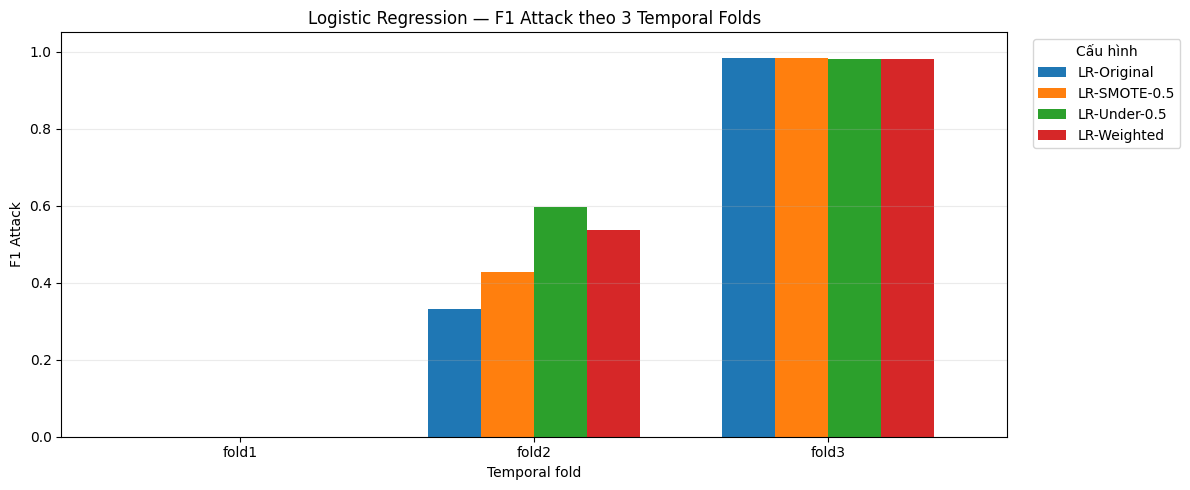

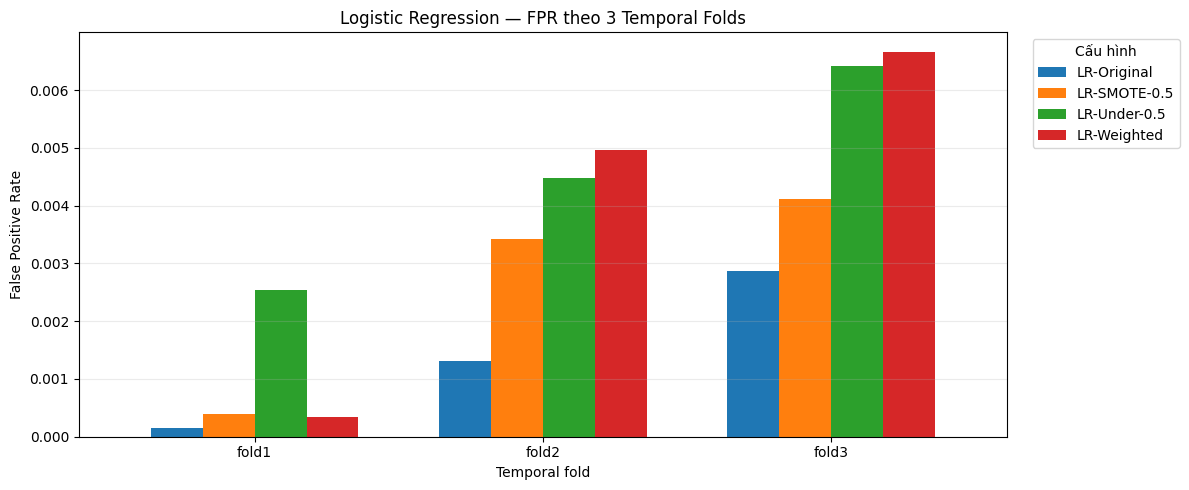

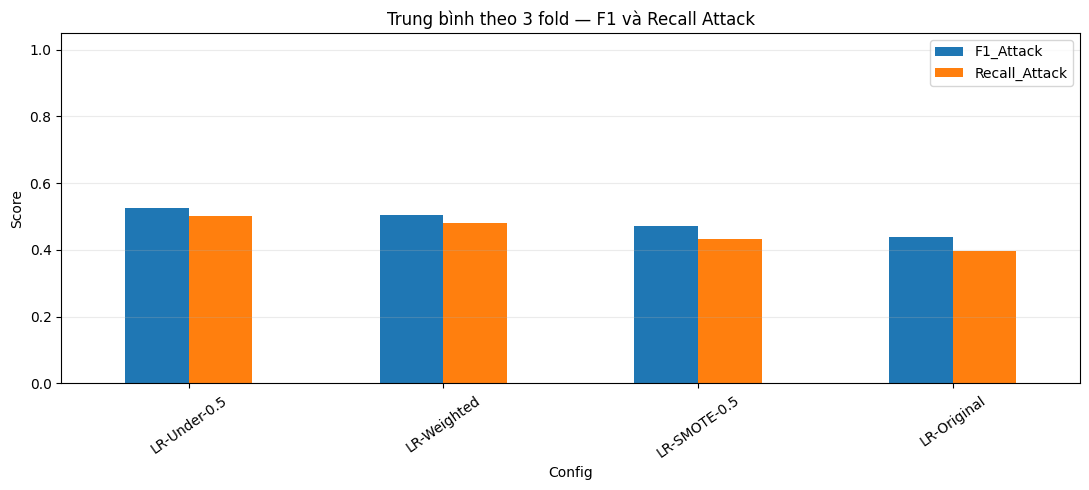

Ứng viên có F1 trung bình cao nhất: LR-Under-0.5
Chưa dùng Test 15% và chưa chốt mô hình cuối cùng.
Kiểm tra cả FPR/FNR theo từng ngày trước khi chọn.


In [24]:
# BẢNG TỔNG HỢP, BIỂU ĐỒ, CHỌN ỨNG VIÊN
# Có thể chạy lại cell này mà không cần train lại 12 mô hình.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# Luôn đọc đúng file 4 cấu hình 0.5 đã tạo ở Cell 6.2.
# Tránh dùng nhầm DataFrame cũ còn trong RAM.
results_temporal = pd.read_csv(
    '/content/drive/MyDrive/ThucTap/processed/reports/lr_temporal_3fold_4configs_05.csv'
)

expected_folds = {'fold1', 'fold2', 'fold3'}
expected_configs = {'LR-Original', 'LR-Weighted',
                    'LR-Under-0.5', 'LR-SMOTE-0.5'}
assert set(results_temporal['Fold']) == expected_folds
assert set(results_temporal['Config']) == expected_configs
assert not results_temporal.duplicated(['Fold', 'Config']).any()

metric_cols = [
    'F1_Attack', 'Recall_Attack', 'Precision_Attack',
    'FPR', 'FNR', 'Average_Precision', 'ROC_AUC'
]
# Macro trung bình theo FOLD, không theo số lượng bản ghi.
# Mỗi ngày validation có tỷ lệ ATTACK khác nhau.
summary = (results_temporal.groupby('Config')[metric_cols]
           .mean().sort_values(['F1_Attack', 'FPR'], ascending=[False, True]))
print('TRUNG BÌNH ĐỀU 3 TEMPORAL FOLDS (THAM KHẢO CHỌN ỨNG VIÊN):')
display(summary.round(4))

print('F1 CHI TIẾT TỪNG FOLD:')
f1_by_fold = results_temporal.pivot(index='Fold', columns='Config', values='F1_Attack')
display(f1_by_fold.round(4))

print('FPR CHI TIẾT TỪNG FOLD:')
fpr_by_fold = results_temporal.pivot(index='Fold', columns='Config', values='FPR')
display(fpr_by_fold.round(4))

# Biểu đồ 1: F1 theo từng temporal fold
ax = f1_by_fold.plot(kind='bar', figsize=(12, 5), rot=0, width=0.72)
ax.set_title('Logistic Regression — F1 Attack theo 3 Temporal Folds')
ax.set_ylabel('F1 Attack')
ax.set_xlabel('Temporal fold')
ax.set_ylim(0, 1.05)
ax.grid(axis='y', alpha=0.25)
ax.legend(title='Cấu hình', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.savefig(REPORT_DIR / 'lr_temporal_f1_3fold.png', dpi=180, bbox_inches='tight')
plt.show()

# Biểu đồ 2: FPR theo từng temporal fold
ax = fpr_by_fold.plot(kind='bar', figsize=(12, 5), rot=0, width=0.72)
ax.set_title('Logistic Regression — FPR theo 3 Temporal Folds')
ax.set_ylabel('False Positive Rate')
ax.set_xlabel('Temporal fold')
ax.grid(axis='y', alpha=0.25)
ax.legend(title='Cấu hình', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.savefig(REPORT_DIR / 'lr_temporal_fpr_3fold.png', dpi=180, bbox_inches='tight')
plt.show()

# Biểu đồ 3: F1 và Recall trung bình từng fold
ax = summary[['F1_Attack', 'Recall_Attack']].plot(
    kind='bar', figsize=(11, 5), rot=35
)
ax.set_title('Trung bình theo 3 fold — F1 và Recall Attack')
ax.set_ylabel('Score')
ax.set_ylim(0, 1.05)
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.savefig(REPORT_DIR / 'lr_temporal_mean_f1_recall.png', dpi=180, bbox_inches='tight')
plt.show()

summary.to_csv(REPORT_DIR / 'lr_temporal_3fold_mean_metrics_05.csv', encoding='utf-8-sig')
print('Ứng viên có F1 trung bình cao nhất:', summary.index[0])
print('Chưa dùng Test 15% và chưa chốt mô hình cuối cùng.')
print('Kiểm tra cả FPR/FNR theo từng ngày trước khi chọn.')

In [25]:
!pip -q install imbalanced-learn joblib pyarrow

import gc, json, time, sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import sklearn, imblearn
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score,
    precision_recall_curve, roc_curve
)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler

SEED_B7 = 42
BASE_B7 = Path('/content/drive/MyDrive/ThucTap/processed')
SPLIT_B7 = BASE_B7 / 'splits'
REPORT_B7 = BASE_B7 / 'reports'
MODEL_B7 = BASE_B7 / 'models'
REPORT_B7.mkdir(parents=True, exist_ok=True)
MODEL_B7.mkdir(parents=True, exist_ok=True)

with open(BASE_B7 / 'feature_columns.json', encoding='utf-8') as f:
    FEATURE_B7 = json.load(f)['feature_columns']
assert len(FEATURE_B7) == 82
assert not ({'Label','target','_source_file'} & set(FEATURE_B7))

needed_b7 = FEATURE_B7 + ['target']
train_b7_df = pd.read_parquet(SPLIT_B7 / 'train70.parquet', columns=needed_b7)
valid_b7_df = pd.read_parquet(
    SPLIT_B7 / 'validation15.parquet',
    columns=FEATURE_B7 + ['target','Label','_source_file']
)
assert train_b7_df['target'].isin([0,1]).all()
assert valid_b7_df['target'].isin([0,1]).all()
assert set(train_b7_df.columns) == set(needed_b7)
assert set(FEATURE_B7).issubset(valid_b7_df.columns)

# Luôn giữ thứ tự cột đã dùng khi train
X_train_b7 = train_b7_df[FEATURE_B7].to_numpy(dtype=np.float32)
y_train_b7 = train_b7_df['target'].to_numpy(dtype=np.int8, copy=True)
X_valid_b7 = valid_b7_df[FEATURE_B7].to_numpy(dtype=np.float32)
y_valid_b7 = valid_b7_df['target'].to_numpy(dtype=np.int8, copy=True)
valid_label_b7 = valid_b7_df['Label'].astype(str).to_numpy()
valid_source_b7 = valid_b7_df['_source_file'].astype(str).to_numpy()
del train_b7_df, valid_b7_df
gc.collect()

assert X_train_b7.shape == (len(y_train_b7), len(FEATURE_B7))
assert X_valid_b7.shape == (len(y_valid_b7), len(FEATURE_B7))
assert len(y_train_b7) == 1_216_280, 'Số dòng train khác kết quả Bước 4.'
assert len(y_valid_b7) == 260_631, 'Số dòng validation khác kết quả Bước 4.'
assert np.isfinite(X_train_b7).all(), 'Train có NaN/Inf hoặc float32 overflow'
assert np.isfinite(X_valid_b7).all(), 'Validation có NaN/Inf hoặc float32 overflow'

n0_b7 = int(np.count_nonzero(y_train_b7 == 0))
n1_b7 = int(np.count_nonzero(y_train_b7 == 1))
assert n0_b7 > n1_b7 > 0

print(f'Train: {len(y_train_b7):,} dòng; BENIGN={n0_b7:,}, ATTACK={n1_b7:,}')
print(f'Validation: {len(y_valid_b7):,} dòng; ATTACK={sum(y_valid_b7==1):,}')
print(f'Features: {len(FEATURE_B7)}; X train ~{X_train_b7.nbytes/1024**2:.1f} MiB')
print('Không đọc hoặc sử dụng Test 15%.')

Train: 1,216,280 dòng; BENIGN=1,019,490, ATTACK=196,790
Validation: 260,631 dòng; ATTACK=42,169
Features: 82; X train ~380.5 MiB
Không đọc hoặc sử dụng Test 15%.


In [26]:
configs_b7 = [
    ('LR-Original', None),
    ('LR-Under-0.5', 0.5),
]
# Chốt tỷ lệ xử lý mất cân bằng: ATTACK / BENIGN = 0.5.
assert all(ratio is None or ratio == 0.5 for _, ratio in configs_b7)
models_b7 = {}
scores_b7 = {}
training_b7 = []

for model_name, under_ratio in configs_b7:
    steps = [('scaler', StandardScaler())]
    if under_ratio is not None:
        # Chỉ GIẢM BENIGN (0), GIỮ NGUYÊN ATTACK (1)
        target_benign = int(np.ceil(n1_b7 / under_ratio))
        assert target_benign <= n0_b7
        steps.append(('sampler', RandomUnderSampler(
            sampling_strategy={0: target_benign},
            random_state=SEED_B7
        )))

    steps.append(('model', LogisticRegression(
        C=1.0, solver='lbfgs', max_iter=350,
        class_weight=None, random_state=SEED_B7
    )))
    pipe = ImbPipeline(steps)

    print('\n' + '=' * 70)
    print('HUẤN LUYỆN:', model_name)
    start = time.perf_counter()
    with warnings.catch_warnings(record=True) as captured:
        warnings.simplefilter('always')
        pipe.fit(X_train_b7, y_train_b7)
    elapsed = time.perf_counter() - start
    for w in captured:
        print(f'Cảnh báo khi train: {w.message}')

    assert set(pipe.named_steps['model'].classes_) == {0, 1}
    p1_idx = int(np.flatnonzero(pipe.named_steps['model'].classes_ == 1)[0])
    # Validation chỉ đi qua scaler đã fit, sampler KHÔNG thay đổi số dòng
    p1 = pipe.predict_proba(X_valid_b7)[:, p1_idx]
    assert len(p1) == len(y_valid_b7)
    assert np.isfinite(p1).all()

    # Xác nhận sampler chỉ giảm lớp 0
    if under_ratio is not None:
        kept = pipe.named_steps['sampler'].sample_indices_
        y_after = y_train_b7[kept]
        assert int((y_after == 1).sum()) == n1_b7
        assert int((y_after == 0).sum()) == target_benign
        after0, after1 = target_benign, n1_b7
    else:
        after0, after1 = n0_b7, n1_b7

    models_b7[model_name] = pipe
    scores_b7[model_name] = p1
    training_b7.append({
        'Model': model_name,
        'Train_before': len(y_train_b7),
        'Train_BENIGN_after': after0,
        'Train_ATTACK_after': after1,
        'Train_after': after0 + after1,
        'Seconds': round(elapsed, 2)
    })
    model_filename = ('lr_original_fulltrain.joblib' if under_ratio is None
                      else 'lr_under_05_fulltrain.joblib')
    joblib.dump(pipe, MODEL_B7 / model_filename, compress=3)
    print(f'Sau resampling: BENIGN={after0:,}, ATTACK={after1:,}')
    print(f'Thời gian train: {elapsed:.1f} giây; Đã lưu {model_filename}')
    gc.collect()

distribution_b7 = pd.DataFrame(training_b7)
display(distribution_b7)
distribution_b7.to_csv(REPORT_B7 / 'lr_fulltrain_class_distribution.csv', index=False)


HUẤN LUYỆN: LR-Original
Cảnh báo khi train: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
Cảnh báo khi train: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
Sau resampling: BENIGN=1,019,490, ATTACK=196,790
Thời gian train: 135.6 giây; Đã lưu lr_original_fulltrain.joblib

HUẤN LUYỆN: LR-Under-0.5
Cảnh báo khi train: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
Cảnh báo khi train: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
Sau resampling: BENIGN=393,580, ATTACK=196,790
Thời gian train: 56.8 giây; Đã lưu lr_under_05_fulltrain.joblib


,Model,Train_before,Train_BENIGN_after,Train_ATTACK_after,Train_after,Seconds
0,LR-Original,1216280,1019490,196790,1216280,135.64
1,LR-Under-0.5,1216280,393580,196790,590370,56.77


In [27]:
# ĐÁNH GIÁ 0.5 + CHỌN THRESHOLD THEO VALIDATION 15%
# Ràng buộc minh họa FPR <= 1%. Chỉnh nếu đề tài cần mức cảnh báo giả khác.
FPR_LIMIT_B7 = 0.01
GRID_B7 = np.unique(np.r_[np.round(np.linspace(0.01, 0.99, 99), 2),
                              [0.995, 0.999, 1.0]])

def calculate_metrics_b7(y_true, p_attack, threshold):
    preds = (p_attack >= threshold).astype(np.int8)
    tn, fp, fn, tp = confusion_matrix(y_true, preds, labels=[0,1]).ravel()
    return {
        'Threshold': float(threshold),
        'Accuracy': accuracy_score(y_true, preds),
        'Precision_Attack': precision_score(y_true, preds, zero_division=0),
        'Recall_Attack': recall_score(y_true, preds, zero_division=0),
        'F1_Attack': f1_score(y_true, preds, zero_division=0),
        'FPR': fp/(fp+tn) if fp+tn else np.nan,
        'FNR': fn/(fn+tp) if fn+tp else np.nan,
        'TN': int(tn), 'FP': int(fp), 'FN': int(fn), 'TP': int(tp),
    }

fixed_rows_b7, tuning_rows_b7, chosen_rows_b7 = [], [], []
for model_name, _ in configs_b7:
    p = scores_b7[model_name]
    threshold_independent = {
        'ROC_AUC': roc_auc_score(y_valid_b7, p),
        'Average_Precision': average_precision_score(y_valid_b7, p)
    }
    fixed = {'Model': model_name, **calculate_metrics_b7(y_valid_b7,p,0.5),
             **threshold_independent}
    fixed_rows_b7.append(fixed)
    for threshold in GRID_B7:
        m = calculate_metrics_b7(y_valid_b7,p,float(threshold))
        tuning_rows_b7.append({'Model': model_name, **m})

    sub = pd.DataFrame([r for r in tuning_rows_b7 if r['Model'] == model_name])
    feasible = sub.loc[sub['FPR'] <= FPR_LIMIT_B7].copy()
    if feasible.empty:
        raise RuntimeError('Không có threshold đạt giới hạn FPR. Hãy xem lại ràng buộc.')

    # Tối đa F1 trong các ngưỡng thỏa FPR <= 1%.
    best = feasible.sort_values(
        ['F1_Attack', 'FPR', 'Threshold'],
        ascending=[False, True, True]
    ).iloc[0]
    chosen_rows_b7.append({
        **best.to_dict(), **threshold_independent
    })

fixed_b7 = pd.DataFrame(fixed_rows_b7)
threshold_grid_b7 = pd.DataFrame(tuning_rows_b7)
selected_b7 = pd.DataFrame(chosen_rows_b7)

print('KẾT QUẢ TRÊN OUTER VALIDATION 15% — THRESHOLD MẶC ĐỊNH 0.5')
display(fixed_b7.round(5))
print(f'KẾT QUẢ VỚI THRESHOLD ĐƯỢC CHỌN THEO VALIDATION, FPR <= {FPR_LIMIT_B7:.1%}')
display(selected_b7.round(5))

fixed_b7.to_csv(REPORT_B7 / 'lr_outer_validation_at_05.csv', index=False)
threshold_grid_b7.to_csv(REPORT_B7 / 'lr_outer_validation_threshold_grid.csv', index=False)
selected_b7.to_csv(REPORT_B7 / 'lr_outer_validation_selected_thresholds.csv', index=False)

# Đã cố định hai ứng viên từ kết quả Fold. Chọn mô hình LR cuối bằng Validation,
# ưu tiên F1 trong giới hạn FPR, không sử dụng Test 15%.
best_lr_row_b7 = selected_b7.sort_values(
    ['F1_Attack','FPR'], ascending=[False, True]
).iloc[0]
FINAL_LR_NAME_B7 = str(best_lr_row_b7['Model'])
FINAL_LR_THRESHOLD_B7 = float(best_lr_row_b7['Threshold'])
print(f'Ứng viên LR cho mô hình cuối: {FINAL_LR_NAME_B7}')
print(f'Threshold được chọn: {FINAL_LR_THRESHOLD_B7:.3f}')
print('Đây chỉ là kết quả Validation. Chưa đánh giá Test 15%.')

KẾT QUẢ TRÊN OUTER VALIDATION 15% — THRESHOLD MẶC ĐỊNH 0.5


,Model,Threshold,Accuracy,Precision_Attack,Recall_Attack,F1_Attack,FPR,FNR,TN,FP,FN,TP,ROC_AUC,Average_Precision
0,LR-Original,0.5,0.99419,0.99161,0.97235,0.98188,0.00159,0.02765,218115,347,1166,41003,0.99863,0.99622
1,LR-Under-0.5,0.5,0.99455,0.98109,0.98532,0.98320,0.00367,0.01468,217661,801,619,41550,0.99870,0.99603


KẾT QUẢ VỚI THRESHOLD ĐƯỢC CHỌN THEO VALIDATION, FPR <= 1.0%


,Model,Threshold,Accuracy,Precision_Attack,Recall_Attack,F1_Attack,FPR,FNR,TN,FP,FN,TP,ROC_AUC,Average_Precision
0,LR-Original,0.38,0.99524,0.98845,0.98205,0.98524,0.00222,0.01795,217978,484,757,41412,0.99863,0.99622
1,LR-Under-0.5,0.57,0.99483,0.98609,0.98191,0.98399,0.00267,0.01809,217878,584,763,41406,0.99870,0.99603


Ứng viên LR cho mô hình cuối: LR-Original
Threshold được chọn: 0.380
Đây chỉ là kết quả Validation. Chưa đánh giá Test 15%.


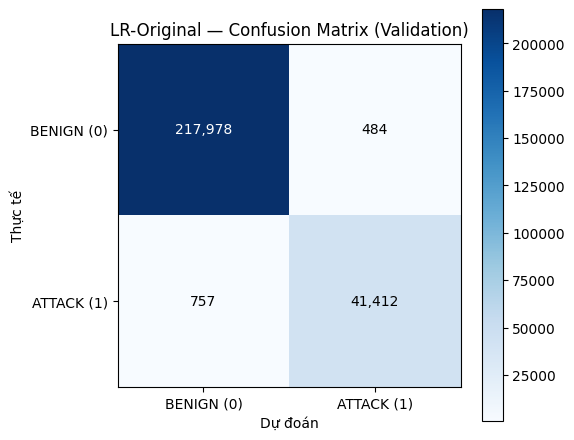

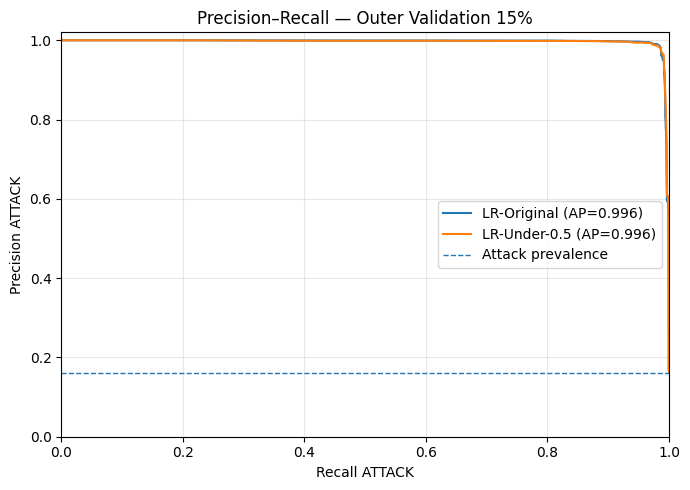

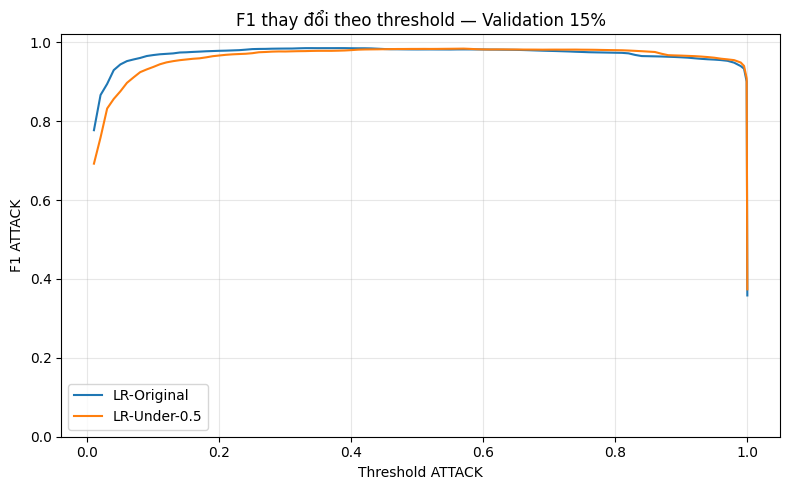

KẾT QUẢ THEO NGÀY (Outer Validation 15%)


,Source_file,N,ATTACK,ATTACK_rate,Recall_Attack,FPR,FP,FN
0,Benign-Monday.parquet,52752.0,0.0,0.0000,NaN,0.0013,70.0,0.0
1,Bruteforce-Tuesday.parquet,45480.0,1019.0,0.0224,0.9235,0.0028,125.0,78.0
2,DoS-Wednesday.parquet,69220.0,25825.0,0.3731,0.9899,0.0021,90.0,261.0
3,Infiltration-Webattacks-Thursday.parquet,39233.0,772.0,0.0197,0.8096,0.0034,130.0,147.0
4,Portscan-DDos-Botnet-Friday.parquet,53946.0,14553.0,0.2698,0.9814,0.0018,69.0,271.0


KẾT QUẢ THEO NHÃN TẤN CÔNG GỐC (chỉ để phân tích, không phải đặc trưng ML)


,Original_Label,ATTACK_Rows,Detected,Recall
3,DoS Hulk,23827,23800,0.9989
1,DDoS,14210,14201,0.9994
2,DoS GoldenEye,1159,1070,0.9232
9,Infiltration - Portscan,749,618,0.8251
6,FTP-Patator,590,590,1.0000
5,DoS Slowloris,577,514,0.8908
11,SSH-Patator,429,351,0.8182
4,DoS Slowhttptest,261,179,0.6858
10,Portscan,256,79,0.3086
0,Botnet,87,2,0.0230


In [28]:
# BIỂU ĐỒ + PHÂN TÍCH KẾT QUẢ THEO NGÀY/VÀ NHÃN TẤN CÔNG
# Biểu đồ 1: Confusion Matrix của cấu hình được chọn trên Validation
best_p_b7 = scores_b7[FINAL_LR_NAME_B7]
best_preds_b7 = (best_p_b7 >= FINAL_LR_THRESHOLD_B7).astype(np.int8)
cm_b7 = confusion_matrix(y_valid_b7, best_preds_b7, labels=[0,1])
fig, ax = plt.subplots(figsize=(5.8,4.9))
im = ax.imshow(cm_b7, cmap='Blues')
fig.colorbar(im, ax=ax)
ax.set(xticks=[0,1], yticks=[0,1],
       xticklabels=['BENIGN (0)','ATTACK (1)'],
       yticklabels=['BENIGN (0)','ATTACK (1)'],
       xlabel='Dự đoán', ylabel='Thực tế',
       title=f'{FINAL_LR_NAME_B7} — Confusion Matrix (Validation)')
for (r,c), v in np.ndenumerate(cm_b7):
    ax.text(c,r,f'{v:,}',ha='center',va='center',
            color='white' if v > cm_b7.max()/2 else 'black')
plt.tight_layout()
plt.savefig(REPORT_B7/'lr_outer_validation_confusion_matrix.png',dpi=180,bbox_inches='tight')
plt.show()

# Biểu đồ 2: Precision–Recall (ngưỡng độc lập)
fig, ax = plt.subplots(figsize=(7,5))
for model_name,p in scores_b7.items():
    precision, recall, _ = precision_recall_curve(y_valid_b7, p)
    ap = average_precision_score(y_valid_b7,p)
    ax.plot(recall, precision, label=f'{model_name} (AP={ap:.3f})')
ax.axhline(y_valid_b7.mean(),ls='--',lw=1, label='Attack prevalence')
ax.set(xlabel='Recall ATTACK', ylabel='Precision ATTACK',
       title='Precision–Recall — Outer Validation 15%',
       xlim=(0,1),ylim=(0,1.02))
ax.legend(); ax.grid(alpha=0.3); plt.tight_layout()
plt.savefig(REPORT_B7/'lr_outer_validation_pr_curve.png',dpi=180,bbox_inches='tight')
plt.show()

# Biểu đồ 3: F1/FPR theo threshold, hai đường khác thang đo nên tách biểu đồ
fig, ax = plt.subplots(figsize=(8,5))
for model_name in scores_b7:
    subset = threshold_grid_b7[threshold_grid_b7['Model']==model_name]
    ax.plot(subset['Threshold'],subset['F1_Attack'],label=model_name)
ax.set(xlabel='Threshold ATTACK',ylabel='F1 ATTACK',
       title='F1 thay đổi theo threshold — Validation 15%',ylim=(0,1.02))
ax.legend();ax.grid(alpha=0.3);plt.tight_layout()
plt.savefig(REPORT_B7/'lr_outer_validation_threshold_f1.png',dpi=180,bbox_inches='tight')
plt.show()

# Kiểm tra tỷ lệ ATTACK và recall theo ngày trong Validation
analysis_b7 = pd.DataFrame({
    'Source_file': valid_source_b7,
    'Original_Label': valid_label_b7,
    'y_true': y_valid_b7,
    'prediction': best_preds_b7,
    'attack_score': best_p_b7
})

def day_metrics_b7(group):
    y0 = group['y_true'].to_numpy()
    yp = group['prediction'].to_numpy()
    tn,fp,fn,tp = confusion_matrix(y0,yp,labels=[0,1]).ravel()
    return pd.Series({
        'N':len(group), 'ATTACK':int((y0==1).sum()),
        'ATTACK_rate':float((y0==1).mean()),
        'Recall_Attack':tp/(tp+fn) if tp+fn else np.nan,
        'FPR':fp/(fp+tn) if fp+tn else np.nan,
        'FP':int(fp),'FN':int(fn)
    })

by_day_b7 = pd.concat(
    {name:day_metrics_b7(g) for name,g in analysis_b7.groupby('Source_file')},
    axis=1
).T.rename_axis('Source_file').reset_index()

by_attack_b7 = (analysis_b7[analysis_b7['y_true']==1]
                .groupby('Original_Label')
                .agg(ATTACK_Rows=('y_true','size'),
                     Detected=('prediction','sum'))
                .reset_index())
by_attack_b7['Recall'] = by_attack_b7['Detected'] / by_attack_b7['ATTACK_Rows']
by_attack_b7 = by_attack_b7.sort_values('ATTACK_Rows',ascending=False)
print('KẾT QUẢ THEO NGÀY (Outer Validation 15%)')
display(by_day_b7.round(4))
print('KẾT QUẢ THEO NHÃN TẤN CÔNG GỐC (chỉ để phân tích, không phải đặc trưng ML)')
display(by_attack_b7.round(4))

by_day_b7.to_csv(REPORT_B7/'lr_outer_validation_by_day.csv',index=False)
by_attack_b7.to_csv(REPORT_B7/'lr_outer_validation_by_attack_type.csv',index=False)

In [29]:
# LƯU PIPELINE CUỐI, THRESHOLD, FEATURE ORDER VÀ TEST TẢI LẠI
# Không fit lại scaler trên validation. Không chạm Test 15%.
chosen_pipe_b7 = models_b7[FINAL_LR_NAME_B7]
final_path_b7 = MODEL_B7 / 'lr_baseline1_final.joblib'
joblib.dump(chosen_pipe_b7, final_path_b7, compress=3)

from datetime import datetime, timezone
metadata_b7 = {
    'model_family': 'LogisticRegression',
    'model_name': FINAL_LR_NAME_B7,
    'model_artifact': str(final_path_b7),
    'positive_class': 1,
    'negative_class': 0,
    'threshold': FINAL_LR_THRESHOLD_B7,
    'fpr_constraint_used_on_validation': FPR_LIMIT_B7,
    'feature_columns': FEATURE_B7,
    'n_features': len(FEATURE_B7),
    'train_rows': int(len(y_train_b7)),
    'outer_validation_rows': int(len(y_valid_b7)),
    'split_method': 'outer stratified 70/15/15; 3 expanding folds by capture day within train70',
    'note': 'Validation tuned; test15 untouched. Outer split not temporally held out.',
    'validation_selected_metrics': {
        'f1_attack': float(best_lr_row_b7['F1_Attack']),
        'recall_attack': float(best_lr_row_b7['Recall_Attack']),
        'fpr': float(best_lr_row_b7['FPR']),
        'fnr': float(best_lr_row_b7['FNR']),
        'average_precision': float(best_lr_row_b7['Average_Precision'])
    },
    'versions': {
        'python': sys.version.split()[0],
        'scikit_learn': sklearn.__version__,
        'imbalanced_learn': imblearn.__version__,
        'numpy': np.__version__
    },
    'saved_at_utc': datetime.now(timezone.utc).isoformat()
}
metadata_path_b7 = MODEL_B7 / 'lr_baseline1_metadata.json'
with open(metadata_path_b7,'w',encoding='utf-8') as f:
    json.dump(metadata_b7,f,indent=2,ensure_ascii=False)

# Kiểm tra mô hình đã lưu có dự đoán y hệt trong RAM (chỉ trên validation)
restored_b7 = joblib.load(final_path_b7)  # Chỉ load model do chính bạn tạo
p1_idx = int(np.flatnonzero(restored_b7.named_steps['model'].classes_ == 1)[0])
check_p = restored_b7.predict_proba(X_valid_b7[:100])[:,p1_idx]
assert np.allclose(check_p,best_p_b7[:100],rtol=1e-6,atol=1e-7)
assert len(FEATURE_B7) == X_valid_b7.shape[1]
print('Pipeline cuối:', final_path_b7)
print('Metadata:', metadata_path_b7)
print('Kiểm tra tải lại mô hình: KHỚP trên 100 dòng validation.')
print('Chưa chạy một phép dự đoán nào trên outer Test 15%.')
print('BƯỚC TIẾP THEO: Random Forest baseline 2 và XGBoost mô hình chính.')

Pipeline cuối: /content/drive/MyDrive/ThucTap/processed/models/lr_baseline1_final.joblib
Metadata: /content/drive/MyDrive/ThucTap/processed/models/lr_baseline1_metadata.json
Kiểm tra tải lại mô hình: KHỚP trên 100 dòng validation.
Chưa chạy một phép dự đoán nào trên outer Test 15%.
BƯỚC TIẾP THEO: Random Forest baseline 2 và XGBoost mô hình chính.


In [30]:
# NẠP TRAIN 70% VÀ TEMPORAL FOLDS ĐÃ LƯU
# Có thể chạy độc lập sau khi mount Google Drive; không cần chạy lại Bước 1–7.
!pip -q install imbalanced-learn pyarrow

import gc, json, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, roc_auc_score,
                             average_precision_score)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE

SEED_RF = 42
N_TRAIN_RF = 50_000       # prototype tương tự Logistic Regression ở Bước 6
RF_THRESHOLD = 0.5        # ngưỡng chỉ để so sánh 3 temporal folds
RATIO_RF = 0.5            # CHỐT: chỉ 0.5, không thử mức khác
N_TREES_RF = 100         # nếu Colab yếu, đổi thành 60 (ghi rõ trong báo cáo)

BASE_RF = Path('/content/drive/MyDrive/ThucTap/processed')
SPLIT_RF = BASE_RF / 'splits'
REPORT_RF = BASE_RF / 'reports'
REPORT_RF.mkdir(parents=True, exist_ok=True)

with open(BASE_RF/'feature_columns.json', encoding='utf-8') as f:
    FEATURES_RF = json.load(f)['feature_columns']
assert len(FEATURES_RF)==82, f'Số đặc trưng bất thường: {len(FEATURES_RF)}'
assert not set(FEATURES_RF).intersection({'target', 'Label', '_source_file'})

# Đọc DUY NHẤT TRAIN 70%; thứ tự dòng trùng với vị trí trong file temporal folds.
train_rf = pd.read_parquet(
    SPLIT_RF/'train70.parquet',
    columns=FEATURES_RF + ['target', '_source_file']
)
y_rf = train_rf['target'].to_numpy(dtype=np.int8)
assert set(np.unique(y_rf))=={0,1}

with np.load(SPLIT_RF/'temporal_folds_train70.npz') as saved:
    folds_rf = {
        f'fold{k}': (
            saved[f'fold{k}_train_pos'].copy(),
            saved[f'fold{k}_val_pos'].copy()
        ) for k in (1,2,3)
    }

DAY_ORDER_RF = ['monday', 'tuesday', 'wednesday', 'thursday', 'friday']
def day_code_rf(filename):
    match = [i for i, name in enumerate(DAY_ORDER_RF)
             if name in str(filename).lower()]
    if len(match) != 1:
        raise ValueError(f'Không xác định được thứ tự ngày: {filename}')
    return match[0]

source_day_rf = {s: day_code_rf(s) for s in train_rf['_source_file'].unique()}
day_codes_rf = train_rf['_source_file'].map(source_day_rf).to_numpy()

for fold_name, (tr, va) in folds_rf.items():
    assert tr.min()>=0 and va.min()>=0 and tr.max()<len(train_rf) and va.max()<len(train_rf)
    assert np.intersect1d(tr,va).size==0, 'Trùng vị trí train/val trong fold'
    assert day_codes_rf[tr].max() < day_codes_rf[va].min(), 'Rò rỉ theo thứ tự ngày'
    assert set(np.unique(y_rf[tr]))=={0,1}
    assert set(np.unique(y_rf[va]))=={0,1}
    print(f'{fold_name}: train={len(tr):,}, val={len(va):,}, '
          f'Attack train={y_rf[tr].mean():.2%}, Attack val={y_rf[va].mean():.2%}')

print(f'Đã nạp Train 70%: {len(train_rf):,} dòng × {len(FEATURES_RF)} đặc trưng.')
print('Chưa sử dụng outer Validation 15% hoặc Test 15%.')

fold1: train=460,665, val=321,685, Attack train=1.05%, Attack val=37.36%
fold2: train=782,350, val=182,667, Attack train=15.98%, Attack val=1.85%
fold3: train=965,017, val=251,263, Attack train=13.30%, Attack val=27.23%
Đã nạp Train 70%: 1,216,280 dòng × 82 đặc trưng.
Chưa sử dụng outer Validation 15% hoặc Test 15%.


In [31]:
# KHAI BÁO 4 RANDOM FOREST PIPELINES
# Không cần StandardScaler cho mô hình cây (Random Forest).
# Trong resampling, luôn CHỈ thay đổi đúng lớp yêu cầu.

RF_CONFIGS = [
    ('RF-Original', 'original'),
    ('RF-Weighted', 'weighted'),
    ('RF-Under-0.5', 'undersampling'),
    ('RF-SMOTE-0.5', 'smote'),
]

def build_rf_pipeline(mode, y_train):
    y_train = np.asarray(y_train, dtype=np.int8)
    n0 = int((y_train==0).sum())  # BENIGN
    n1 = int((y_train==1).sum())  # ATTACK
    if min(n0,n1)<=0:
        raise ValueError('Train thiếu BENIGN (0) hoặc ATTACK (1).')

    steps=[]
    after0,after1 = n0,n1

    if mode=='undersampling':
        after0 = int(np.ceil(n1/RATIO_RF))
        if after0 > n0:
            raise ValueError('Không thể undersample BENIGN: lớp 0 không đủ nhiều.')
        if after0 < n0:
            steps.append(('sampler', RandomUnderSampler(
                sampling_strategy={0: after0}, random_state=SEED_RF)))

    elif mode=='smote':
        after1 = int(np.ceil(n0*RATIO_RF))
        if after1 < n1:
            raise ValueError('Không thể SMOTE ATTACK: tỷ lệ lớp 1 đã vượt mục tiêu.')
        if after1 > n1:
            if n1<4:
                raise ValueError('SMOTE k_neighbors=3 yêu cầu ít nhất 4 ATTACK.')
            steps.append(('sampler', SMOTE(
                sampling_strategy={1: after1}, k_neighbors=3,
                random_state=SEED_RF)))
    elif mode not in ('original', 'weighted'):
        raise ValueError(f'Mode không hỗ trợ: {mode}')

    rf = RandomForestClassifier(
        n_estimators=N_TREES_RF,
        max_depth=16,
        min_samples_leaf=2,
        max_features='sqrt',
        bootstrap=True,
        class_weight='balanced' if mode=='weighted' else None,
        random_state=SEED_RF,
        n_jobs=2
    )
    steps.append(('model',rf))
    pipe = ImbPipeline(steps)
    return pipe,after0,after1

# Kiểm tra logic trên dữ liệu train mẫu (KHÔNG huấn luyện):
y_sample_check = y_rf[folds_rf['fold3'][0][:10000]]
if set(np.unique(y_sample_check))=={0,1}:
    for cfg,mode in RF_CONFIGS:
        p,a0,a1=build_rf_pipeline(mode,y_sample_check)
        print(f'{cfg:16s}: BENIGN={a0:,}, ATTACK={a1:,}; '
              f'sampler={p.named_steps.get("sampler") is not None}')

print('Đã định nghĩa 4 cấu hình, tất cả resampling tỷ lệ 0.5.')

RF-Original     : BENIGN=8,654, ATTACK=1,346; sampler=False
RF-Weighted     : BENIGN=8,654, ATTACK=1,346; sampler=False
RF-Under-0.5    : BENIGN=2,692, ATTACK=1,346; sampler=True
RF-SMOTE-0.5    : BENIGN=8,654, ATTACK=4,327; sampler=True
Đã định nghĩa 4 cấu hình, tất cả resampling tỷ lệ 0.5.


In [32]:
# CHẠY 12 THÍ NGHIỆM RANDOM FOREST TRÊN 3 TEMPORAL FOLDS
rf_rows=[]
rf_distribution=[]
rf_importances=[]
rf_results_path = REPORT_RF/'rf_temporal_3fold_4configs_05.csv'
rf_dist_path = REPORT_RF/'rf_temporal_distribution_05.csv'
rf_importance_path = REPORT_RF/'rf_temporal_feature_importance_05.csv'

for fold_name,(train_positions,val_positions) in folds_rf.items():
    # Mẫu train giống quy tắc đã dùng với Logistic Regression: 50K + stratify + SEED 42
    if len(train_positions)>N_TRAIN_RF:
        sample_positions,_ = train_test_split(
            train_positions,train_size=N_TRAIN_RF,
            stratify=y_rf[train_positions], random_state=SEED_RF)
    else:
        sample_positions=train_positions.copy()

    Xtr = train_rf.iloc[sample_positions][FEATURES_RF].to_numpy(dtype=np.float32)
    ytr = y_rf[sample_positions]
    Xva = train_rf.iloc[val_positions][FEATURES_RF].to_numpy(dtype=np.float32)
    yva = y_rf[val_positions]
    assert np.isfinite(Xtr).all() and np.isfinite(Xva).all()
    assert set(np.unique(ytr))=={0,1} and set(np.unique(yva))=={0,1}

    orig0,orig1=int((ytr==0).sum()),int((ytr==1).sum())
    print(f'\n{"="*76}\n{fold_name.upper()} | Train={len(ytr):,} '
          f'(BENIGN={orig0:,}, ATTACK={orig1:,}) | Val={len(yva):,}\n{"="*76}')

    for cfg,mode in RF_CONFIGS:
        pipe,after0,after1=build_rf_pipeline(mode,ytr)
        print(f'  {cfg}: train sau lấy mẫu = {after0+after1:,} '
              f'(BENIGN={after0:,}, ATTACK={after1:,})',flush=True)
        assert mode not in ('undersampling','smote') or abs(after1/after0-RATIO_RF)<=1/after0+1e-9
        if mode=='undersampling': assert after1==orig1 and after0<=orig0
        if mode=='smote': assert after0==orig0 and after1>=orig1

        start=time.perf_counter()
        pipe.fit(Xtr,ytr)       # Sampler CHỈ hoạt động ở đây, trên train
        train_seconds=time.perf_counter()-start
        j=int(np.flatnonzero(pipe.named_steps['model'].classes_==1)[0])
        start=time.perf_counter()
        score=pipe.predict_proba(Xva)[:,j]   # Không resampling validation
        predict_seconds=time.perf_counter()-start
        pred=(score>=RF_THRESHOLD).astype(np.int8)

        tn,fp,fn,tp=confusion_matrix(yva,pred,labels=[0,1]).ravel()
        record={
            'Fold':fold_name,'Config':cfg,'Ratio':RATIO_RF if mode in ('undersampling','smote') else np.nan,
            'Train_Before':len(ytr),'Train_After':after0+after1,
            'Train_BENIGN_After':after0,'Train_ATTACK_After':after1,
            'Val_Rows':len(yva),'Val_ATTACK_Rate':float(yva.mean()),
            'Accuracy':accuracy_score(yva,pred),
            'Precision_Attack':precision_score(yva,pred,zero_division=0),
            'Recall_Attack':recall_score(yva,pred,zero_division=0),
            'F1_Attack':f1_score(yva,pred,zero_division=0),
            'FPR':fp/(fp+tn) if (fp+tn)>0 else np.nan,
            'FNR':fn/(fn+tp) if (fn+tp)>0 else np.nan,
            'ROC_AUC':roc_auc_score(yva,score),
            'Average_Precision':average_precision_score(yva,score),
            'TN':int(tn),'FP':int(fp),'FN':int(fn),'TP':int(tp),
            'Train_seconds':round(train_seconds,2),
            'Predict_seconds':round(predict_seconds,2),
            'Threshold':RF_THRESHOLD
        }
        rf_rows.append(record)
        rf_distribution.append({
            'Fold':fold_name,'Config':cfg,
            'BENIGN':after0,'ATTACK':after1,
            'Total':after0+after1,
            'ATTACK_Percent':100*after1/(after0+after1)
        })
        rf_importances.extend({
            'Fold':fold_name,'Config':cfg,'Feature':col,'Importance':float(imp)
        } for col,imp in zip(FEATURES_RF,pipe.named_steps['model'].feature_importances_))
        print(f'    F1={record["F1_Attack"]:.4f} | Recall={record["Recall_Attack"]:.4f}'
              f' | FPR={record["FPR"]:.4f} | AP={record["Average_Precision"]:.4f}'
              f' | Fit {train_seconds:.1f}s')
        pd.DataFrame(rf_rows).to_csv(rf_results_path,index=False)
        pd.DataFrame(rf_distribution).to_csv(rf_dist_path,index=False)
        pd.DataFrame(rf_importances).to_csv(rf_importance_path,index=False)
        del pipe,score,pred
        gc.collect()

    del Xtr,ytr,Xva,yva
    gc.collect()

results_rf=pd.DataFrame(rf_rows)
distribution_rf=pd.DataFrame(rf_distribution)
assert len(results_rf)==12, 'Chưa đủ 12 lần thí nghiệm!'
print('\nHOÀN THÀNH 12 THÍ NGHIỆM RANDOM FOREST:')
display(results_rf.round(4))
print('Đã lưu:',rf_results_path)


FOLD1 | Train=50,000 (BENIGN=49,475, ATTACK=525) | Val=321,685
  RF-Original: train sau lấy mẫu = 50,000 (BENIGN=49,475, ATTACK=525)
    F1=0.0000 | Recall=0.0000 | FPR=0.0000 | AP=0.3780 | Fit 7.9s
  RF-Weighted: train sau lấy mẫu = 50,000 (BENIGN=49,475, ATTACK=525)
    F1=0.0000 | Recall=0.0000 | FPR=0.0000 | AP=0.3767 | Fit 8.6s
  RF-Under-0.5: train sau lấy mẫu = 1,575 (BENIGN=1,050, ATTACK=525)
    F1=0.0000 | Recall=0.0000 | FPR=0.0000 | AP=0.3653 | Fit 0.5s
  RF-SMOTE-0.5: train sau lấy mẫu = 74,213 (BENIGN=49,475, ATTACK=24,738)
    F1=0.0000 | Recall=0.0000 | FPR=0.0000 | AP=0.3731 | Fit 27.4s

FOLD2 | Train=50,000 (BENIGN=42,011, ATTACK=7,989) | Val=182,667
  RF-Original: train sau lấy mẫu = 50,000 (BENIGN=42,011, ATTACK=7,989)
    F1=0.0006 | Recall=0.0003 | FPR=0.0000 | AP=0.6411 | Fit 20.5s
  RF-Weighted: train sau lấy mẫu = 50,000 (BENIGN=42,011, ATTACK=7,989)
    F1=0.0006 | Recall=0.0003 | FPR=0.0000 | AP=0.5893 | Fit 21.5s
  RF-Under-0.5: train sau lấy mẫu = 23,967 (

,Fold,Config,Ratio,Train_Before,Train_After,Train_BENIGN_After,Train_ATTACK_After,Val_Rows,Val_ATTACK_Rate,Accuracy,Precision_Attack,Recall_Attack,F1_Attack,FPR,FNR,ROC_AUC,Average_Precision,TN,FP,FN,TP,Train_seconds,Predict_seconds,Threshold
0,fold1,RF-Original,NaN,50000,50000,49475,525,321685,0.3736,0.6264,0.0000,0.0000,0.0000,0.0000,1.0000,0.5047,0.3780,201515,0,120170,0,7.86,1.01,0.5
1,fold1,RF-Weighted,NaN,50000,50000,49475,525,321685,0.3736,0.6264,0.0000,0.0000,0.0000,0.0000,1.0000,0.5008,0.3767,201515,0,120170,0,8.57,1.06,0.5
2,fold1,RF-Under-0.5,0.5,50000,1575,1050,525,321685,0.3736,0.6264,0.0000,0.0000,0.0000,0.0000,1.0000,0.4649,0.3653,201515,0,120170,0,0.52,0.86,0.5
3,fold1,RF-SMOTE-0.5,0.5,50000,74213,49475,24738,321685,0.3736,0.6264,0.0000,0.0000,0.0000,0.0000,1.0000,0.4959,0.3731,201515,0,120170,0,27.41,1.01,0.5
4,fold2,RF-Original,NaN,50000,50000,42011,7989,182667,0.0185,0.9815,0.3333,0.0003,0.0006,0.0000,0.9997,0.9733,0.6411,179288,2,3376,1,20.45,1.33,0.5
5,fold2,RF-Weighted,NaN,50000,50000,42011,7989,182667,0.0185,0.9815,0.3333,0.0003,0.0006,0.0000,0.9997,0.9612,0.5893,179288,2,3376,1,21.47,1.31,0.5
6,fold2,RF-Under-0.5,0.5,50000,23967,15978,7989,182667,0.0185,0.9815,0.1667,0.0003,0.0006,0.0000,0.9997,0.9634,0.6119,179285,5,3376,1,8.82,0.85,0.5
7,fold2,RF-SMOTE-0.5,0.5,50000,63017,42011,21006,182667,0.0185,0.9815,0.2500,0.0003,0.0006,0.0000,0.9997,0.9792,0.5442,179287,3,3376,1,20.50,0.98,0.5
8,fold3,RF-Original,NaN,50000,50000,43348,6652,251263,0.2723,0.9933,0.9999,0.9756,0.9876,0.0000,0.0244,0.9998,0.9995,182852,4,1671,66736,16.23,2.12,0.5
9,fold3,RF-Weighted,NaN,50000,50000,43348,6652,251263,0.2723,0.9934,0.9999,0.9759,0.9877,0.0000,0.0241,0.9997,0.9994,182847,9,1647,66760,12.54,2.03,0.5


Đã lưu: /content/drive/MyDrive/ThucTap/processed/reports/rf_temporal_3fold_4configs_05.csv


TRUNG BÌNH ĐỀU 3 TEMPORAL FOLDS — CHỈ ĐỂ CHỌN ỨNG VIÊN:


,F1_Attack,Recall_Attack,Precision_Attack,FPR,FNR,Average_Precision,ROC_AUC,Train_seconds,Predict_seconds
Config,,,,,,,,,
RF-Under-0.5,0.32963,0.32580,0.38880,0.00004,0.67420,0.65858,0.80925,4.86333,1.00333
RF-Weighted,0.32945,0.32541,0.44440,0.00002,0.67459,0.65515,0.82060,14.19333,1.46667
RF-SMOTE-0.5,0.32945,0.32540,0.41663,0.00002,0.67460,0.63878,0.82492,22.98000,1.81333
RF-Original,0.32940,0.32529,0.44442,0.00001,0.67471,0.67290,0.82594,14.84667,1.48667



KẾT QUẢ F1 TỪNG FOLD:


Config,RF-Original,RF-SMOTE-0.5,RF-Under-0.5,RF-Weighted
Fold,,,,
fold1,0.0000,0.0000,0.0000,0.0000
fold2,0.0006,0.0006,0.0006,0.0006
fold3,0.9876,0.9877,0.9883,0.9877



KẾT QUẢ FPR TỪNG FOLD:


Config,RF-Original,RF-SMOTE-0.5,RF-Under-0.5,RF-Weighted
Fold,,,,
fold1,0.0,0.0,0.0000,0.0
fold2,0.0,0.0,0.0000,0.0
fold3,0.0,0.0,0.0001,0.0


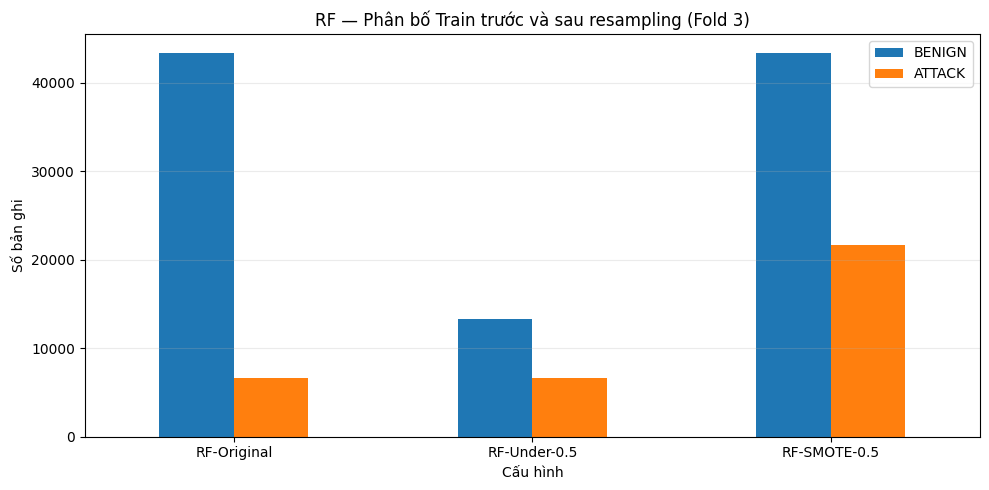

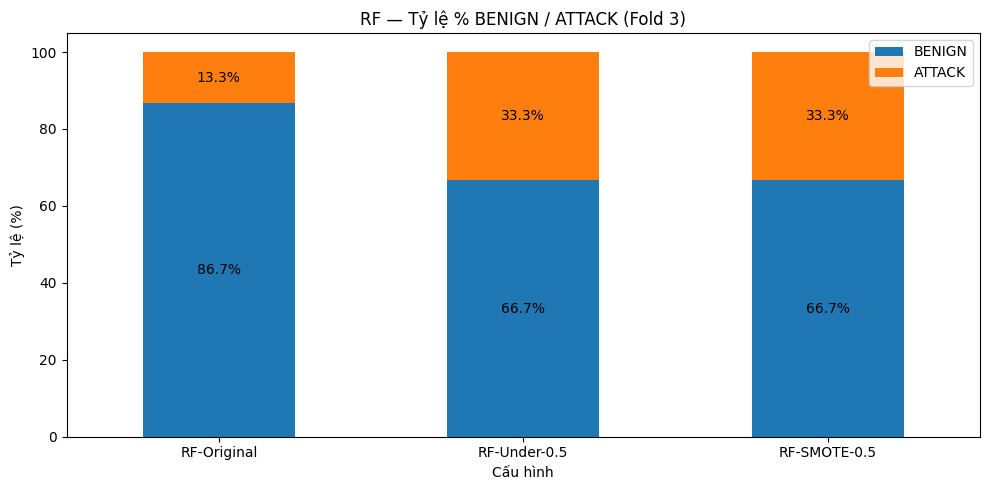

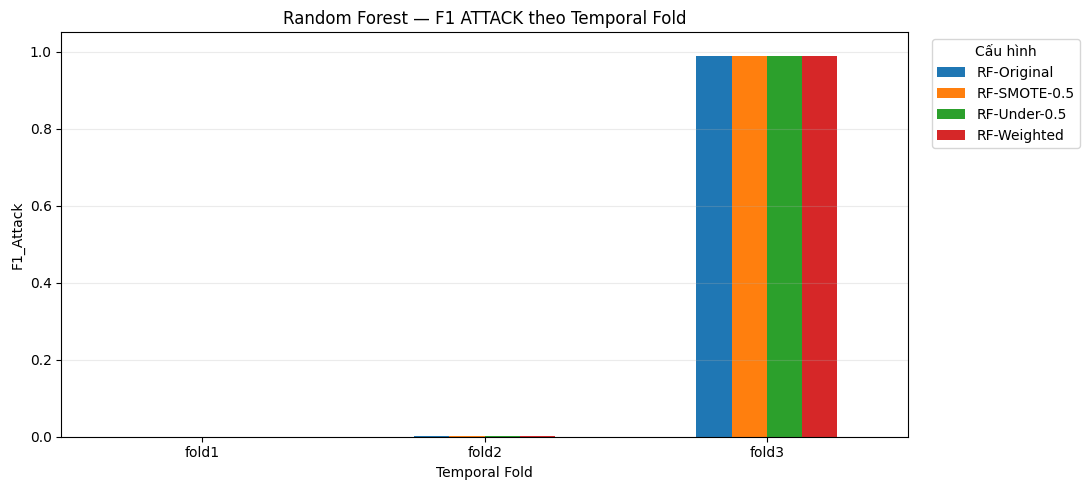

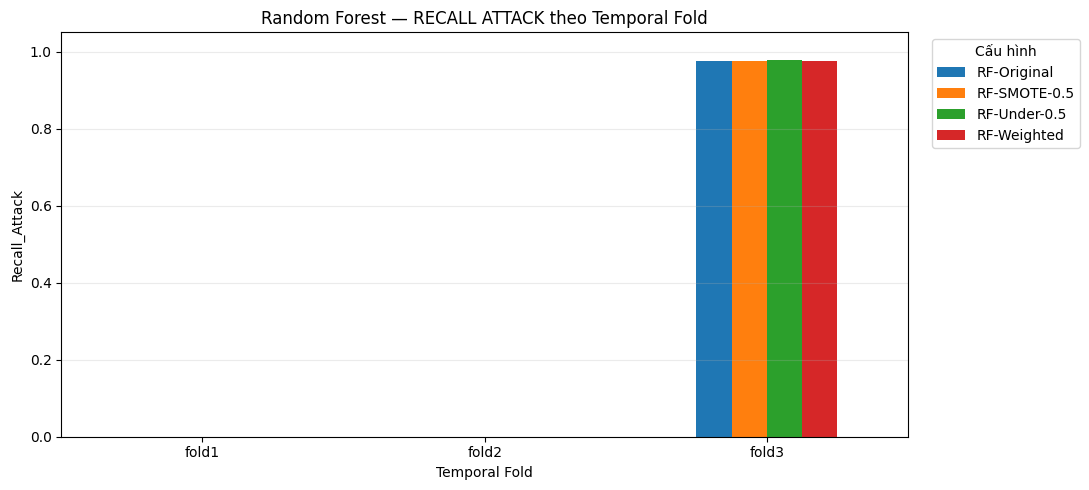

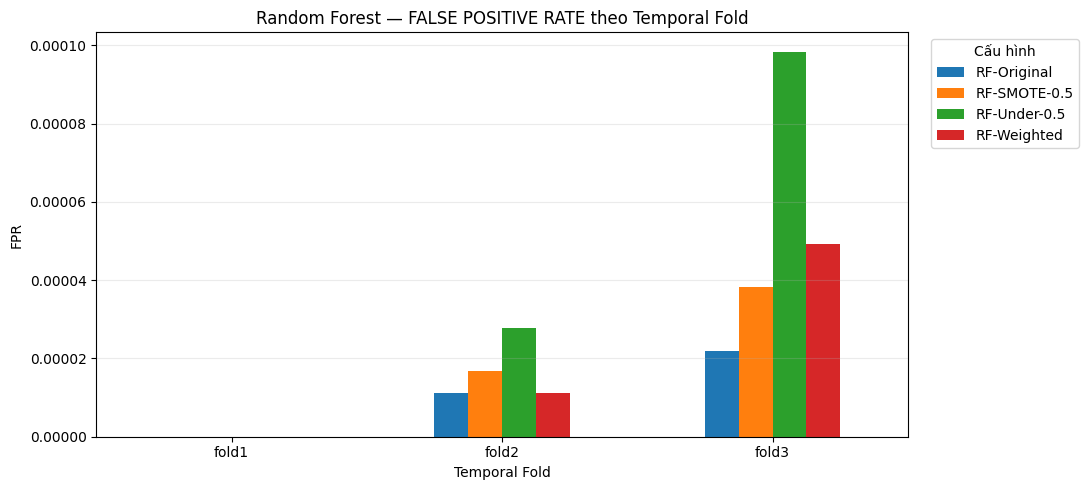

Ứng viên RF có F1 trung bình cao nhất: RF-Under-0.5
Chưa phải kết quả Test; cần xem Recall, FPR, sự ổn định ở từng fold.


In [33]:
# BẢNG TỔNG HỢP + BIỂU ĐỒ KẾT QUẢ RANDOM FOREST
# Có thể chạy độc lập sau khi đã có file kết quả Cell 8.3.
results_rf=pd.read_csv(REPORT_RF/'rf_temporal_3fold_4configs_05.csv')
distribution_rf=pd.read_csv(REPORT_RF/'rf_temporal_distribution_05.csv')
expected_configs={'RF-Original','RF-Weighted','RF-Under-0.5','RF-SMOTE-0.5'}
assert len(results_rf)==12 and not results_rf.duplicated(['Fold','Config']).any()
assert set(results_rf['Config'])==expected_configs
assert set(results_rf['Fold'])=={'fold1','fold2','fold3'}

rf_metric_columns=['F1_Attack','Recall_Attack','Precision_Attack',
                   'FPR','FNR','Average_Precision','ROC_AUC',
                   'Train_seconds','Predict_seconds']
rf_mean=(results_rf.groupby('Config')[rf_metric_columns]
         .mean().sort_values(['F1_Attack','FPR'],ascending=[False,True]))
print('TRUNG BÌNH ĐỀU 3 TEMPORAL FOLDS — CHỈ ĐỂ CHỌN ỨNG VIÊN:')
display(rf_mean.round(5))
print('\nKẾT QUẢ F1 TỪNG FOLD:')
rf_f1=results_rf.pivot(index='Fold',columns='Config',values='F1_Attack')
display(rf_f1.round(4))
print('\nKẾT QUẢ FPR TỪNG FOLD:')
rf_fpr=results_rf.pivot(index='Fold',columns='Config',values='FPR')
display(rf_fpr.round(4))
rf_mean.to_csv(REPORT_RF/'rf_temporal_mean_metrics_05.csv',encoding='utf-8-sig')

# Biểu đồ 1: phân bố lớp của 3 cấu hình (Original, Under, SMOTE) trong Fold 3
fold3_dist=(distribution_rf[(distribution_rf['Fold']=='fold3') &
             (distribution_rf['Config'].isin(['RF-Original','RF-Under-0.5','RF-SMOTE-0.5']))]
            .set_index('Config').loc[['RF-Original','RF-Under-0.5','RF-SMOTE-0.5']])
ax=fold3_dist[['BENIGN','ATTACK']].plot(kind='bar',figsize=(10,5),rot=0)
ax.set(title='RF — Phân bố Train trước và sau resampling (Fold 3)',
       xlabel='Cấu hình',ylabel='Số bản ghi')
ax.grid(axis='y',alpha=0.25)
plt.tight_layout()
plt.savefig(REPORT_RF/'rf_fold3_distribution_counts_05.png',dpi=180,bbox_inches='tight')
plt.show()

pct=fold3_dist[['BENIGN','ATTACK']].div(fold3_dist['Total'],axis=0)*100
ax=pct.plot(kind='bar',stacked=True,figsize=(10,5),rot=0)
ax.set(title='RF — Tỷ lệ % BENIGN / ATTACK (Fold 3)',
       xlabel='Cấu hình',ylabel='Tỷ lệ (%)',ylim=(0,105))
for i,(name,row) in enumerate(pct.iterrows()):
    ax.text(i,row['BENIGN']/2,f'{row["BENIGN"]:.1f}%',ha='center',va='center')
    ax.text(i,row['BENIGN']+row['ATTACK']/2,f'{row["ATTACK"]:.1f}%',ha='center',va='center')
plt.tight_layout()
plt.savefig(REPORT_RF/'rf_fold3_distribution_percent_05.png',dpi=180,bbox_inches='tight')
plt.show()

for metric,filename,title in [
    ('F1_Attack','rf_temporal_f1_05.png','F1 ATTACK'),
    ('Recall_Attack','rf_temporal_recall_05.png','RECALL ATTACK'),
    ('FPR','rf_temporal_fpr_05.png','FALSE POSITIVE RATE')
]:
    pivot=results_rf.pivot(index='Fold',columns='Config',values=metric)
    ax=pivot.plot(kind='bar',figsize=(11,5),rot=0)
    ax.set(title=f'Random Forest — {title} theo Temporal Fold',
           xlabel='Temporal Fold',ylabel=metric)
    if metric!='FPR': ax.set_ylim(0,1.05)
    ax.grid(axis='y',alpha=0.25)
    ax.legend(title='Cấu hình',bbox_to_anchor=(1.02,1),loc='upper left')
    plt.tight_layout()
    plt.savefig(REPORT_RF/filename,dpi=180,bbox_inches='tight')
    plt.show()

print('Ứng viên RF có F1 trung bình cao nhất:',rf_mean.index[0])
print('Chưa phải kết quả Test; cần xem Recall, FPR, sự ổn định ở từng fold.')

In [34]:
# ĐỐI CHIẾU RF VỚI LOGISTIC REGRESSION TRÊN 3 FOLDS
# Chỉ so sánh cùng một cấu hình Original/Under-0.5 và cùng điều kiện 50K train mỗi fold.
# Nếu LR report không tồn tại, phần so sánh này được bỏ qua.
lr_path=REPORT_RF/'lr_temporal_3fold_4configs_05.csv'
if not lr_path.exists():
    print('Chưa tìm thấy bảng 3-fold Logistic Regression, bỏ qua đối chiếu.')
else:
    lr_data=pd.read_csv(lr_path)
    keep_lr=lr_data[lr_data['Config'].isin(['LR-Original','LR-Under-0.5'])].copy()
    keep_rf=results_rf[results_rf['Config'].isin(['RF-Original','RF-Under-0.5'])].copy()
    keep_lr['Algorithm']='Logistic Regression'
    keep_rf['Algorithm']='Random Forest'
    for frame in (keep_lr,keep_rf):
        frame['Treatment']=frame['Config'].str.split('-',n=1).str[1]
    contrast=pd.concat([keep_lr,keep_rf],ignore_index=True)
    comparative=contrast.pivot_table(
        index=['Fold','Treatment'],columns='Algorithm',
        values=['F1_Attack','Recall_Attack','FPR'],aggfunc='first'
    )
    print('ĐỐI CHIẾU LR VÀ RF Ở CÙNG TEMPORAL FOLDS:')
    display(comparative.round(5))
    comparative.to_csv(REPORT_RF/'rf_vs_lr_temporal_original_under05.csv')

# Lưu thông số experiment, để báo cáo và tái lập
config_rf={
    'algorithm':'RandomForestClassifier',
    'scope':'inner temporal folds within 70% outer train',
    'fold_days':['Mon-Tue -> Wed','Mon-Wed -> Thu','Mon-Thu -> Fri'],
    'train_cap_per_fold':N_TRAIN_RF,
    'sampling_seed':SEED_RF,
    'ratio_attack_over_benign_after_resampling':RATIO_RF,
    'rf_params':{'n_estimators':N_TREES_RF,'max_depth':16,
                 'min_samples_leaf':2,'max_features':'sqrt',
                 'n_jobs':2,'class_weight':'balanced ONLY in RF-Weighted'},
    'threshold_for_prototype':RF_THRESHOLD,
    'validation_resampled':False,
    'test15_touched':False,
    'note':'Do not pick production model by test; FullTrain RF and threshold selection come next.'
}
with open(REPORT_RF/'rf_temporal_experiment_config_05.json','w',encoding='utf-8') as f:
    json.dump(config_rf,f,indent=2,ensure_ascii=False)
print('\nĐã lưu kết quả Bước 8. Bước sau: chọn RF candidate rồi huấn luyện toàn bộ Train 70%, tune threshold trên outer Val15.')

ĐỐI CHIẾU LR VÀ RF Ở CÙNG TEMPORAL FOLDS:


F1_Attack                               FPR                     Recall_Attack              
Algorithm       Logistic Regression Random Forest Logistic Regression Random Forest Logistic Regression Random Forest
Fold  Treatment                                                                                                      
fold1 Original              0.00000       0.00000             0.00016       0.00000             0.00000       0.00000
      Under-0.5             0.00000       0.00000             0.00255       0.00000             0.00000       0.00000
fold2 Original              0.33249       0.00059             0.00131       0.00001             0.21321       0.00030
      Under-0.5             0.59722       0.00059             0.00448       0.00003             0.52710       0.00030
fold3 Original              0.98389       0.98761             0.00287       0.00002             0.97570       0.97557
      Under-0.5             0.98074       0.98829             0.00641       0.00010             0.97869       0.97711


Đã lưu kết quả Bước 8. Bước sau: chọn RF candidate rồi huấn luyện toàn bộ Train 70%, tune threshold trên outer Val15.


In [35]:
# ĐỌC TRAIN 70%, VALIDATION 15% VÀ SCHEMA (CHẠY ĐỘC LẬP)
!pip -q install pyarrow imbalanced-learn joblib

import gc, json, time, sys, shutil, warnings
from datetime import datetime, timezone
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib, sklearn, imblearn
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
    recall_score, f1_score, average_precision_score, roc_auc_score,
    precision_recall_curve, roc_curve, ConfusionMatrixDisplay)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler

SEED_B9 = 42
UNDER_RATIO_B9 = 0.5               # CHỈ 0.5, ATTACK / BENIGN sau lấy mẫu
N_TREES_B9 = 100                 # Giống prototype Bước 8
MAX_DEPTH_B9 = 16
FPR_LIMIT_B9 = 0.01              # Giống Logistic Regression Bước 7

BASE_B9 = Path('/content/drive/MyDrive/ThucTap/processed')
SPLITS_B9 = BASE_B9 / 'splits'
REPORT_B9 = BASE_B9 / 'reports'
MODEL_B9 = BASE_B9 / 'models'
REPORT_B9.mkdir(parents=True, exist_ok=True)
MODEL_B9.mkdir(parents=True, exist_ok=True)

with open(BASE_B9 / 'feature_columns.json', encoding='utf-8') as f:
    FEATURES_B9 = json.load(f)['feature_columns']
assert len(FEATURES_B9) == 82
assert not {'target','Label','_source_file'} & set(FEATURES_B9)

# Dùng đúng feature order của pipeline Logistic Regression.
cols_train = FEATURES_B9 + ['target']
cols_val = FEATURES_B9 + ['target','Label','_source_file']
train_df_b9 = pd.read_parquet(SPLITS_B9 / 'train70.parquet', columns=cols_train)
val_df_b9 = pd.read_parquet(SPLITS_B9 / 'validation15.parquet', columns=cols_val)

X_train_b9 = train_df_b9[FEATURES_B9].to_numpy(dtype=np.float32)
y_train_b9 = train_df_b9['target'].to_numpy(dtype=np.int8, copy=True)
X_val_b9 = val_df_b9[FEATURES_B9].to_numpy(dtype=np.float32)
y_val_b9 = val_df_b9['target'].to_numpy(dtype=np.int8, copy=True)
val_source_b9 = val_df_b9['_source_file'].astype(str).to_numpy()
val_type_b9 = val_df_b9['Label'].astype(str).to_numpy()

# Giải phóng các DataFrame lớn ngay khi không còn cần thiết.
del train_df_b9, val_df_b9
gc.collect()

assert X_train_b9.shape == (1_216_280, 82)
assert X_val_b9.shape == (260_631, 82)
assert set(np.unique(y_train_b9)) == {0,1}
assert set(np.unique(y_val_b9)) == {0,1}
assert np.isfinite(X_train_b9).all(), 'Train chứa NaN/Inf hoặc tràn khi đổi sang float32.'
assert np.isfinite(X_val_b9).all(), 'Validation chứa NaN/Inf hoặc tràn khi đổi sang float32.'

n0_b9 = int((y_train_b9 == 0).sum())
n1_b9 = int((y_train_b9 == 1).sum())
assert n0_b9 > n1_b9 > 0
print(f'Train 70%: {len(y_train_b9):,} | BENIGN={n0_b9:,}, ATTACK={n1_b9:,}')
print(f'Validation 15%: {len(y_val_b9):,} | ATTACK={(y_val_b9==1).sum():,}')
print('Feature count:',len(FEATURES_B9))
print('Tổng dung lượng mảng X_train + X_val (MiB):', round((X_train_b9.nbytes + X_val_b9.nbytes)/1024**2,1))
print('Test 15% chưa được đọc.')

Train 70%: 1,216,280 | BENIGN=1,019,490, ATTACK=196,790
Validation 15%: 260,631 | ATTACK=42,169
Feature count: 82
Tổng dung lượng mảng X_train + X_val (MiB): 462.0
Test 15% chưa được đọc.


In [36]:
# TRAIN RF ORIGINAL VÀ RF-UNDER-0.5, LƯU HAI ỨNG VIÊN
# Không có StandardScaler: Random Forest là mô hình dựa trên cây.
# Không SMOTE tại bước full-train: đã thử ở Bước 8; chỉ chốt 2 ứng viên cho bước này.

CONFIGS_B9 = [('RF-Original', 'original'), ('RF-Under-0.5', 'undersampling')]
assert UNDER_RATIO_B9 == 0.5

model_paths_b9 = {}
validation_scores_b9 = {}
train_log_b9 = []

def build_rf_full_b9(mode, n0, n1):
    steps = []
    after0, after1 = n0, n1
    if mode == 'undersampling':
        after0 = int(np.ceil(n1 / UNDER_RATIO_B9))
        if not 0 < after0 <= n0:
            raise ValueError('Không thể Undersampling BENIGN với tỷ lệ đã chọn.')
        if after0 < n0:
            steps.append(('sampler', RandomUnderSampler(
                sampling_strategy={0: after0}, random_state=SEED_B9)))
    elif mode != 'original':
        raise ValueError(f'Mode không hợp lệ: {mode}')
    steps.append(('model', RandomForestClassifier(
        n_estimators=N_TREES_B9, max_depth=MAX_DEPTH_B9,
        min_samples_leaf=2, max_features='sqrt', bootstrap=True,
        class_weight=None, random_state=SEED_B9, n_jobs=2
    )))
    return ImbPipeline(steps), after0, after1

for model_name, mode in CONFIGS_B9:
    pipe, after0, after1 = build_rf_full_b9(mode, n0_b9, n1_b9)
    print('\n' + '='*74)
    print('HUẤN LUYỆN:', model_name)
    print(f'Train trước: {n0_b9:,} BENIGN + {n1_b9:,} ATTACK')
    print(f'Train sau:   {after0:,} BENIGN + {after1:,} ATTACK')
    assert after1 == n1_b9
    assert after0 <= n0_b9

    t0 = time.perf_counter()
    pipe.fit(X_train_b9, y_train_b9)  # Resampling CHỈ trong fit(TRAIN)
    fit_sec = time.perf_counter() - t0

    if mode == 'undersampling':
        kept = pipe.named_steps['sampler'].sample_indices_
        assert int((y_train_b9[kept] == 0).sum()) == after0
        assert int((y_train_b9[kept] == 1).sum()) == n1_b9

    attack_col = int(np.flatnonzero(pipe.named_steps['model'].classes_ == 1)[0])
    t1 = time.perf_counter()
    scores = pipe.predict_proba(X_val_b9)[:, attack_col]
    predict_sec = time.perf_counter() - t1
    assert len(scores) == len(y_val_b9) and np.isfinite(scores).all()
    validation_scores_b9[model_name] = scores.copy()

    saved_path = MODEL_B9 / ('rf_original_fulltrain.joblib' if mode=='original'
                              else 'rf_under_05_fulltrain.joblib')
    joblib.dump(pipe, saved_path, compress=3)
    model_paths_b9[model_name] = saved_path
    train_log_b9.append({
        'Model':model_name,'Train_BENIGN_Before':n0_b9,'Train_ATTACK_Before':n1_b9,
        'Train_BENIGN_After':after0,'Train_ATTACK_After':after1,
        'Train_Rows_After':after0+after1,'Train_Seconds':round(fit_sec,2),
        'Predict_Seconds':round(predict_sec,2),'File':str(saved_path)
    })
    print(f'Train: {fit_sec:.1f} giây | Predict: {predict_sec:.1f} giây')
    print('Đã lưu:',saved_path.name)
    del pipe, scores
    gc.collect()

pd.DataFrame(train_log_b9).to_csv(REPORT_B9/'rf_fulltrain_training_log_05.csv',index=False)
np.savez_compressed(
    REPORT_B9/'rf_outer_validation_scores_05.npz',
    y_true=y_val_b9,
    scores_original=validation_scores_b9['RF-Original'],
    scores_under05=validation_scores_b9['RF-Under-0.5']
)
print('\nKẾT QUẢ PHÂN BỐ VÀ THỜI GIAN:')
display(pd.DataFrame(train_log_b9))
print('Chỉ có RF-Original và RF-Under-0.5, không dùng tỷ lệ 0.8.')


HUẤN LUYỆN: RF-Original
Train trước: 1,019,490 BENIGN + 196,790 ATTACK
Train sau:   1,019,490 BENIGN + 196,790 ATTACK
Train: 753.2 giây | Predict: 2.1 giây
Đã lưu: rf_original_fulltrain.joblib

HUẤN LUYỆN: RF-Under-0.5
Train trước: 1,019,490 BENIGN + 196,790 ATTACK
Train sau:   393,580 BENIGN + 196,790 ATTACK
Train: 301.6 giây | Predict: 2.0 giây
Đã lưu: rf_under_05_fulltrain.joblib

KẾT QUẢ PHÂN BỐ VÀ THỜI GIAN:


,Model,Train_BENIGN_Before,Train_ATTACK_Before,Train_BENIGN_After,Train_ATTACK_After,Train_Rows_After,Train_Seconds,Predict_Seconds,File
0,RF-Original,1019490,196790,1019490,196790,1216280,753.24,2.08,/content/drive/MyDrive/ThucTap/processed/model...
1,RF-Under-0.5,1019490,196790,393580,196790,590370,301.64,1.97,/content/drive/MyDrive/ThucTap/processed/model...


Chỉ có RF-Original và RF-Under-0.5, không dùng tỷ lệ 0.8.


In [37]:
# THRESHOLD GRID: F1 CAO NHẤT VỚI FPR <= 1%
# Threshold dự đoán KHÁC tỷ lệ Undersampling = 0.5.
# Tính ma trận nhầm lẫn hiệu quả trên 101 ngưỡng, chỉ dùng Validation.

GRID_B9 = np.unique(np.r_[np.round(np.arange(0.01,1.0,0.01),2), 0.995, 0.999, 1.0])

def sweep_thresholds_b9(y_true, score, thresholds):
    # Dự đoán ATTACK khi score >= threshold.
    order = np.argsort(score, kind='stable')
    sorted_score = np.asarray(score)[order]
    sorted_y = np.asarray(y_true, dtype=np.int8)[order]
    cum_attack = np.r_[0, np.cumsum(sorted_y, dtype=np.int64)]
    n1 = int(cum_attack[-1])
    n0 = len(sorted_y) - n1
    rows = []
    for threshold in thresholds:
        cut = int(np.searchsorted(sorted_score, threshold, side='left'))
        fn = int(cum_attack[cut])
        tn = int(cut - fn)
        tp = int(n1 - fn)
        fp = int(n0 - tn)
        prec = tp/(tp+fp) if tp+fp else 0.0
        rec = tp/(tp+fn) if tp+fn else 0.0
        f1 = 2*prec*rec/(prec+rec) if prec+rec else 0.0
        rows.append({
            'Threshold':float(threshold),'Accuracy':(tp+tn)/(n0+n1),
            'Precision_Attack':prec,'Recall_Attack':rec,'F1_Attack':f1,
            'FPR':fp/n0 if n0 else np.nan,'FNR':fn/n1 if n1 else np.nan,
            'TN':tn,'FP':fp,'FN':fn,'TP':tp
        })
    return pd.DataFrame(rows)

fixed_rows_b9, grid_rows_b9, selected_rows_b9 = [], [], []
for name, _ in CONFIGS_B9:
    p1 = validation_scores_b9[name]
    basic = {
        'Average_Precision':average_precision_score(y_val_b9,p1),
        'ROC_AUC':roc_auc_score(y_val_b9,p1)
    }
    grid = sweep_thresholds_b9(y_val_b9,p1,GRID_B9)
    grid.insert(0,'Model',name)
    grid_rows_b9.append(grid)
    fixed = grid[np.isclose(grid['Threshold'],0.5)].iloc[0].to_dict()
    fixed_rows_b9.append({**fixed, **basic})

    feasible = grid.loc[grid['FPR'] <= FPR_LIMIT_B9]
    if feasible.empty:
        raise RuntimeError('Không có threshold đạt FPR_LIMIT_B9.')
    chosen = feasible.sort_values(
        ['F1_Attack','FPR','Threshold'],ascending=[False,True,True]
    ).iloc[0].to_dict()
    selected_rows_b9.append({**chosen, **basic})

fixed_b9 = pd.DataFrame(fixed_rows_b9)
selected_b9 = pd.DataFrame(selected_rows_b9)
grid_b9 = pd.concat(grid_rows_b9,ignore_index=True)
fixed_b9.to_csv(REPORT_B9/'rf_outer_validation_at_05.csv',index=False)
selected_b9.to_csv(REPORT_B9/'rf_outer_validation_selected_thresholds.csv',index=False)
grid_b9.to_csv(REPORT_B9/'rf_outer_validation_threshold_grid.csv',index=False)

print('VALIDATION 15% — THRESHOLD 0.5:')
display(fixed_b9.round(5))
print(f'VALIDATION 15% — THRESHOLD TỐI ƯU, FPR <= {FPR_LIMIT_B9:.1%}:')
display(selected_b9.round(5))

best_b9 = selected_b9.sort_values(
    ['F1_Attack','FPR'],ascending=[False,True]
).iloc[0]
FINAL_RF_NAME_B9 = str(best_b9['Model'])
FINAL_RF_THRESHOLD_B9 = float(best_b9['Threshold'])
FINAL_RF_SCORES_B9 = validation_scores_b9[FINAL_RF_NAME_B9]
FINAL_RF_PRED_B9 = (FINAL_RF_SCORES_B9 >= FINAL_RF_THRESHOLD_B9).astype(np.int8)
assert int(((FINAL_RF_PRED_B9==1)&(y_val_b9==0)).sum()) == int(best_b9['FP'])
assert int(((FINAL_RF_PRED_B9==0)&(y_val_b9==1)).sum()) == int(best_b9['FN'])

print('\nỨNG VIÊN ĐƯỢC CHỌN:', FINAL_RF_NAME_B9)
print('Ngưỡng ATTACK được chọn:', FINAL_RF_THRESHOLD_B9)
print('Đây là kết quả VALIDATION, chưa phải TEST.')

VALIDATION 15% — THRESHOLD 0.5:


,Model,Threshold,Accuracy,Precision_Attack,Recall_Attack,F1_Attack,FPR,FNR,TN,FP,FN,TP,Average_Precision,ROC_AUC
0,RF-Original,0.5,0.99965,0.99867,0.99917,0.99892,0.00026,0.00083,218406,56,35,42134,0.99994,0.99998
1,RF-Under-0.5,0.5,0.99966,0.99848,0.99943,0.99896,0.00029,0.00057,218398,64,24,42145,0.99986,0.99997


VALIDATION 15% — THRESHOLD TỐI ƯU, FPR <= 1.0%:


,Model,Threshold,Accuracy,Precision_Attack,Recall_Attack,F1_Attack,FPR,FNR,TN,FP,FN,TP,Average_Precision,ROC_AUC
0,RF-Original,0.31,0.99969,0.99848,0.99957,0.99903,0.00029,0.00043,218398,64,18,42151,0.99994,0.99998
1,RF-Under-0.5,0.44,0.99967,0.99839,0.99955,0.99897,0.00031,0.00045,218394,68,19,42150,0.99986,0.99997



ỨNG VIÊN ĐƯỢC CHỌN: RF-Original
Ngưỡng ATTACK được chọn: 0.31
Đây là kết quả VALIDATION, chưa phải TEST.


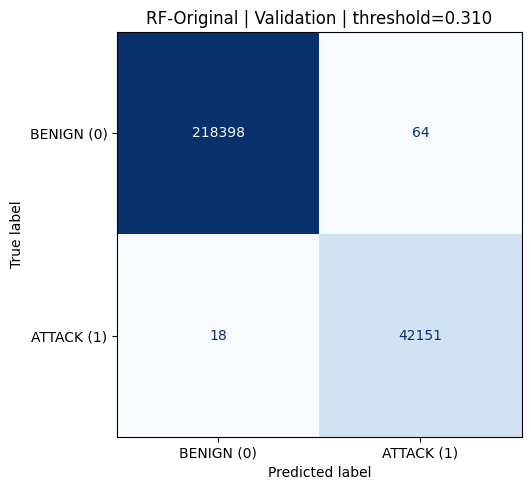

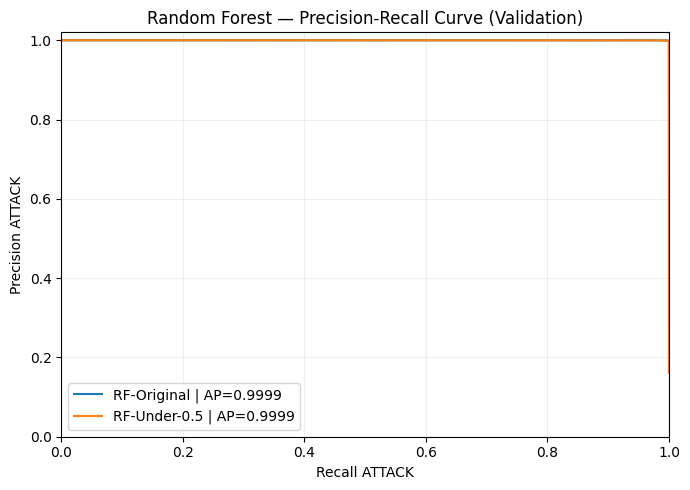

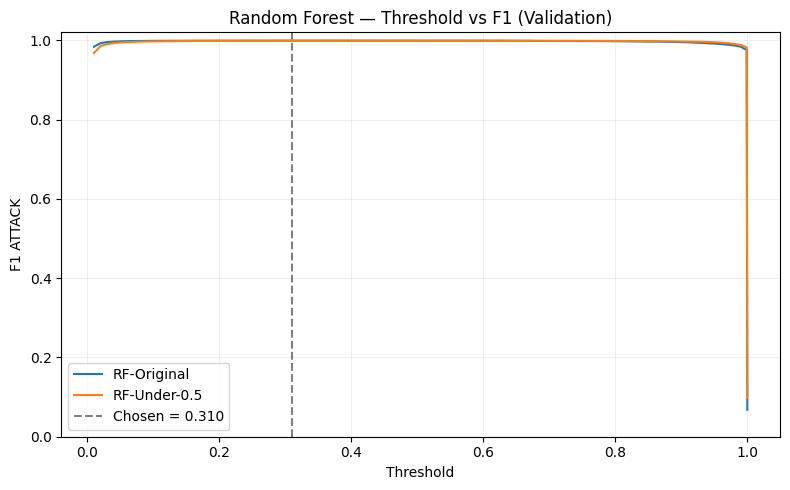

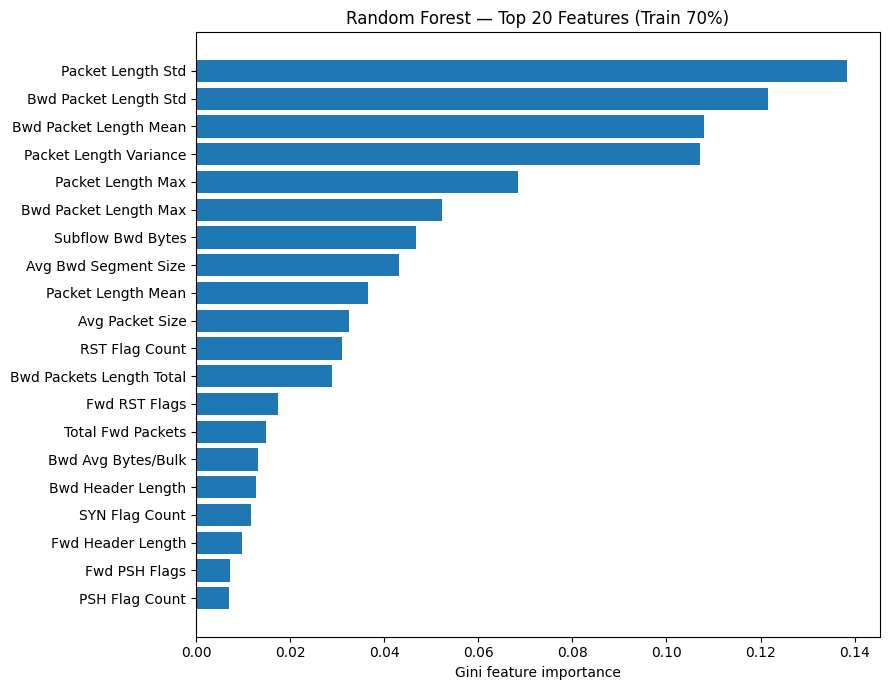

Đã lưu 4 biểu đồ và bảng feature importance.


In [38]:
# 4 BIỂU ĐỒ: CONFUSION MATRIX, PR CURVE, F1-THRESHOLD, FEATURE IMPORTANCE
# Các biểu đồ chỉ dùng kết quả Validation / mô hình đã huấn luyện trên Train.

# 1. Confusion Matrix (RF cuối)
fig, ax = plt.subplots(figsize=(6,5))
cm_b9 = confusion_matrix(y_val_b9, FINAL_RF_PRED_B9, labels=[0,1])
ConfusionMatrixDisplay(cm_b9, display_labels=['BENIGN (0)','ATTACK (1)']).plot(
    ax=ax, cmap='Blues', values_format='d', colorbar=False)
ax.set_title(f'{FINAL_RF_NAME_B9} | Validation | threshold={FINAL_RF_THRESHOLD_B9:.3f}')
plt.tight_layout(); plt.savefig(REPORT_B9/'rf_outer_validation_confusion_matrix.png',dpi=180); plt.show()

# 2. Precision-Recall Curve
fig,ax = plt.subplots(figsize=(7,5))
for name,p in validation_scores_b9.items():
    prec,rec,_ = precision_recall_curve(y_val_b9,p)
    ap = average_precision_score(y_val_b9,p)
    ax.plot(rec,prec,label=f'{name} | AP={ap:.4f}')
ax.set(xlabel='Recall ATTACK',ylabel='Precision ATTACK',title='Random Forest — Precision-Recall Curve (Validation)')
ax.set_xlim(0,1); ax.set_ylim(0,1.02); ax.legend(); ax.grid(alpha=.2)
plt.tight_layout(); plt.savefig(REPORT_B9/'rf_outer_validation_pr_curve.png',dpi=180); plt.show()

# 3. F1 theo threshold, với ngưỡng đã chọn
fig,ax = plt.subplots(figsize=(8,5))
for name,g in grid_b9.groupby('Model'):
    ax.plot(g['Threshold'],g['F1_Attack'],label=name)
ax.axvline(FINAL_RF_THRESHOLD_B9,ls='--',color='gray',label=f'Chosen = {FINAL_RF_THRESHOLD_B9:.3f}')
ax.set(xlabel='Threshold',ylabel='F1 ATTACK',title='Random Forest — Threshold vs F1 (Validation)')
ax.set_ylim(0,1.02); ax.legend(); ax.grid(alpha=.2)
plt.tight_layout(); plt.savefig(REPORT_B9/'rf_outer_validation_threshold_f1.png',dpi=180); plt.show()

# 4. Top 20 Feature Importance của RF được chọn
# Chỉ tải lại mô hình do chính notebook tạo; không tải joblib từ nguồn lạ.
rf_saved_b9 = joblib.load(model_paths_b9[FINAL_RF_NAME_B9])
importance_b9 = pd.DataFrame({
    'Feature':FEATURES_B9,
    'Importance':rf_saved_b9.named_steps['model'].feature_importances_
}).sort_values('Importance',ascending=False).reset_index(drop=True)
importance_b9.to_csv(REPORT_B9/'rf_fulltrain_feature_importance.csv',index=False)
fig,ax=plt.subplots(figsize=(9,7))
top20_b9=importance_b9.head(20).iloc[::-1]
ax.barh(top20_b9['Feature'],top20_b9['Importance'])
ax.set(xlabel='Gini feature importance',title='Random Forest — Top 20 Features (Train 70%)')
plt.tight_layout(); plt.savefig(REPORT_B9/'rf_fulltrain_feature_importance_top20.png',dpi=180,bbox_inches='tight'); plt.show()
del rf_saved_b9; gc.collect()
print('Đã lưu 4 biểu đồ và bảng feature importance.')

In [39]:
# PHÂN TÍCH THEO NGÀY / TỪNG LOẠI TẤN CÔNG (VALIDATION 15%)
# Tỷ lệ nhãn theo ngày khác nhau mạnh: các chỉ số toàn bộ có thể che khuất lỗi.

meta_b9 = pd.DataFrame({
    'day_file':val_source_b9,'attack_type':val_type_b9,
    'y_true':y_val_b9,'y_pred':FINAL_RF_PRED_B9,
    'p_attack':FINAL_RF_SCORES_B9
})

by_day_rows_b9=[]
for day,frame in meta_b9.groupby('day_file',sort=True):
    truth=frame['y_true'].to_numpy()
    pred=frame['y_pred'].to_numpy()
    tn,fp,fn,tp=confusion_matrix(truth,pred,labels=[0,1]).ravel()
    by_day_rows_b9.append({
        'Day_File':day,'Rows':len(frame),'Attack_Rows':int((truth==1).sum()),
        'Attack_Rate':float(np.mean(truth)),
        'Precision_Attack':precision_score(truth,pred,zero_division=0),
        'Recall_Attack':recall_score(truth,pred,zero_division=0),
        'F1_Attack':f1_score(truth,pred,zero_division=0),
        'FPR': fp/(tn+fp) if tn+fp else np.nan,
        'FNR': fn/(fn+tp) if fn+tp else np.nan,
        'FP':int(fp),'FN':int(fn),'TP':int(tp),'TN':int(tn)
    })
by_day_b9 = pd.DataFrame(by_day_rows_b9)
by_day_b9.to_csv(REPORT_B9/'rf_outer_validation_by_day.csv',index=False)
print('CHẤT LƯỢNG THEO NGÀY:')
display(by_day_b9.round(5))

attacks_b9 = meta_b9.loc[meta_b9['y_true']==1].copy()
by_attack_b9 = attacks_b9.groupby('attack_type').agg(
    Rows=('y_true','size'),Detected=('y_pred','sum'),
    Mean_Attack_Score=('p_attack','mean')
).reset_index()
by_attack_b9['Missed'] = by_attack_b9['Rows'] - by_attack_b9['Detected']
by_attack_b9['Recall_Attack'] = by_attack_b9['Detected']/by_attack_b9['Rows']
by_attack_b9 = by_attack_b9.sort_values('Rows',ascending=False)
by_attack_b9.to_csv(REPORT_B9/'rf_outer_validation_by_attack_type.csv',index=False)
print('RECALL THEO LOẠI TẤN CÔNG (nếu nhãn gốc đủ chi tiết):')
display(by_attack_b9)
print('Chưa đánh giá dữ liệu Test 15%.')

CHẤT LƯỢNG THEO NGÀY:


,Day_File,Rows,Attack_Rows,Attack_Rate,Precision_Attack,Recall_Attack,F1_Attack,FPR,FNR,FP,FN,TP,TN
0,Benign-Monday.parquet,52752,0,0.00000,0.00000,0.00000,0.00000,0.00002,NaN,1,0,0,52751
1,Bruteforce-Tuesday.parquet,45480,1019,0.02241,0.99901,0.99411,0.99656,0.00002,0.00589,1,6,1013,44460
2,DoS-Wednesday.parquet,69220,25825,0.37309,0.99977,0.99996,0.99986,0.00014,0.00004,6,1,25824,43389
3,Infiltration-Webattacks-Thursday.parquet,39233,772,0.01968,0.93407,0.99093,0.96166,0.00140,0.00907,54,7,765,38407
4,Portscan-DDos-Botnet-Friday.parquet,53946,14553,0.26977,0.99986,0.99973,0.99979,0.00005,0.00027,2,4,14549,39391


RECALL THEO LOẠI TẤN CÔNG (nếu nhãn gốc đủ chi tiết):


,attack_type,Rows,Detected,Mean_Attack_Score,Missed,Recall_Attack
3,DoS Hulk,23827,23827,0.999603,0,1.000000
1,DDoS,14210,14210,0.999879,0,1.000000
2,DoS GoldenEye,1159,1159,0.987470,0,1.000000
9,Infiltration - Portscan,749,745,0.905461,4,0.994660
6,FTP-Patator,590,590,0.997841,0,1.000000
5,DoS Slowloris,577,577,0.980846,0,1.000000
11,SSH-Patator,429,423,0.982215,6,0.986014
4,DoS Slowhttptest,261,260,0.987657,1,0.996169
10,Portscan,256,253,0.956457,3,0.988281
0,Botnet,87,86,0.904475,1,0.988506


Chưa đánh giá dữ liệu Test 15%.


In [40]:
# CHỐT RANDOM FOREST BASELINE 2 VÀ LƯU METADATA + KIỂM TRA TẢI LẠI
# Lưu nguyên pipeline và threshold đã CHỌN bằng Validation.

source_path_b9 = model_paths_b9[FINAL_RF_NAME_B9]
final_path_b9 = MODEL_B9/'rf_baseline2_final.joblib'
shutil.copy2(source_path_b9,final_path_b9)

metadata_b9 = {
    'model_family':'RandomForestClassifier',
    'selected_config':FINAL_RF_NAME_B9,
    'model_artifact':str(final_path_b9),
    'positive_class':1, 'negative_class':0,
    'threshold':FINAL_RF_THRESHOLD_B9,
    'under_sampling_ratio_attack_over_benign':(
        0.5 if FINAL_RF_NAME_B9=='RF-Under-0.5' else None),
    'feature_columns':FEATURES_B9,
    'n_features':len(FEATURES_B9),
    'train_rows':len(y_train_b9),
    'validation_rows':len(y_val_b9),
    'train_distribution':{'BENIGN':n0_b9,'ATTACK':n1_b9},
    'rf_params':{'n_estimators':N_TREES_B9,'max_depth':MAX_DEPTH_B9,
                 'min_samples_leaf':2,'max_features':'sqrt','bootstrap':True,
                 'class_weight':None,'random_state':SEED_B9,'n_jobs':2},
    'selection_method':'Best F1 Attack on outer Validation, subject to FPR <= 1%',
    'fpr_limit':FPR_LIMIT_B9,
    'validation_selected_metrics':{
        'Accuracy':float(best_b9['Accuracy']),
        'Precision_Attack':float(best_b9['Precision_Attack']),
        'Recall_Attack':float(best_b9['Recall_Attack']),
        'F1_Attack':float(best_b9['F1_Attack']),
        'FPR':float(best_b9['FPR']),'FNR':float(best_b9['FNR']),
        'Average_Precision':float(best_b9['Average_Precision']),
        'ROC_AUC':float(best_b9['ROC_AUC'])
    },
    'split_method':'Outer stratified 70/15/15; inner temporal folds by weekday within train70',
    'limitation':'Outer validation/test are random by class, not held out by future date; day-based folds cannot validate unseen attack types fully.',
    'test15_touched':False,
    'versions':{'python':sys.version.split()[0], 'scikit_learn':sklearn.__version__,
                'imbalanced_learn':imblearn.__version__, 'numpy':np.__version__},
    'saved_at_utc':datetime.now(timezone.utc).isoformat()
}
meta_path_b9=MODEL_B9/'rf_baseline2_metadata.json'
with open(meta_path_b9,'w',encoding='utf-8') as f:
    json.dump(metadata_b9,f,ensure_ascii=False,indent=2)

# Kiểm tra tải lại pipeline trên 100 dòng thuộc Validation
rf_reload_b9=joblib.load(final_path_b9)   # Chỉ tải artifact do chính mình tạo
class_col_b9 = int(np.flatnonzero(rf_reload_b9.named_steps['model'].classes_ == 1)[0])
reloaded_scores_b9 = rf_reload_b9.predict_proba(X_val_b9[:100])[:,class_col_b9]
assert np.allclose(reloaded_scores_b9, FINAL_RF_SCORES_B9[:100],rtol=1e-7,atol=1e-8)
assert X_val_b9.shape[1] == metadata_b9['n_features']
del rf_reload_b9

# Đối chiếu kết quả cuối LR với RF trên Validation (chưa phải Test)
lr_report_b9 = REPORT_B9/'lr_outer_validation_selected_thresholds.csv'
if lr_report_b9.exists():
    lr_table_b9 = pd.read_csv(lr_report_b9)
    best_lr_b9 = lr_table_b9.sort_values(['F1_Attack','FPR'],ascending=[False,True]).iloc[0]
    comparison_b9 = pd.DataFrame([
        {'Family':'Logistic Regression','Configuration':best_lr_b9['Model'],
         'Threshold':float(best_lr_b9['Threshold']),
         'Precision_Attack':float(best_lr_b9['Precision_Attack']),
         'Recall_Attack':float(best_lr_b9['Recall_Attack']),
         'F1_Attack':float(best_lr_b9['F1_Attack']),'FPR':float(best_lr_b9['FPR']),
         'Average_Precision':float(best_lr_b9['Average_Precision'])},
        {'Family':'Random Forest','Configuration':FINAL_RF_NAME_B9,
         'Threshold':FINAL_RF_THRESHOLD_B9,
         'Precision_Attack':float(best_b9['Precision_Attack']),
         'Recall_Attack':float(best_b9['Recall_Attack']),
         'F1_Attack':float(best_b9['F1_Attack']),'FPR':float(best_b9['FPR']),
         'Average_Precision':float(best_b9['Average_Precision'])}
    ])
    print('ĐỐI CHIẾU HAI BASELINE TRÊN CÙNG VALIDATION 15%:')
    display(comparison_b9.round(5))
    comparison_b9.to_csv(REPORT_B9/'lr_vs_rf_outer_validation.csv',index=False)
else:
    print('Không tìm thấy báo cáo LR; bỏ qua phần đối chiếu.')

print('\nHOÀN THÀNH RANDOM FOREST BASELINE 2')
print('Pipeline:',final_path_b9)
print('Metadata:',meta_path_b9)
print('Config:',FINAL_RF_NAME_B9,'| threshold:',FINAL_RF_THRESHOLD_B9)
print('Kiểm tra reload: khớp xác suất 100 dòng Validation.')
print('BƯỚC 10 TIẾP THEO: XGBoost (mô hình chính), vẫn chỉ dùng resampling 0.5 nếu chọn.')
print('TEST 15% VẪN GIỮ NGUYÊN.')

ĐỐI CHIẾU HAI BASELINE TRÊN CÙNG VALIDATION 15%:


,Family,Configuration,Threshold,Precision_Attack,Recall_Attack,F1_Attack,FPR,Average_Precision
0,Logistic Regression,LR-Original,0.38,0.98845,0.98205,0.98524,0.00222,0.99622
1,Random Forest,RF-Original,0.31,0.99848,0.99957,0.99903,0.00029,0.99994



HOÀN THÀNH RANDOM FOREST BASELINE 2
Pipeline: /content/drive/MyDrive/ThucTap/processed/models/rf_baseline2_final.joblib
Metadata: /content/drive/MyDrive/ThucTap/processed/models/rf_baseline2_metadata.json
Config: RF-Original | threshold: 0.31
Kiểm tra reload: khớp xác suất 100 dòng Validation.
BƯỚC 10 TIẾP THEO: XGBoost (mô hình chính), vẫn chỉ dùng resampling 0.5 nếu chọn.
TEST 15% VẪN GIỮ NGUYÊN.


In [41]:
# CHUẨN BỊ XGBOOST & ĐỌC DỮ LIỆU, FOLDS
# Có thể chạy độc lập sau khi mount Google Drive.
# ================================================================
!pip -q install "xgboost>=2.0" "imbalanced-learn>=0.12" pyarrow

import gc, json, time, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, average_precision_score)
from xgboost import XGBClassifier
import xgboost
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE

SEED_XGB = 42
N_TRAIN_XGB = 50_000       # CÙNG SỐ MẪU TRAIN VỚI LR VÀ RF
XGB_THRESHOLD = 0.5       # ngưỡng dự đoán tạm thời trên temporal folds
RATIO_XGB = 0.5           # ATTACK/BENIGN sau resampling, CHỐT 0.5

BASE_XGB = Path('/content/drive/MyDrive/ThucTap/processed')
SPLIT_XGB = BASE_XGB / 'splits'
REPORT_XGB = BASE_XGB / 'reports'
REPORT_XGB.mkdir(parents=True, exist_ok=True)

with open(BASE_XGB/'feature_columns.json', encoding='utf-8') as f:
    FEATURES_XGB = json.load(f)['feature_columns']

assert len(FEATURES_XGB)==82, f'Không đúng 82 đặc trưng: {len(FEATURES_XGB)}'
assert not set(FEATURES_XGB).intersection({'target','Label','_source_file'})

# Chỉ đọc TRAIN 70% đã được tạo trước đây.
train_xgb = pd.read_parquet(
    SPLIT_XGB/'train70.parquet',
    columns=FEATURES_XGB + ['target', '_source_file']
)
y_xgb = train_xgb['target'].to_numpy(dtype=np.int8)
assert set(np.unique(y_xgb))=={0,1}

with np.load(SPLIT_XGB/'temporal_folds_train70.npz') as z:
    folds_xgb = {
        f'fold{k}': (z[f'fold{k}_train_pos'].copy(),
                     z[f'fold{k}_val_pos'].copy())
        for k in (1,2,3)
    }

DAY_ORDER_XGB = ['monday', 'tuesday', 'wednesday', 'thursday', 'friday']
def day_code_xgb(name):
    matches = [i for i,d in enumerate(DAY_ORDER_XGB) if d in str(name).lower()]
    if len(matches)!=1:
        raise ValueError(f'Không xác định được ngày thu thập: {name}')
    return matches[0]

file_to_day_xgb = {
    name: day_code_xgb(name) for name in train_xgb['_source_file'].unique()
}
all_days_xgb = train_xgb['_source_file'].map(file_to_day_xgb).to_numpy(dtype=np.int8)

for fold_name,(tr_pos,va_pos) in folds_xgb.items():
    assert 0 <= tr_pos.min() <= tr_pos.max() < len(train_xgb)
    assert 0 <= va_pos.min() <= va_pos.max() < len(train_xgb)
    assert np.intersect1d(tr_pos,va_pos).size==0
    assert all_days_xgb[tr_pos].max() < all_days_xgb[va_pos].min()
    assert set(np.unique(y_xgb[tr_pos]))=={0,1}
    assert set(np.unique(y_xgb[va_pos]))=={0,1}
    print(f'{fold_name}: Train={len(tr_pos):,} | Temporal Val={len(va_pos):,} | '
          f'ATTACK Train={y_xgb[tr_pos].mean():.2%}, Val={y_xgb[va_pos].mean():.2%}')

print(f'XGBoost {xgboost.__version__} | Đã đọc Train70: {len(train_xgb):,} dòng × '
      f'{len(FEATURES_XGB)} đặc trưng.')
print('Không đọc outer Validation 15% hoặc Test 15%.')

fold1: Train=460,665 | Temporal Val=321,685 | ATTACK Train=1.05%, Val=37.36%
fold2: Train=782,350 | Temporal Val=182,667 | ATTACK Train=15.98%, Val=1.85%
fold3: Train=965,017 | Temporal Val=251,263 | ATTACK Train=13.30%, Val=27.23%
XGBoost 3.4.1 | Đã đọc Train70: 1,216,280 dòng × 82 đặc trưng.
Không đọc outer Validation 15% hoặc Test 15%.


In [42]:
# KHAI BÁO 4 CẤU HÌNH XGBOOST (CHỈ TỶ LỆ 0.5)
XGB_CONFIGS = [
    ('XGB-Original', 'original'),
    ('XGB-Weighted', 'weighted'),
    ('XGB-Under-0.5', 'undersampling'),
    ('XGB-SMOTE-0.5', 'smote')
]

# Siêu tham số ban đầu. Chưa phải tối ưu trên dữ liệu thực.
XGB_PARAMS = dict(
    objective='binary:logistic',
    eval_metric='logloss',
    n_estimators=220,
    max_depth=5,
    learning_rate=0.08,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=3,
    reg_lambda=1.0,
    tree_method='hist',
    n_jobs=2,
    random_state=SEED_XGB,
    verbosity=0
)

def build_xgb_pipeline(mode, y_train):
    y_train=np.asarray(y_train,dtype=np.int8)
    n0=int((y_train==0).sum())  # BENIGN
    n1=int((y_train==1).sum())  # ATTACK
    if not n0>0 or not n1>0:
        raise ValueError('Train phải có đủ 2 lớp BENIGN và ATTACK.')

    steps=[]
    after0,after1=n0,n1
    scale_pos_weight=1.0

    if mode=='weighted':
        # Không thay đổi số lượng dòng; chỉ điều chỉnh trọng số lớp 1.
        scale_pos_weight=n0/n1
    elif mode=='undersampling':
        # CHỈ GIẢM BENIGN (0), giữ NGUYÊN n1 ATTACK.
        after0=int(np.ceil(n1/RATIO_XGB))
        if after0>n0:
            raise ValueError('Không đủ BENIGN để Undersampling về tỷ lệ 0.5.')
        if after0<n0:
            steps.append(('sampler',RandomUnderSampler(
                sampling_strategy={0:after0},random_state=SEED_XGB)))
    elif mode=='smote':
        # CHỈ TĂNG ATTACK (1), giữ NGUYÊN n0 BENIGN.
        after1=int(np.ceil(n0*RATIO_XGB))
        if after1<n1:
            raise ValueError('ATTACK đã vượt tỷ lệ mục tiêu SMOTE 0.5.')
        if after1>n1:
            if n1<4:
                raise ValueError('SMOTE k_neighbors=3 cần tối thiểu 4 ATTACK.')
            steps.append(('sampler',SMOTE(
                sampling_strategy={1:after1},
                k_neighbors=3,random_state=SEED_XGB)))
    elif mode!='original':
        raise ValueError(f'Mode không hợp lệ: {mode}')

    steps.append(('model',XGBClassifier(
        **XGB_PARAMS,scale_pos_weight=scale_pos_weight)))
    return ImbPipeline(steps),after0,after1,scale_pos_weight

# Kiểm thử cách resampling trên đúng nhãn của Train Fold 3.
check_y = y_xgb[folds_xgb['fold3'][0][:10000]]
for label, mode in XGB_CONFIGS:
    _, n0_after, n1_after, weight=build_xgb_pipeline(mode,check_y)
    if mode=='undersampling':
        assert n1_after==int((check_y==1).sum())
    if mode=='smote':
        assert n0_after==int((check_y==0).sum())
    print(f'{label:16s} | BENIGN={n0_after:,}, ATTACK={n1_after:,} | '
          f'scale_pos_weight={weight:.3f}')

print('Chỉ dùng resampling ratio = 0.5. Không có StandardScaler và không có ratio 0.8.')

XGB-Original     | BENIGN=8,654, ATTACK=1,346 | scale_pos_weight=1.000
XGB-Weighted     | BENIGN=8,654, ATTACK=1,346 | scale_pos_weight=6.429
XGB-Under-0.5    | BENIGN=2,692, ATTACK=1,346 | scale_pos_weight=1.000
XGB-SMOTE-0.5    | BENIGN=8,654, ATTACK=4,327 | scale_pos_weight=1.000
Chỉ dùng resampling ratio = 0.5. Không có StandardScaler và không có ratio 0.8.


In [43]:
# 12 THÍ NGHIỆM XGBOOST TRÊN 3 TEMPORAL FOLDS
# Lưu checkpoint CSV sau mỗi lần fit để giảm mất mát khi Colab ngắt.
xgb_rows=[]
xgb_dist_rows=[]
xgb_imp_rows=[]

XGB_RESULT_CSV = REPORT_XGB/'xgb_temporal_3fold_4configs_05.csv'
XGB_DIST_CSV = REPORT_XGB/'xgb_temporal_distribution_05.csv'
XGB_IMP_CSV = REPORT_XGB/'xgb_temporal_feature_importance_05.csv'

for fold_name,(full_train_pos, val_pos) in folds_xgb.items():
    # Cùng train sample (50k, stratify, seed=42) như LR/RF
    if len(full_train_pos)>N_TRAIN_XGB:
        sample_pos,_=train_test_split(
            full_train_pos,train_size=N_TRAIN_XGB,
            stratify=y_xgb[full_train_pos],random_state=SEED_XGB)
    else:
        sample_pos=full_train_pos.copy()

    Xtr=train_xgb.iloc[sample_pos][FEATURES_XGB].to_numpy(dtype=np.float32)
    ytr=y_xgb[sample_pos]
    Xva=train_xgb.iloc[val_pos][FEATURES_XGB].to_numpy(dtype=np.float32)
    yva=y_xgb[val_pos]

    assert np.isfinite(Xtr).all() and np.isfinite(Xva).all(), 'Có NaN/Inf hoặc tràn float32.'
    assert set(np.unique(ytr))=={0,1} and set(np.unique(yva))=={0,1}
    old0,old1=int((ytr==0).sum()),int((ytr==1).sum())

    print(f'\n{"="*75}\n{fold_name.upper()}: Train {len(ytr):,} '
          f'(BENIGN={old0:,}, ATTACK={old1:,}) | Val {len(yva):,}\n{"="*75}')

    for config,mode in XGB_CONFIGS:
        pipe,new0,new1,weight=build_xgb_pipeline(mode,ytr)
        if mode=='undersampling':
            assert new1==old1 and 0<new0<=old0
        if mode=='smote':
            assert new0==old0 and new1>=old1
        if mode in ('smote','undersampling'):
            assert abs(new1/new0-RATIO_XGB) <= 1/new0 + 1e-8

        print(f'  Đang train {config} | Sau resampling: BENIGN={new0:,}, '
              f'ATTACK={new1:,} ...',flush=True)
        t0=time.perf_counter()
        pipe.fit(Xtr,ytr)  # Sampler chỉ chạy trong FIT (train).
        train_secs=time.perf_counter()-t0

        if mode=='undersampling' and 'sampler' in pipe.named_steps:
            used=pipe.named_steps['sampler'].sample_indices_
            assert int((ytr[used]==0).sum())==new0
            assert int((ytr[used]==1).sum())==old1
        if mode=='smote' and 'sampler' in pipe.named_steps:
            created=pipe.named_steps['sampler'].sampling_strategy_.get(1,0)
            assert new1-old1==int(created)

        class_ids=pipe.named_steps['model'].classes_
        positive_idx=int(np.flatnonzero(class_ids==1)[0])
        t1=time.perf_counter()
        scores=pipe.predict_proba(Xva)[:,positive_idx]
        pred_secs=time.perf_counter()-t1
        assert np.isfinite(scores).all() and len(scores)==len(yva)
        pred=(scores>=XGB_THRESHOLD).astype(np.int8)
        tn,fp,fn,tp=confusion_matrix(yva,pred,labels=[0,1]).ravel()

        row={
            'Fold':fold_name,'Config':config,
            'Ratio':RATIO_XGB if mode in ('undersampling','smote') else np.nan,
            'Train_Before':len(ytr),'Train_After':new0+new1,
            'Train_BENIGN_After':new0,'Train_ATTACK_After':new1,
            'Val_Rows':len(yva),'Val_ATTACK_Rate':float(yva.mean()),
            'Accuracy':accuracy_score(yva,pred),
            'Precision_Attack':precision_score(yva,pred,zero_division=0),
            'Recall_Attack':recall_score(yva,pred,zero_division=0),
            'F1_Attack':f1_score(yva,pred,zero_division=0),
            'FPR':fp/(fp+tn) if fp+tn else np.nan,
            'FNR':fn/(fn+tp) if fn+tp else np.nan,
            'ROC_AUC':roc_auc_score(yva,scores),
            'Average_Precision':average_precision_score(yva,scores),
            'TN':int(tn),'FP':int(fp),'FN':int(fn),'TP':int(tp),
            'Train_seconds':round(train_secs,2),
            'Predict_seconds':round(pred_secs,2),
            'Threshold':XGB_THRESHOLD,'Scale_Pos_Weight':weight
        }
        xgb_rows.append(row)
        xgb_dist_rows.append({
            'Fold':fold_name,'Config':config,
            'BENIGN':new0,'ATTACK':new1,'Total':new0+new1,
            'ATTACK_Percent':100*new1/(new0+new1)
        })
        xgb_imp_rows.extend({
            'Fold':fold_name,'Config':config,'Feature':feature,
            'Importance':float(imp)
        } for feature,imp in zip(
            FEATURES_XGB,pipe.named_steps['model'].feature_importances_))
        print(f'    F1={row["F1_Attack"]:.4f} | Recall={row["Recall_Attack"]:.4f} | '
              f'FPR={row["FPR"]:.5f} | AP={row["Average_Precision"]:.4f} | '
              f'Train={train_secs:.1f}s')

        # Lưu checkpoint từng cấu hình
        pd.DataFrame(xgb_rows).to_csv(XGB_RESULT_CSV,index=False)
        pd.DataFrame(xgb_dist_rows).to_csv(XGB_DIST_CSV,index=False)
        pd.DataFrame(xgb_imp_rows).to_csv(XGB_IMP_CSV,index=False)
        del pipe,scores,pred
        gc.collect()

    del Xtr,Xva,ytr,yva
    gc.collect()

result_xgb=pd.DataFrame(xgb_rows)
distribution_xgb=pd.DataFrame(xgb_dist_rows)
assert len(result_xgb)==12
assert result_xgb[['Fold','Config']].drop_duplicates().shape[0]==12
print('\nBẢNG 12 THÍ NGHIỆM XGBOOST:')
display(result_xgb.round(5))
print('\nĐã lưu:',XGB_RESULT_CSV)
print('Test 15% vẫn chưa được sử dụng.')


FOLD1: Train 50,000 (BENIGN=49,475, ATTACK=525) | Val 321,685
  Đang train XGB-Original | Sau resampling: BENIGN=49,475, ATTACK=525 ...
    F1=0.0000 | Recall=0.0000 | FPR=0.00004 | AP=0.5588 | Train=15.2s
  Đang train XGB-Weighted | Sau resampling: BENIGN=49,475, ATTACK=525 ...
    F1=0.0000 | Recall=0.0000 | FPR=0.00000 | AP=0.4205 | Train=18.5s
  Đang train XGB-Under-0.5 | Sau resampling: BENIGN=1,050, ATTACK=525 ...
    F1=0.0000 | Recall=0.0000 | FPR=0.00098 | AP=0.4149 | Train=4.1s
  Đang train XGB-SMOTE-0.5 | Sau resampling: BENIGN=49,475, ATTACK=24,738 ...
    F1=0.0000 | Recall=0.0000 | FPR=0.00004 | AP=0.4272 | Train=12.6s

FOLD2: Train 50,000 (BENIGN=42,011, ATTACK=7,989) | Val 182,667
  Đang train XGB-Original | Sau resampling: BENIGN=42,011, ATTACK=7,989 ...
    F1=0.0006 | Recall=0.0003 | FPR=0.00002 | AP=0.1727 | Train=6.4s
  Đang train XGB-Weighted | Sau resampling: BENIGN=42,011, ATTACK=7,989 ...
    F1=0.0006 | Recall=0.0003 | FPR=0.00004 | AP=0.2104 | Train=5.5s
  Đ

,Fold,Config,Ratio,Train_Before,Train_After,Train_BENIGN_After,Train_ATTACK_After,Val_Rows,Val_ATTACK_Rate,Accuracy,Precision_Attack,Recall_Attack,F1_Attack,FPR,FNR,ROC_AUC,Average_Precision,TN,FP,FN,TP,Train_seconds,Predict_seconds,Threshold,Scale_Pos_Weight
0,fold1,XGB-Original,NaN,50000,50000,49475,525,321685,0.37356,0.62641,0.00000,0.00000,0.00000,0.00004,1.00000,0.77001,0.55880,201507,8,120170,0,15.22,1.68,0.5,1.00000
1,fold1,XGB-Weighted,NaN,50000,50000,49475,525,321685,0.37356,0.62643,0.00000,0.00000,0.00000,0.00000,1.00000,0.48905,0.42052,201514,1,120170,0,18.48,1.72,0.5,94.23810
2,fold1,XGB-Under-0.5,0.5,50000,1575,1050,525,321685,0.37356,0.62582,0.00000,0.00000,0.00000,0.00098,1.00000,0.59983,0.41489,201318,197,120170,0,4.14,1.27,0.5,1.00000
3,fold1,XGB-SMOTE-0.5,0.5,50000,74213,49475,24738,321685,0.37356,0.62641,0.00000,0.00000,0.00000,0.00004,1.00000,0.50829,0.42722,201507,8,120170,0,12.58,1.23,0.5,1.00000
4,fold2,XGB-Original,NaN,50000,50000,42011,7989,182667,0.01849,0.98150,0.25000,0.00030,0.00059,0.00002,0.99970,0.94262,0.17268,179287,3,3376,1,6.38,0.75,0.5,1.00000
5,fold2,XGB-Weighted,NaN,50000,50000,42011,7989,182667,0.01849,0.98147,0.11111,0.00030,0.00059,0.00004,0.99970,0.95291,0.21039,179282,8,3376,1,5.46,0.56,0.5,5.25861
6,fold2,XGB-Under-0.5,0.5,50000,23967,15978,7989,182667,0.01849,0.98149,0.14286,0.00030,0.00059,0.00003,0.99970,0.93846,0.18977,179284,6,3376,1,1.50,0.51,0.5,1.00000
7,fold2,XGB-SMOTE-0.5,0.5,50000,63017,42011,21006,182667,0.01849,0.98150,0.25000,0.00030,0.00059,0.00002,0.99970,0.96331,0.38933,179287,3,3376,1,4.21,0.57,0.5,1.00000
8,fold3,XGB-Original,NaN,50000,50000,43348,6652,251263,0.27225,0.99200,0.99994,0.97066,0.98508,0.00002,0.02934,0.99963,0.99909,182852,4,2007,66400,5.75,0.95,0.5,1.00000
9,fold3,XGB-Weighted,NaN,50000,50000,43348,6652,251263,0.27225,0.99318,0.99985,0.97509,0.98731,0.00005,0.02491,0.99978,0.99946,182846,10,1704,66703,3.37,0.99,0.5,6.51654



Đã lưu: /content/drive/MyDrive/ThucTap/processed/reports/xgb_temporal_3fold_4configs_05.csv
Test 15% vẫn chưa được sử dụng.


TRUNG BÌNH THEO 3 FOLDS (mỗi fold trọng số bằng nhau):


,F1_Attack,Recall_Attack,Precision_Attack,FPR,FNR,Average_Precision,ROC_AUC
Config,,,,,,,
XGB-Weighted,0.32930,0.32513,0.37032,0.00003,0.67487,0.54346,0.81391
XGB-Under-0.5,0.32926,0.32630,0.37959,0.00084,0.67370,0.53469,0.84602
XGB-SMOTE-0.5,0.32868,0.32392,0.41662,0.00004,0.67608,0.60532,0.82380
XGB-Original,0.32856,0.32365,0.41665,0.00003,0.67635,0.57686,0.90409


F1 THEO FOLD:


Config,XGB-Original,XGB-SMOTE-0.5,XGB-Under-0.5,XGB-Weighted
Fold,,,,
fold1,0.00000,0.00000,0.00000,0.00000
fold2,0.00059,0.00059,0.00059,0.00059
fold3,0.98508,0.98546,0.98719,0.98731


RECALL THEO FOLD:


Config,XGB-Original,XGB-SMOTE-0.5,XGB-Under-0.5,XGB-Weighted
Fold,,,,
fold1,0.00000,0.00000,0.00000,0.00000
fold2,0.00030,0.00030,0.00030,0.00030
fold3,0.97066,0.97146,0.97861,0.97509


FPR THEO FOLD:


Config,XGB-Original,XGB-SMOTE-0.5,XGB-Under-0.5,XGB-Weighted
Fold,,,,
fold1,0.00004,0.00004,0.00098,0.00000
fold2,0.00002,0.00002,0.00003,0.00004
fold3,0.00002,0.00005,0.00150,0.00005


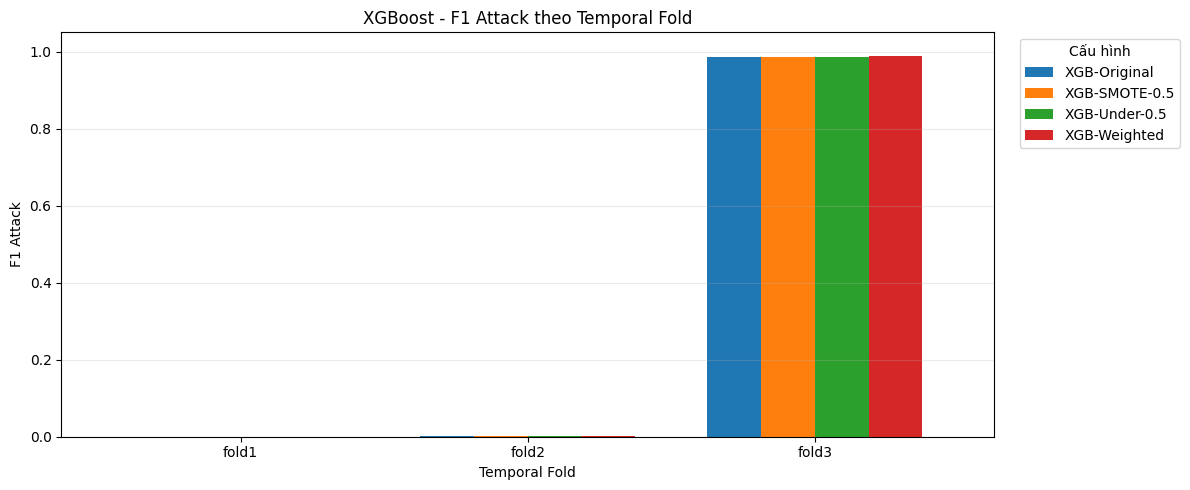

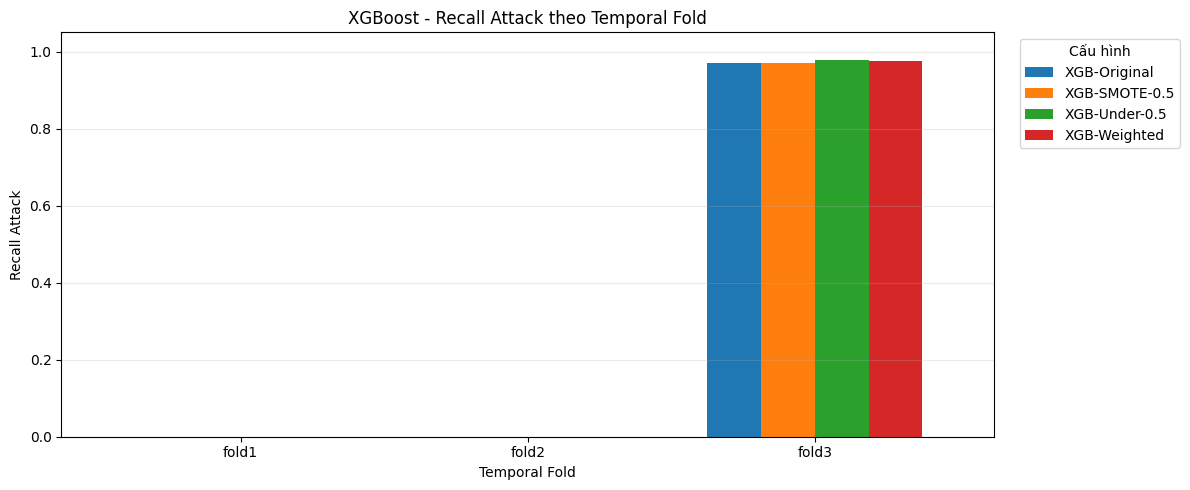

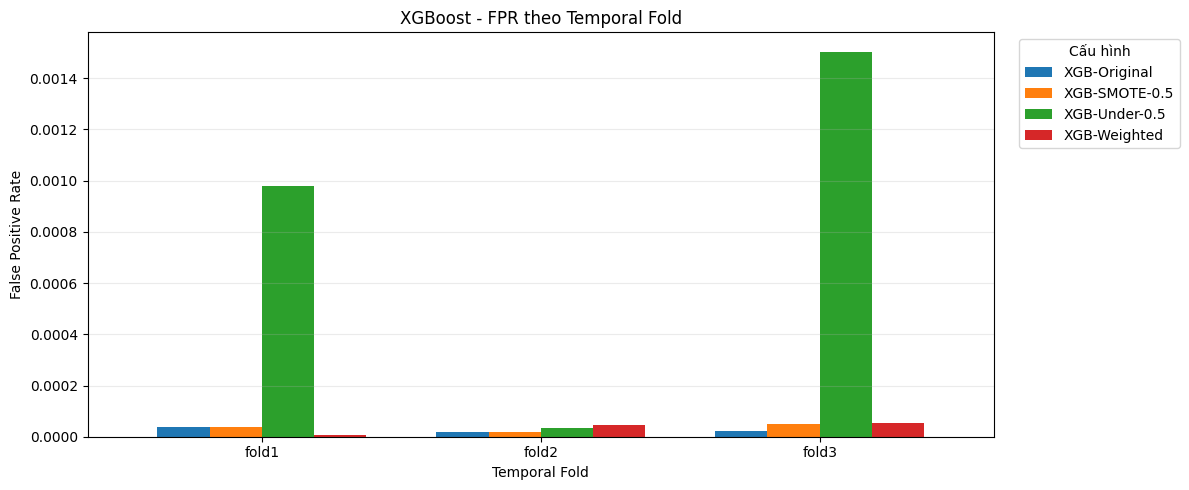

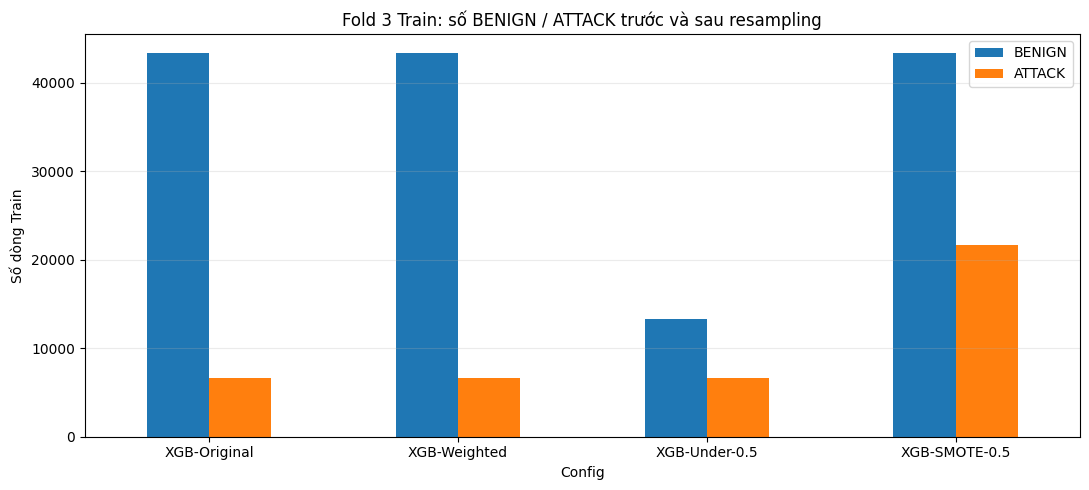

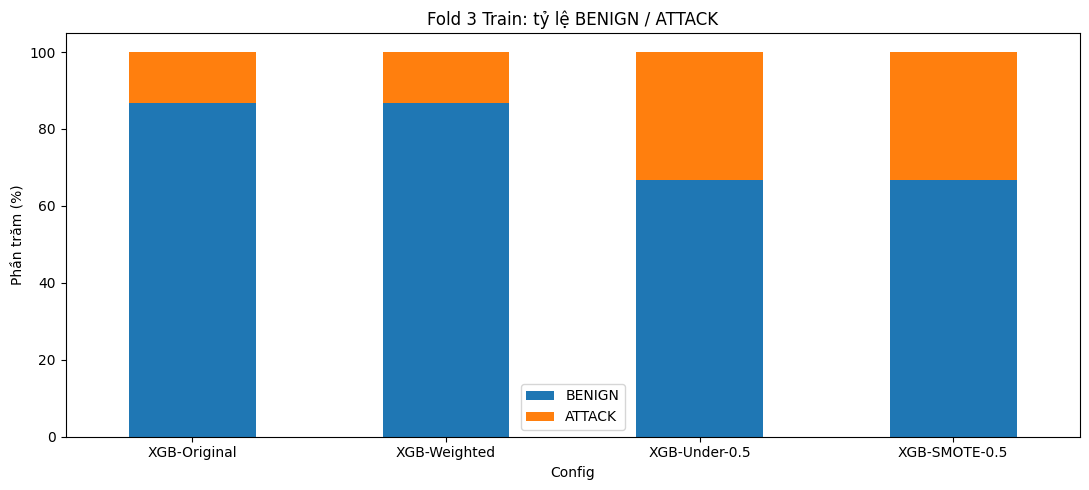

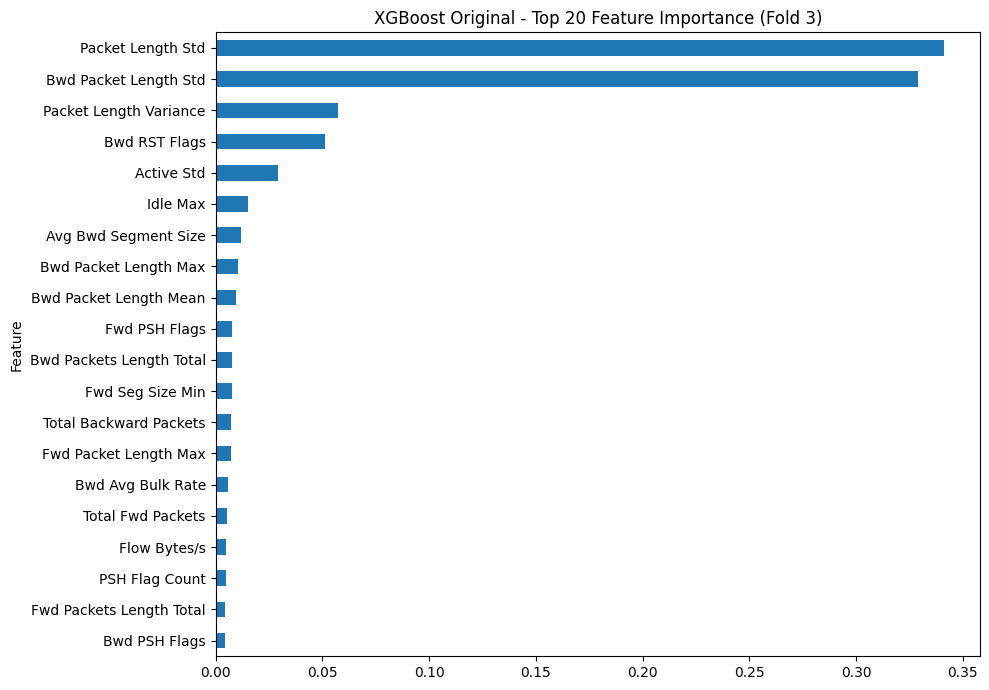

XGBoost ứng viên theo F1 trung bình: XGB-Weighted
Lưu ý: vẫn phải xét Recall, FPR và từng fold; chưa chọn mô hình cuối.


In [44]:
# BẢNG TỔNG HỢP + BIỂU ĐỒ
# Có thể chạy lại sau Cell 10.3 mà không cần huấn luyện lại.
result_xgb=pd.read_csv(REPORT_XGB/'xgb_temporal_3fold_4configs_05.csv')
distribution_xgb=pd.read_csv(REPORT_XGB/'xgb_temporal_distribution_05.csv')
importance_xgb=pd.read_csv(REPORT_XGB/'xgb_temporal_feature_importance_05.csv')

expected_xgb={'XGB-Original','XGB-Weighted','XGB-Under-0.5','XGB-SMOTE-0.5'}
assert set(result_xgb['Config'])==expected_xgb
assert set(result_xgb['Fold'])=={'fold1','fold2','fold3'}
assert not result_xgb.duplicated(['Fold','Config']).any()

METRICS_XGB=['F1_Attack','Recall_Attack','Precision_Attack',
             'FPR','FNR','Average_Precision','ROC_AUC']
mean_xgb=(result_xgb.groupby('Config')[METRICS_XGB]
          .mean().sort_values(['F1_Attack','FPR'],ascending=[False,True]))
print('TRUNG BÌNH THEO 3 FOLDS (mỗi fold trọng số bằng nhau):')
display(mean_xgb.round(5))

f1_xgb=result_xgb.pivot(index='Fold',columns='Config',values='F1_Attack')
recall_xgb=result_xgb.pivot(index='Fold',columns='Config',values='Recall_Attack')
fpr_xgb=result_xgb.pivot(index='Fold',columns='Config',values='FPR')
print('F1 THEO FOLD:'); display(f1_xgb.round(5))
print('RECALL THEO FOLD:'); display(recall_xgb.round(5))
print('FPR THEO FOLD:'); display(fpr_xgb.round(5))

mean_xgb.to_csv(REPORT_XGB/'xgb_temporal_mean_metrics_05.csv',encoding='utf-8-sig')

def plot_xgb_temporal(frame, title, ylabel, output, ylim=None):
    ax=frame.plot(kind='bar',figsize=(12,5),rot=0,width=0.75)
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.set_xlabel('Temporal Fold')
    if ylim is not None: ax.set_ylim(*ylim)
    ax.grid(axis='y',alpha=0.25)
    ax.legend(title='Cấu hình',bbox_to_anchor=(1.02,1),loc='upper left')
    plt.tight_layout()
    plt.savefig(REPORT_XGB/output,dpi=180,bbox_inches='tight')
    plt.show()

plot_xgb_temporal(f1_xgb,'XGBoost - F1 Attack theo Temporal Fold',
                  'F1 Attack','xgb_temporal_f1_05.png',(0,1.05))
plot_xgb_temporal(recall_xgb,'XGBoost - Recall Attack theo Temporal Fold',
                  'Recall Attack','xgb_temporal_recall_05.png',(0,1.05))
plot_xgb_temporal(fpr_xgb,'XGBoost - FPR theo Temporal Fold',
                  'False Positive Rate','xgb_temporal_fpr_05.png')

# Biểu đồ phân bố lớp trên Fold 3, CHỈ resampling dữ liệu Train
fold3_dist=distribution_xgb.loc[
    distribution_xgb['Fold']=='fold3',
    ['Config','BENIGN','ATTACK','Total']
].set_index('Config')
ax=fold3_dist[['BENIGN','ATTACK']].plot(kind='bar',figsize=(11,5),rot=0)
ax.set_title('Fold 3 Train: số BENIGN / ATTACK trước và sau resampling')
ax.set_ylabel('Số dòng Train')
ax.grid(axis='y',alpha=.25)
plt.tight_layout()
plt.savefig(REPORT_XGB/'xgb_fold3_distribution_counts_05.png',dpi=180,bbox_inches='tight')
plt.show()

pct=fold3_dist[['BENIGN','ATTACK']].div(fold3_dist['Total'],axis=0)*100
ax=pct.plot(kind='bar',stacked=True,figsize=(11,5),rot=0)
ax.set_title('Fold 3 Train: tỷ lệ BENIGN / ATTACK')
ax.set_ylabel('Phần trăm (%)')
ax.set_ylim(0,105)
plt.tight_layout()
plt.savefig(REPORT_XGB/'xgb_fold3_distribution_percent_05.png',dpi=180,bbox_inches='tight')
plt.show()

# Tham khảo 20 đặc trưng có importance cao ở Fold 3, XGB-Original
imp20=(importance_xgb.loc[(importance_xgb['Fold']=='fold3') &
                         (importance_xgb['Config']=='XGB-Original')]
       .sort_values('Importance',ascending=False).head(20).sort_values('Importance'))
ax=imp20.plot.barh(x='Feature',y='Importance',figsize=(10,7),legend=False)
ax.set_title('XGBoost Original - Top 20 Feature Importance (Fold 3)')
plt.tight_layout()
plt.savefig(REPORT_XGB/'xgb_fold3_feature_importance_top20_05.png',dpi=180,bbox_inches='tight')
plt.show()

print('XGBoost ứng viên theo F1 trung bình:',mean_xgb.index[0])
print('Lưu ý: vẫn phải xét Recall, FPR và từng fold; chưa chọn mô hình cuối.')

SO SÁNH BA HỌ THUẬT TOÁN: TRUNG BÌNH ĐỀU 3 FOLDS


,Family,Config,F1_Attack,Recall_Attack,FPR,Average_Precision
2,Logistic Regression,LR-Under-0.5,0.52598,0.50193,0.00448,0.59523
3,Logistic Regression,LR-Weighted,0.50564,0.48079,0.00399,0.58298
1,Logistic Regression,LR-SMOTE-0.5,0.47089,0.43377,0.00264,0.57358
0,Logistic Regression,LR-Original,0.43879,0.39630,0.00144,0.56927
6,Random Forest,RF-Under-0.5,0.32963,0.32580,0.00004,0.65858
7,Random Forest,RF-Weighted,0.32945,0.32541,0.00002,0.65515
5,Random Forest,RF-SMOTE-0.5,0.32945,0.32540,0.00002,0.63878
4,Random Forest,RF-Original,0.32940,0.32529,0.00001,0.67290
11,XGBoost,XGB-Weighted,0.32930,0.32513,0.00003,0.54346
10,XGBoost,XGB-Under-0.5,0.32926,0.32630,0.00084,0.53469


Family,Logistic Regression,Random Forest,XGBoost
Fold,,,
fold1,0.00000,0.00000,0.00000
fold2,0.33249,0.00059,0.00059
fold3,0.98389,0.98761,0.98508


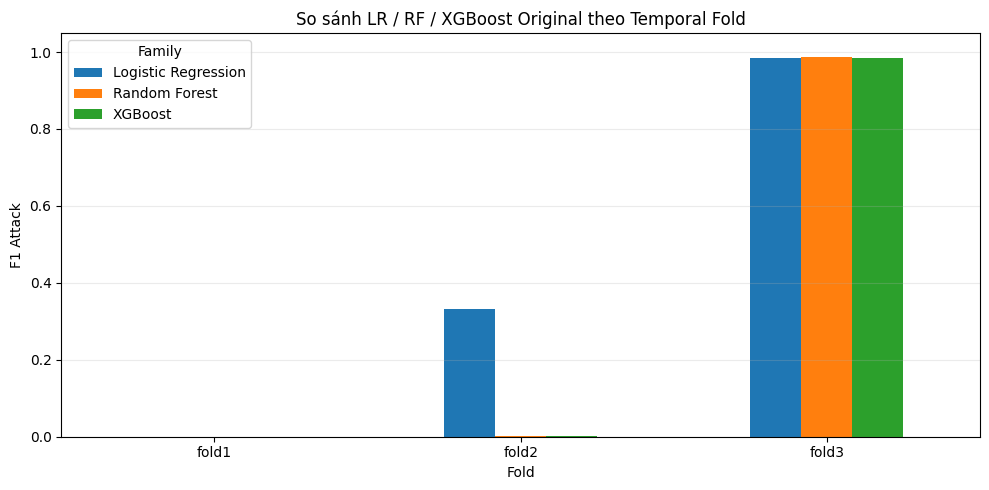

HOÀN THÀNH BƯỚC 10.
Kế tiếp: chọn 1–2 ứng viên XGBoost, fit lại trên toàn bộ Train 70%,
chọn threshold với outer Validation 15%, lưu pipeline và metadata.
Test 15% vẫn để dành cho đánh giá cuối cùng cả 3 mô hình.


In [45]:
# SO SÁNH XGBOOST VỚI HAI BASELINE TRÊN 3 TEMPORAL FOLDS
# Cả ba dùng 50K train/fold, cùng val, threshold tạm thời 0.5.
# Không so với kết quả fulltrain trên outer Validation ở Bước 7/9.
lr_path=REPORT_XGB/'lr_temporal_3fold_4configs_05.csv'
rf_path=REPORT_XGB/'rf_temporal_3fold_4configs_05.csv'
xgb_path=REPORT_XGB/'xgb_temporal_3fold_4configs_05.csv'

comparison_frames=[]
for family,path in [
    ('Logistic Regression',lr_path),
    ('Random Forest',rf_path),
    ('XGBoost',xgb_path)
]:
    if not path.exists():
        print('Chưa tìm thấy file:',path.name)
        continue
    frame=pd.read_csv(path)
    needed={'Fold','Config','F1_Attack','Recall_Attack','FPR','Average_Precision'}
    assert needed.issubset(frame.columns),f'Thiếu cột trong: {path.name}'
    assert set(frame['Fold'])=={'fold1','fold2','fold3'}
    frame=frame.copy()
    frame['Family']=family
    comparison_frames.append(frame)

if len(comparison_frames)==3:
    compare_all_xgb=pd.concat(comparison_frames,ignore_index=True)
    compare_mean_xgb=(compare_all_xgb.groupby(['Family','Config'])[
        ['F1_Attack','Recall_Attack','FPR','Average_Precision']
    ].mean().reset_index().sort_values(['Family','F1_Attack'],ascending=[True,False]))
    print('SO SÁNH BA HỌ THUẬT TOÁN: TRUNG BÌNH ĐỀU 3 FOLDS')
    display(compare_mean_xgb.round(5))
    compare_mean_xgb.to_csv(REPORT_XGB/'lr_rf_xgb_temporal_mean_05.csv',index=False)

    # So sánh cùng cấu hình Original cho 3 thuật toán.
    originals=compare_all_xgb.loc[compare_all_xgb['Config'].str.endswith('-Original')]
    f1_originals=originals.pivot(index='Fold',columns='Family',values='F1_Attack')
    display(f1_originals.round(5))
    ax=f1_originals.plot(kind='bar',figsize=(10,5),rot=0)
    ax.set_title('So sánh LR / RF / XGBoost Original theo Temporal Fold')
    ax.set_ylabel('F1 Attack')
    ax.set_ylim(0,1.05)
    ax.grid(axis='y',alpha=.25)
    plt.tight_layout()
    plt.savefig(REPORT_XGB/'lr_rf_xgb_original_temporal_f1_05.png',dpi=180,bbox_inches='tight')
    plt.show()
else:
    print('Thiếu file baseline; vẫn có kết quả XGBoost độc lập ở Cell 10.4.')

experiment_manifest_xgb={
    'model_family':'XGBClassifier',
    'stage':'Temporal CV within stratified outer Train 70%',
    'folds':{
        'fold1':'Monday-Tuesday -> Wednesday',
        'fold2':'Monday-Wednesday -> Thursday',
        'fold3':'Monday-Thursday -> Friday'
    },
    'n_train_per_fold_max':N_TRAIN_XGB,
    'seed':SEED_XGB,
    'temporary_threshold':XGB_THRESHOLD,
    'resampling_ratio_attack_over_benign':RATIO_XGB,
    'configs':[name for name,_ in XGB_CONFIGS],
    'xgb_params':XGB_PARAMS,
    'n_features':len(FEATURES_XGB),
    'no_scaler':True,
    'data_leakage_rule':'SMOTE/undersampling applied only during fold training.',
    'test15_touched':False,
    'note':'Outer 15%/15% split is stratified random; this is not fully chronological holdout.'
}
with open(REPORT_XGB/'xgb_temporal_experiment_config_05.json','w',encoding='utf-8') as f:
    json.dump(experiment_manifest_xgb,f,ensure_ascii=False,indent=2)

print('HOÀN THÀNH BƯỚC 10.')
print('Kế tiếp: chọn 1–2 ứng viên XGBoost, fit lại trên toàn bộ Train 70%,')
print('chọn threshold với outer Validation 15%, lưu pipeline và metadata.')
print('Test 15% vẫn để dành cho đánh giá cuối cùng cả 3 mô hình.')

In [46]:
# NẠP TOÀN BỘ TRAIN70 + VALIDATION15, KHÔNG ĐỌC TEST15
# Nếu vừa Restart runtime: chạy cell drive.mount(...) đầu notebook rồi chạy từ Cell 11.1.
!pip -q install "xgboost>=2.0" "imbalanced-learn>=0.12" pyarrow joblib

import gc, json, time, sys, shutil
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import xgboost, sklearn, imblearn
from xgboost import XGBClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score, average_precision_score,
                             precision_recall_curve, roc_curve, ConfusionMatrixDisplay)
from IPython.display import display

SEED_B11 = 42
FPR_LIMIT_B11 = 0.01     # 1%, cùng nguyên tắc chọn ngưỡng với các baseline
BASE_B11 = Path('/content/drive/MyDrive/ThucTap/processed')
SPLIT_B11 = BASE_B11 / 'splits'
REPORT_B11 = BASE_B11 / 'reports'
MODEL_B11 = BASE_B11 / 'models'
REPORT_B11.mkdir(parents=True, exist_ok=True)
MODEL_B11.mkdir(parents=True, exist_ok=True)

with open(BASE_B11 / 'feature_columns.json', 'r', encoding='utf-8') as f:
    FEATURES_B11 = json.load(f)['feature_columns']
assert len(FEATURES_B11) == 82 and len(set(FEATURES_B11)) == 82
assert not (set(FEATURES_B11) & {'Label', 'target', '_source_file'})

train_b11 = pd.read_parquet(SPLIT_B11 / 'train70.parquet',
                            columns=FEATURES_B11 + ['target'])
val_b11 = pd.read_parquet(SPLIT_B11 / 'validation15.parquet',
                          columns=FEATURES_B11 + ['target','Label','_source_file'])
assert list(train_b11[FEATURES_B11].columns) == list(val_b11[FEATURES_B11].columns)

X_train_b11 = train_b11[FEATURES_B11].to_numpy(dtype=np.float32)
y_train_b11 = train_b11['target'].to_numpy(dtype=np.int8)
X_val_b11 = val_b11[FEATURES_B11].to_numpy(dtype=np.float32)
y_val_b11 = val_b11['target'].to_numpy(dtype=np.int8)

# Nhãn/nguồn chỉ để phân tích, KHÔNG đưa vào X.
val_original_label_b11 = val_b11['Label'].astype('str').reset_index(drop=True)
val_source_b11 = val_b11['_source_file'].astype('str').reset_index(drop=True)

assert X_train_b11.shape[1] == X_val_b11.shape[1] == 82
assert len(y_train_b11) == 1_216_280 and len(y_val_b11) == 260_631, \
    'Kích thước khác notebook cũ: cần kiểm tra đúng dữ liệu split.'
assert set(np.unique(y_train_b11)) == {0, 1}
assert set(np.unique(y_val_b11)) == {0, 1}
assert np.isfinite(X_train_b11).all() and np.isfinite(X_val_b11).all(), \
    'Dữ liệu có NaN/Infinity hoặc tràn float32.'

n0_b11, n1_b11 = np.bincount(y_train_b11, minlength=2)
print(f'Train: {len(y_train_b11):,} | BENIGN={n0_b11:,} | ATTACK={n1_b11:,}')
print(f'Validation: {len(y_val_b11):,} | BENIGN={(y_val_b11==0).sum():,} '
      f'| ATTACK={(y_val_b11==1).sum():,}')
print(f'{X_train_b11.shape[1]} đặc trưng; XGB version {xgboost.__version__}')
print('KHÔNG sử dụng Test 15%.')

# Giải phóng bản sao DataFrame, giữ lại mảng + metadata validation
del train_b11, val_b11
gc.collect()

Train: 1,216,280 | BENIGN=1,019,490 | ATTACK=196,790
Validation: 260,631 | BENIGN=218,462 | ATTACK=42,169
82 đặc trưng; XGB version 3.4.1
KHÔNG sử dụng Test 15%.


12690

In [47]:
# FULL TRAIN XGB-ORIGINAL VÀ XGB-WEIGHTED, LƯU ỨNG VIÊN
# Dùng cùng siêu tham số Bước 10 để so sánh khách quan; không tự thay tham số dựa trên Test.

XGB_PARAMS_B11 = dict(
    objective='binary:logistic', eval_metric='logloss',
    n_estimators=220, max_depth=5, learning_rate=0.08,
    subsample=0.8, colsample_bytree=0.8,
    min_child_weight=3, reg_lambda=1.0,
    tree_method='hist', n_jobs=2, random_state=SEED_B11, verbosity=0
)

CONFIGS_B11 = [('XGB-Original', 'original'), ('XGB-Weighted', 'weighted')]
WEIGHT_B11 = float(n0_b11 / n1_b11)

validation_scores_b11 = {}
model_paths_b11 = {}
training_rows_b11 = []

for model_name, mode in CONFIGS_B11:
    weight = WEIGHT_B11 if mode == 'weighted' else 1.0
    pipeline = ImbPipeline([('model', XGBClassifier(
        **XGB_PARAMS_B11, scale_pos_weight=weight
    ))])

    print('\n' + '='*75)
    print(f'HUẤN LUYỆN {model_name}: Train={len(y_train_b11):,}; '
          f'BENIGN={n0_b11:,}; ATTACK={n1_b11:,}; scale_pos_weight={weight:.4f}')
    t0 = time.perf_counter()
    pipeline.fit(X_train_b11, y_train_b11)  # Chỉ học từ TRAIN
    train_s = time.perf_counter() - t0

    col_attack = int(np.flatnonzero(pipeline.named_steps['model'].classes_ == 1)[0])
    t1 = time.perf_counter()
    scores = pipeline.predict_proba(X_val_b11)[:, col_attack]
    predict_s = time.perf_counter() - t1
    assert len(scores) == len(y_val_b11) and np.isfinite(scores).all()

    out_path = MODEL_B11 / ('xgb_original_fulltrain.joblib' if mode == 'original'
                             else 'xgb_weighted_fulltrain.joblib')
    joblib.dump(pipeline, out_path, compress=3)
    model_paths_b11[model_name] = out_path
    validation_scores_b11[model_name] = scores.copy()
    training_rows_b11.append({
        'Model': model_name, 'Train_Rows': len(y_train_b11),
        'Train_BENIGN': int(n0_b11), 'Train_ATTACK': int(n1_b11),
        'Scale_Pos_Weight': weight,
        'Train_Seconds': round(train_s, 2),
        'Predict_Seconds': round(predict_s, 2),
        'Model_File': str(out_path)
    })
    print(f'Train: {train_s:.2f} giây; Predict Validation: {predict_s:.2f} giây')
    print('Đã lưu ứng viên:', out_path.name)
    del pipeline, scores
    gc.collect()

train_log_b11 = pd.DataFrame(training_rows_b11)
display(train_log_b11)
train_log_b11.to_csv(REPORT_B11 / 'xgb_fulltrain_training_log.csv', index=False)

# Lưu scores để có thể chạy lại Cell 11.3–11.6 mà không train lại
np.savez_compressed(
    REPORT_B11 / 'xgb_outer_validation_scores.npz',
    y_true=y_val_b11,
    score_original=validation_scores_b11['XGB-Original'],
    score_weighted=validation_scores_b11['XGB-Weighted']
)
print('Kết quả này chỉ từ Validation 15% — Test 15% chưa sử dụng.')


HUẤN LUYỆN XGB-Original: Train=1,216,280; BENIGN=1,019,490; ATTACK=196,790; scale_pos_weight=1.0000
Train: 135.53 giây; Predict Validation: 1.24 giây
Đã lưu ứng viên: xgb_original_fulltrain.joblib

HUẤN LUYỆN XGB-Weighted: Train=1,216,280; BENIGN=1,019,490; ATTACK=196,790; scale_pos_weight=5.1806
Train: 83.67 giây; Predict Validation: 1.05 giây
Đã lưu ứng viên: xgb_weighted_fulltrain.joblib


,Model,Train_Rows,Train_BENIGN,Train_ATTACK,Scale_Pos_Weight,Train_Seconds,Predict_Seconds,Model_File
0,XGB-Original,1216280,1019490,196790,1.000000,135.53,1.24,/content/drive/MyDrive/ThucTap/processed/model...
1,XGB-Weighted,1216280,1019490,196790,5.180599,83.67,1.05,/content/drive/MyDrive/ThucTap/processed/model...


Kết quả này chỉ từ Validation 15% — Test 15% chưa sử dụng.


In [48]:
# METRICS Ở NGƯỠNG 0.5 + CHỌN NGƯỠNG BẰNG VALIDATION15
# 0.5 ở phần này là THRESHOLD DỰ ĐOÁN, không phải tỷ lệ SMOTE/Undersampling.
# Chỉ tìm ngưỡng trên VALIDATION; không dùng Test.

# Hỗ trợ chạy lại nếu kernel mất biến scores nhưng còn file checkpoint
if 'validation_scores_b11' not in globals():
    with np.load(REPORT_B11/'xgb_outer_validation_scores.npz') as z:
        assert np.array_equal(z['y_true'], y_val_b11)
        validation_scores_b11 = {
            'XGB-Original': z['score_original'].copy(),
            'XGB-Weighted': z['score_weighted'].copy()
        }

THRESHOLDS_B11 = np.unique(np.r_[np.arange(0.01, 1.0, 0.01), 0.995, 0.999, 1.0])

def sweep_thresholds_b11(y_true, score, thresholds):
    # Tính TP/TN/FP/FN bằng sorted scores để quét ngưỡng hiệu quả.
    order = np.argsort(score, kind='stable')
    sorted_score = np.asarray(score)[order]
    sorted_y = np.asarray(y_true, dtype=np.int8)[order]
    cum_attack = np.r_[0, np.cumsum(sorted_y, dtype=np.int64)]
    n_attack = int(cum_attack[-1]); n_benign = len(sorted_y) - n_attack
    rows = []
    for th in thresholds:
        cut = int(np.searchsorted(sorted_score, th, side='left'))
        fn = int(cum_attack[cut]); tn = cut - fn
        tp = n_attack - fn; fp = n_benign - tn
        precision = tp/(tp+fp) if tp+fp else 0.0
        recall = tp/(tp+fn) if tp+fn else 0.0
        f1 = (2*precision*recall/(precision+recall)) if precision+recall else 0.0
        rows.append({
            'Threshold': float(th), 'Accuracy':(tp+tn)/(n_attack+n_benign),
            'Precision_Attack': precision, 'Recall_Attack':recall, 'F1_Attack':f1,
            'FPR': fp/n_benign if n_benign else np.nan,
            'FNR': fn/n_attack if n_attack else np.nan,
            'TN':int(tn),'FP':int(fp),'FN':int(fn),'TP':int(tp)
        })
    return pd.DataFrame(rows)

fixed_rows_b11=[]; chosen_rows_b11=[]; grids_b11=[]
for name,_ in CONFIGS_B11:
    scores = validation_scores_b11[name]
    extra = {
        'ROC_AUC': roc_auc_score(y_val_b11, scores),
        'Average_Precision': average_precision_score(y_val_b11, scores)
    }
    grid = sweep_thresholds_b11(y_val_b11, scores, THRESHOLDS_B11)
    grid.insert(0, 'Model', name)
    grids_b11.append(grid)

    # np.isclose vì float grid
    fixed = grid.loc[np.isclose(grid['Threshold'], 0.5)].iloc[0].to_dict()
    fixed_rows_b11.append({**fixed, **extra})

    feasible = grid.loc[grid['FPR'] <= FPR_LIMIT_B11]
    if feasible.empty:
        raise ValueError('Không có ngưỡng nào đáp ứng giới hạn FPR.')
    # Chọn F1 cao nhất, nếu hòa thì ưu tiên FPR nhỏ hơn
    selected = feasible.sort_values(
        ['F1_Attack','FPR','Threshold'], ascending=[False,True,True]
    ).iloc[0].to_dict()
    chosen_rows_b11.append({**selected, **extra})

fixed_b11 = pd.DataFrame(fixed_rows_b11)
selected_b11 = pd.DataFrame(chosen_rows_b11)
grid_b11 = pd.concat(grids_b11, ignore_index=True)
fixed_b11.to_csv(REPORT_B11 / 'xgb_outer_validation_at_05.csv', index=False)
selected_b11.to_csv(REPORT_B11 / 'xgb_outer_validation_selected_thresholds.csv', index=False)
grid_b11.to_csv(REPORT_B11 / 'xgb_outer_validation_threshold_grid.csv', index=False)

print('VALIDATION 15% — THRESHOLD 0.50')
display(fixed_b11.round(5))
print(f'VALIDATION 15% — CHỌN NGƯỠNG TỐI ƯU VỚI FPR <= {FPR_LIMIT_B11:.1%}')
display(selected_b11.round(5))

best_b11 = selected_b11.sort_values(
    ['F1_Attack', 'FPR'], ascending=[False, True]
).iloc[0]
FINAL_XGB_NAME_B11 = str(best_b11['Model'])
FINAL_XGB_THRESHOLD_B11 = float(best_b11['Threshold'])
FINAL_XGB_SCORES_B11 = validation_scores_b11[FINAL_XGB_NAME_B11]
FINAL_XGB_PRED_B11 = (FINAL_XGB_SCORES_B11 >= FINAL_XGB_THRESHOLD_B11).astype(np.int8)
assert int(((FINAL_XGB_PRED_B11==1) & (y_val_b11==0)).sum()) == int(best_b11['FP'])
assert int(((FINAL_XGB_PRED_B11==0) & (y_val_b11==1)).sum()) == int(best_b11['FN'])
print('\nỨNG VIÊN XGBOOST ĐƯỢC CHỌN:', FINAL_XGB_NAME_B11)
print('Threshold được chọn:', FINAL_XGB_THRESHOLD_B11)
print('Không đọc hay đánh giá Test15 ở Bước 11.')

VALIDATION 15% — THRESHOLD 0.50


,Model,Threshold,Accuracy,Precision_Attack,Recall_Attack,F1_Attack,FPR,FNR,TN,FP,FN,TP,ROC_AUC,Average_Precision
0,XGB-Original,0.5,0.99967,0.99855,0.99938,0.99897,0.00028,0.00062,218401,61,26,42143,0.99998,0.99989
1,XGB-Weighted,0.5,0.99967,0.99818,0.99979,0.99898,0.00035,0.00021,218385,77,9,42160,0.99998,0.99990


VALIDATION 15% — CHỌN NGƯỠNG TỐI ƯU VỚI FPR <= 1.0%


,Model,Threshold,Accuracy,Precision_Attack,Recall_Attack,F1_Attack,FPR,FNR,TN,FP,FN,TP,ROC_AUC,Average_Precision
0,XGB-Original,0.53,0.99968,0.99867,0.99934,0.99900,0.00026,0.00066,218406,56,28,42141,0.99998,0.99989
1,XGB-Weighted,0.58,0.99970,0.99834,0.99979,0.99906,0.00032,0.00021,218392,70,9,42160,0.99998,0.99990



ỨNG VIÊN XGBOOST ĐƯỢC CHỌN: XGB-Weighted
Threshold được chọn: 0.5800000000000001
Không đọc hay đánh giá Test15 ở Bước 11.


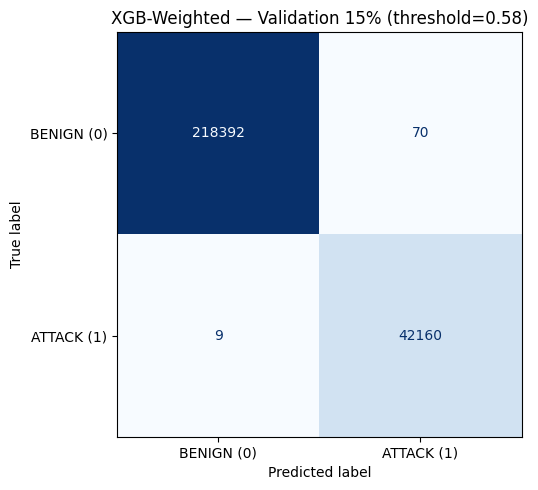

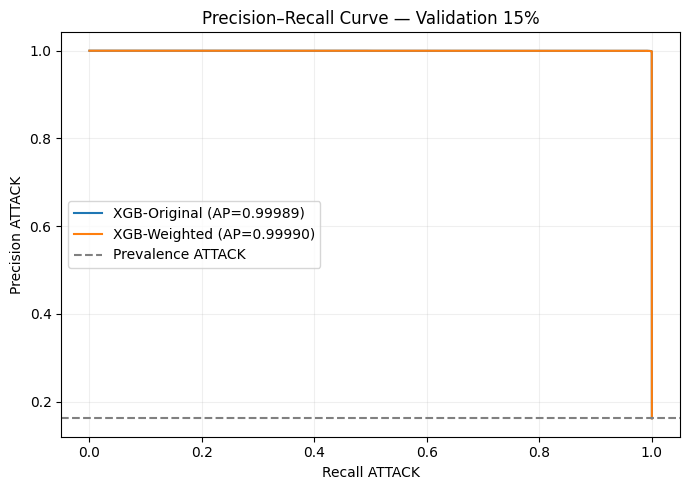

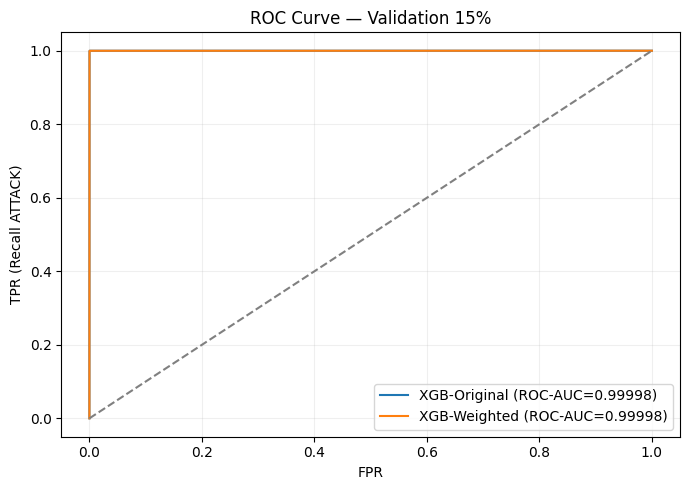

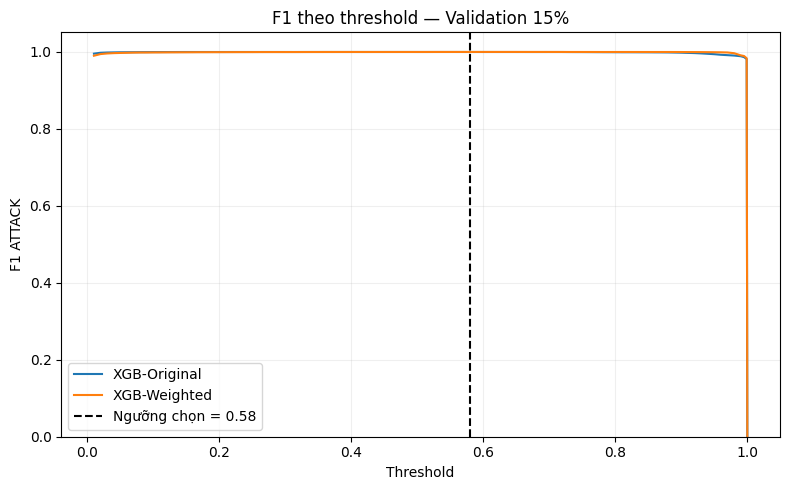

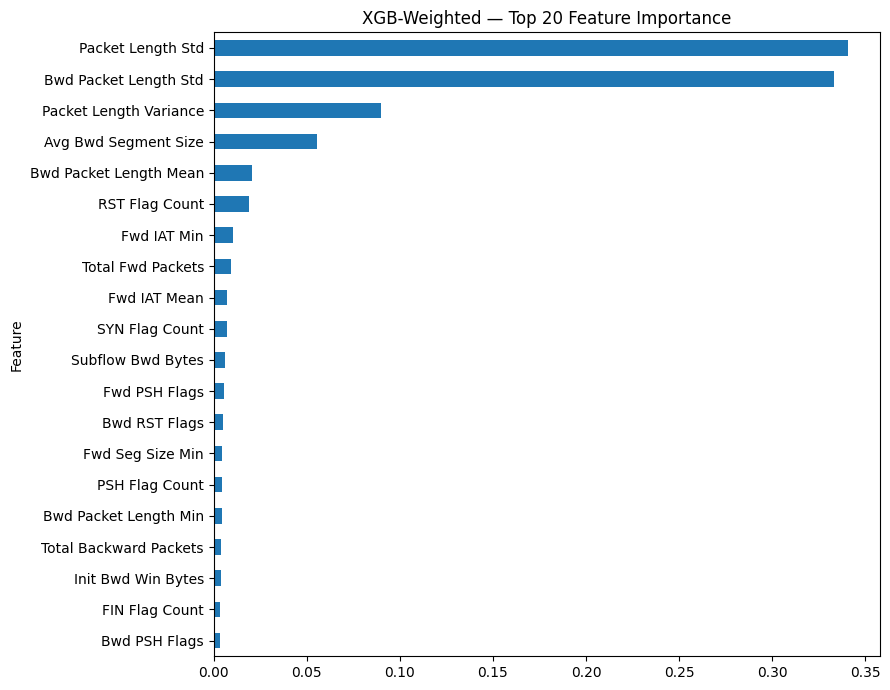

Đã lưu 5 biểu đồ và bảng feature importance.


In [49]:
# BIỂU ĐỒ VALIDATION: CONFUSION MATRIX, PR, ROC, F1 THEO THRESHOLD
fig, ax = plt.subplots(figsize=(6, 5))
cm = confusion_matrix(y_val_b11, FINAL_XGB_PRED_B11, labels=[0, 1])
ConfusionMatrixDisplay(cm, display_labels=['BENIGN (0)', 'ATTACK (1)']).plot(
    ax=ax, values_format='d', colorbar=False, cmap='Blues')
ax.set_title(f'{FINAL_XGB_NAME_B11} — Validation 15% (threshold={FINAL_XGB_THRESHOLD_B11:.2f})')
plt.tight_layout()
plt.savefig(REPORT_B11 / 'xgb_outer_validation_confusion_matrix.png', dpi=180)
plt.show()

fig, ax = plt.subplots(figsize=(7, 5))
for name, _ in CONFIGS_B11:
    precision, recall, _ = precision_recall_curve(y_val_b11, validation_scores_b11[name])
    ap = average_precision_score(y_val_b11, validation_scores_b11[name])
    ax.plot(recall, precision, label=f'{name} (AP={ap:.5f})')
ax.axhline(y_val_b11.mean(), linestyle='--', color='gray', label='Prevalence ATTACK')
ax.set(xlabel='Recall ATTACK', ylabel='Precision ATTACK', title='Precision–Recall Curve — Validation 15%')
ax.legend(); ax.grid(alpha=.2)
plt.tight_layout()
plt.savefig(REPORT_B11 / 'xgb_outer_validation_pr_curve.png', dpi=180)
plt.show()

fig, ax = plt.subplots(figsize=(7, 5))
for name, _ in CONFIGS_B11:
    fpr_curve, tpr_curve, _ = roc_curve(y_val_b11, validation_scores_b11[name])
    auc = roc_auc_score(y_val_b11, validation_scores_b11[name])
    ax.plot(fpr_curve, tpr_curve, label=f'{name} (ROC-AUC={auc:.5f})')
ax.plot([0,1],[0,1],linestyle='--',color='gray')
ax.set(xlabel='FPR',ylabel='TPR (Recall ATTACK)',title='ROC Curve — Validation 15%')
ax.legend(); ax.grid(alpha=.2)
plt.tight_layout()
plt.savefig(REPORT_B11 / 'xgb_outer_validation_roc_curve.png', dpi=180)
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
for name, grp in grid_b11.groupby('Model'):
    ax.plot(grp['Threshold'], grp['F1_Attack'], label=name)
ax.axvline(FINAL_XGB_THRESHOLD_B11, color='black', linestyle='--',
           label=f'Ngưỡng chọn = {FINAL_XGB_THRESHOLD_B11:.2f}')
ax.set(xlabel='Threshold',ylabel='F1 ATTACK',title='F1 theo threshold — Validation 15%')
ax.set_ylim(0,1.05); ax.legend(); ax.grid(alpha=.2)
plt.tight_layout()
plt.savefig(REPORT_B11 / 'xgb_outer_validation_threshold_f1.png', dpi=180)
plt.show()

# Feature importance lấy từ artifact của ứng viên được chọn (đã fit trên Train70)
chosen_pipeline_b11 = joblib.load(model_paths_b11[FINAL_XGB_NAME_B11])
importance = chosen_pipeline_b11.named_steps['model'].feature_importances_
importance_b11 = pd.DataFrame({
    'Feature': FEATURES_B11, 'Importance': importance
}).sort_values('Importance', ascending=False)
importance_b11.to_csv(REPORT_B11 / 'xgb_fulltrain_feature_importance.csv', index=False)
fig, ax = plt.subplots(figsize=(9, 7))
importance_b11.head(20).sort_values('Importance').plot.barh(
    x='Feature', y='Importance', ax=ax, legend=False)
ax.set_title(f'{FINAL_XGB_NAME_B11} — Top 20 Feature Importance')
plt.tight_layout()
plt.savefig(REPORT_B11 / 'xgb_fulltrain_feature_importance_top20.png', dpi=180,
            bbox_inches='tight')
plt.show()
del chosen_pipeline_b11
gc.collect()
print('Đã lưu 5 biểu đồ và bảng feature importance.')

In [50]:
# PHÂN TÍCH SAI SÓT THEO NGÀY VÀ LOẠI ATTACK (VALIDATION 15%)
def score_for_group_b11(y, pred):
    tn,fp,fn,tp = confusion_matrix(y, pred, labels=[0,1]).ravel()
    return {
        'Rows':len(y), 'BENIGN':int((y==0).sum()), 'ATTACK':int((y==1).sum()),
        'TN':int(tn), 'FP':int(fp), 'FN':int(fn), 'TP':int(tp),
        'Recall_Attack':tp/(tp+fn) if tp+fn else np.nan,
        'FPR':fp/(fp+tn) if fp+tn else np.nan
    }

by_day_rows_b11=[]
for source in sorted(val_source_b11.unique()):
    mask = (val_source_b11.to_numpy()==source)
    by_day_rows_b11.append({
        'Source_File':source,
        **score_for_group_b11(y_val_b11[mask], FINAL_XGB_PRED_B11[mask])
    })
by_day_b11 = pd.DataFrame(by_day_rows_b11)
by_day_b11.to_csv(REPORT_B11 / 'xgb_outer_validation_by_day.csv', index=False)
print('KẾT QUẢ THEO NGÀY (Validation 15%):')
display(by_day_b11.round(5))

attack_mask_b11 = y_val_b11==1
attack_detail_b11 = pd.DataFrame({
    'Label':val_original_label_b11.to_numpy()[attack_mask_b11],
    'Pred':FINAL_XGB_PRED_B11[attack_mask_b11]
})
by_type_b11 = (attack_detail_b11.groupby('Label')['Pred']
               .agg(ATTACK_Rows='size', Detected='sum').reset_index())
by_type_b11['Missed'] = by_type_b11['ATTACK_Rows'] - by_type_b11['Detected']
by_type_b11['Recall_Attack'] = by_type_b11['Detected'] / by_type_b11['ATTACK_Rows']
by_type_b11 = by_type_b11.sort_values('ATTACK_Rows', ascending=False)
by_type_b11.to_csv(REPORT_B11 / 'xgb_outer_validation_by_attack_type.csv', index=False)
print('KẾT QUẢ THEO TỪNG LOẠI ATTACK (Validation 15%):')
display(by_type_b11.round(5))
print('Lưu ý: loại ATTACK ít dòng có Recall dao động mạnh; chưa đánh giá Test15.')

KẾT QUẢ THEO NGÀY (Validation 15%):


,Source_File,Rows,BENIGN,ATTACK,TN,FP,FN,TP,Recall_Attack,FPR
0,Benign-Monday.parquet,52752,52752,0,52752,0,0,0,NaN,0.00000
1,Bruteforce-Tuesday.parquet,45480,44461,1019,44461,0,1,1018,0.99902,0.00000
2,DoS-Wednesday.parquet,69220,43395,25825,43389,6,1,25824,0.99996,0.00014
3,Infiltration-Webattacks-Thursday.parquet,39233,38461,772,38400,61,3,769,0.99611,0.00159
4,Portscan-DDos-Botnet-Friday.parquet,53946,39393,14553,39390,3,4,14549,0.99973,0.00008


KẾT QUẢ THEO TỪNG LOẠI ATTACK (Validation 15%):


,Label,ATTACK_Rows,Detected,Missed,Recall_Attack
3,DoS Hulk,23827,23827,0,1.00000
1,DDoS,14210,14210,0,1.00000
2,DoS GoldenEye,1159,1159,0,1.00000
9,Infiltration - Portscan,749,747,2,0.99733
6,FTP-Patator,590,590,0,1.00000
5,DoS Slowloris,577,577,0,1.00000
11,SSH-Patator,429,428,1,0.99767
4,DoS Slowhttptest,261,260,1,0.99617
10,Portscan,256,254,2,0.99219
0,Botnet,87,85,2,0.97701


Lưu ý: loại ATTACK ít dòng có Recall dao động mạnh; chưa đánh giá Test15.


In [51]:
# LƯU XGBOOST MÔ HÌNH CHÍNH, METADATA, KIỂM TRA TẢI LẠI
chosen_candidate_path_b11 = model_paths_b11[FINAL_XGB_NAME_B11]
final_xgb_path_b11 = MODEL_B11 / 'xgb_main_final.joblib'
shutil.copy2(chosen_candidate_path_b11, final_xgb_path_b11)

metadata_b11 = {
    'model_family':'XGBClassifier',
    'selected_config':FINAL_XGB_NAME_B11,
    'model_artifact':str(final_xgb_path_b11),
    'positive_class':1, 'negative_class':0,
    'threshold':FINAL_XGB_THRESHOLD_B11,
    'feature_columns':FEATURES_B11,
    'n_features':len(FEATURES_B11),
    'train_rows':len(y_train_b11),
    'validation_rows':len(y_val_b11),
    'train_distribution':{'BENIGN':int(n0_b11),'ATTACK':int(n1_b11)},
    'scale_pos_weight':WEIGHT_B11 if FINAL_XGB_NAME_B11=='XGB-Weighted' else 1.0,
    'resampling_ratio_attack_over_benign':None,
    'resampling_note':'SMOTE/Undersampling đã thử mức 0.5 tại Bước 10; không sử dụng ở hai ứng viên fulltrain.',
    'xgb_params':XGB_PARAMS_B11,
    'selection_method':'Max F1 Attack on outer Validation, constrained by FPR <= 1%',
    'fpr_limit':FPR_LIMIT_B11,
    'validation_selected_metrics':{
        key:float(best_b11[key]) for key in
        ['Accuracy','Precision_Attack','Recall_Attack','F1_Attack','FPR','FNR',
         'ROC_AUC','Average_Precision']
    },
    'split_method':'Outer stratified 70/15/15; temporal folds by weekday inside train70',
    'limitation':'Outer validation/test are random stratified, not fully future-date holdouts.',
    'test15_touched':False,
    'versions':{
        'python':sys.version.split()[0],
        'scikit_learn':sklearn.__version__,
        'imbalanced_learn':imblearn.__version__,
        'xgboost':xgboost.__version__,
        'numpy':np.__version__
    },
    'saved_at_utc':datetime.now(timezone.utc).isoformat()
}
meta_path_b11 = MODEL_B11 / 'xgb_main_metadata.json'
with open(meta_path_b11, 'w', encoding='utf-8') as f:
    json.dump(metadata_b11, f, ensure_ascii=False, indent=2)

# Kiểm tra reload 100 dòng, đảm bảo điểm số giống artifact ban đầu
reload_b11 = joblib.load(final_xgb_path_b11)  # Chỉ load artifact do chính notebook tạo
attack_idx_b11 = int(np.flatnonzero(reload_b11.named_steps['model'].classes_ == 1)[0])
reloaded_scores_b11 = reload_b11.predict_proba(X_val_b11[:100])[:, attack_idx_b11]
assert np.allclose(reloaded_scores_b11, FINAL_XGB_SCORES_B11[:100], rtol=1e-6, atol=1e-7)
assert len(metadata_b11['feature_columns']) == X_val_b11.shape[1]
del reload_b11

# Bảng đối chiếu sơ bộ cả 3 mô hình trên cùng OUTER VALIDATION
comparison_b11=[]
for family, candidate_file in [
    ('Logistic Regression', 'lr_outer_validation_selected_thresholds.csv'),
    ('Random Forest','rf_outer_validation_selected_thresholds.csv'),
    ('XGBoost','xgb_outer_validation_selected_thresholds.csv')
]:
    file = REPORT_B11 / candidate_file
    if not file.exists():
        print('Thiếu file báo cáo:', file.name)
        continue
    table = pd.read_csv(file)
    best = table.sort_values(['F1_Attack','FPR'],ascending=[False,True]).iloc[0]
    comparison_b11.append({
        'Family':family, 'Configuration':best['Model'],
        'Threshold':float(best['Threshold']),
        'Precision_Attack':float(best['Precision_Attack']),
        'Recall_Attack':float(best['Recall_Attack']),
        'F1_Attack':float(best['F1_Attack']),
        'FPR':float(best['FPR']),
        'Average_Precision':float(best['Average_Precision'])
    })
if comparison_b11:
    comparison_b11 = pd.DataFrame(comparison_b11)
    print('SO SÁNH SƠ BỘ TRÊN VALIDATION 15% (CHƯA PHẢI TEST):')
    display(comparison_b11.round(5))
    comparison_b11.to_csv(REPORT_B11 / 'lr_rf_xgb_outer_validation.csv',index=False)

print('\nHOÀN THÀNH BƯỚC 11')
print('XGBoost chính:', final_xgb_path_b11)
print('Metadata:', meta_path_b11)
print('Cấu hình:', FINAL_XGB_NAME_B11, '| threshold:', FINAL_XGB_THRESHOLD_B11)
print('Kiểm tra tải lại: KHỚP xác suất trên 100 dòng Validation.')
print('BƯỚC 12 MỚI DÙNG TEST15 ĐỂ ĐÁNH GIÁ CUỐI CẢ BA MÔ HÌNH.')

SO SÁNH SƠ BỘ TRÊN VALIDATION 15% (CHƯA PHẢI TEST):


,Family,Configuration,Threshold,Precision_Attack,Recall_Attack,F1_Attack,FPR,Average_Precision
0,Logistic Regression,LR-Original,0.38,0.98845,0.98205,0.98524,0.00222,0.99622
1,Random Forest,RF-Original,0.31,0.99848,0.99957,0.99903,0.00029,0.99994
2,XGBoost,XGB-Weighted,0.58,0.99834,0.99979,0.99906,0.00032,0.99990



HOÀN THÀNH BƯỚC 11
XGBoost chính: /content/drive/MyDrive/ThucTap/processed/models/xgb_main_final.joblib
Metadata: /content/drive/MyDrive/ThucTap/processed/models/xgb_main_metadata.json
Cấu hình: XGB-Weighted | threshold: 0.5800000000000001
Kiểm tra tải lại: KHỚP xác suất trên 100 dòng Validation.
BƯỚC 12 MỚI DÙNG TEST15 ĐỂ ĐÁNH GIÁ CUỐI CẢ BA MÔ HÌNH.


In [52]:
# ĐÓNG BĂNG 3 MÔ HÌNH VÀ THRESHOLD TRƯỚC KHI MỞ TEST
!pip -q install pyarrow joblib scikit-learn imbalanced-learn xgboost matplotlib

from google.colab import drive
drive.mount('/content/drive')

import json, time, gc, sys
from datetime import datetime, timezone
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib, sklearn, xgboost, imblearn
from IPython.display import display
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_auc_score, average_precision_score,
    precision_recall_curve, roc_curve, ConfusionMatrixDisplay,
    balanced_accuracy_score
)

BASE_B12 = Path('/content/drive/MyDrive/ThucTap/processed')
SPLIT_B12 = BASE_B12 / 'splits'
MODEL_B12 = BASE_B12 / 'models'
REPORT_B12 = BASE_B12 / 'reports' / 'test_final'
REPORT_B12.mkdir(parents=True, exist_ok=True)

with open(BASE_B12 / 'feature_columns.json', encoding='utf-8') as f:
    FEATURE_COLS_B12 = json.load(f)['feature_columns']
assert len(FEATURE_COLS_B12) == 82
assert len(set(FEATURE_COLS_B12)) == 82
assert not {'Label','target','_source_file'}.intersection(FEATURE_COLS_B12)

# Giữ nguyên thứ tự LR → RF → XGB; tuyệt đối không chọn lại theo Test.
MODEL_SPECS_B12 = {
    'Logistic Regression': {
        'model_file': 'lr_baseline1_final.joblib',
        'metadata_file': 'lr_baseline1_metadata.json', 'prefix': 'LR'
    },
    'Random Forest': {
        'model_file': 'rf_baseline2_final.joblib',
        'metadata_file': 'rf_baseline2_metadata.json', 'prefix': 'RF'
    },
    'XGBoost': {
        'model_file': 'xgb_main_final.joblib',
        'metadata_file': 'xgb_main_metadata.json', 'prefix': 'XGB'
    }
}

FROZEN_META_B12 = {}
for model_name, spec in MODEL_SPECS_B12.items():
    model_path = MODEL_B12 / spec['model_file']
    metadata_path = MODEL_B12 / spec['metadata_file']
    if not model_path.is_file() or not metadata_path.is_file():
        raise FileNotFoundError(
            f'Thiếu artifact/metadata của {model_name}: {model_path} hoặc {metadata_path}'
        )
    with metadata_path.open('r', encoding='utf-8') as f:
        md = json.load(f)
    assert md['feature_columns'] == FEATURE_COLS_B12, f'Sai thứ tự cột: {model_name}'
    assert md['positive_class'] == 1 and md['negative_class'] == 0
    assert md['n_features'] == len(FEATURE_COLS_B12)
    threshold = float(md['threshold'])
    assert np.isfinite(threshold) and 0 < threshold < 1
    FROZEN_META_B12[model_name] = md
    print(f"{model_name:20} | cấu hình: {md.get('selected_config', md.get('model_name')):17}"
          f" | threshold cố định: {threshold:.4f}")

print('\nĐã xác nhận 3 artifacts và threshold từ Validation.')
print('Không có thao tác huấn luyện hoặc chọn ngưỡng trên Test.')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Logistic Regression  | cấu hình: LR-Original       | threshold cố định: 0.3800
Random Forest        | cấu hình: RF-Original       | threshold cố định: 0.3100
XGBoost              | cấu hình: XGB-Weighted      | threshold cố định: 0.5800

Đã xác nhận 3 artifacts và threshold từ Validation.
Không có thao tác huấn luyện hoặc chọn ngưỡng trên Test.


In [53]:
# ĐỌC TEST 15% DUY NHẤT, ĐÚNG THỨ TỰ 82 ĐẶC TRƯNG
import pyarrow.parquet as pq

TEST_PATH_B12 = SPLIT_B12 / 'test15.parquet'
if not TEST_PATH_B12.is_file():
    raise FileNotFoundError(f'Chưa có file Test: {TEST_PATH_B12}')

parquet_meta_b12 = pq.ParquetFile(TEST_PATH_B12)
assert parquet_meta_b12.metadata.num_rows == 260_632, (
    'Số dòng Test khác kết quả Bước 4; cần xác minh split đúng trước khi đánh giá!'
)
needed_b12 = FEATURE_COLS_B12 + ['target','Label','_source_file']
missing_b12 = set(needed_b12) - set(parquet_meta_b12.schema_arrow.names)
assert not missing_b12, f'Test thiếu các cột: {sorted(missing_b12)}'

test_df_b12 = pd.read_parquet(TEST_PATH_B12, columns=needed_b12)
X_test_b12 = test_df_b12[FEATURE_COLS_B12].to_numpy(dtype=np.float32)
y_test_b12 = test_df_b12['target'].to_numpy(dtype=np.int8)
test_source_b12 = test_df_b12['_source_file'].astype(str).to_numpy()
test_type_b12 = test_df_b12['Label'].astype(str).to_numpy()

assert X_test_b12.shape == (260_632, 82)
assert set(np.unique(y_test_b12)) == {0, 1}
assert np.isfinite(X_test_b12).all(), 'Test có NaN/Infinity: không tự ý làm sạch bằng Test!'
assert len(test_source_b12) == len(test_type_b12) == len(y_test_b12)

print(f'Test: {len(y_test_b12):,} dòng; {X_test_b12.shape[1]} đặc trưng')
print(f'BENIGN (0): {(y_test_b12 == 0).sum():,}')
print(f'ATTACK (1): {(y_test_b12 == 1).sum():,}')
print('\nDữ liệu nhãn gốc và _source_file chỉ dành cho báo cáo, KHÔNG đưa vào predict.')

# Dùng mảng X_test; bỏ bản sao DataFrame lớn để tiết kiệm RAM.
del test_df_b12
gc.collect()

Test: 260,632 dòng; 82 đặc trưng
BENIGN (0): 218,463
ATTACK (1): 42,169

Dữ liệu nhãn gốc và _source_file chỉ dành cho báo cáo, KHÔNG đưa vào predict.


74

In [54]:
# DỰ ĐOÁN 3 PIPELINE ĐÃ LƯU (CHỈ predict_proba, KHÔNG FIT)
# Chạy theo batch để tiết kiệm RAM trên Colab miễn phí.
BATCH_SIZE_B12 = 20_000
SCORES_B12 = {}
PREDS_B12 = {}
TIMING_B12 = {}

for model_name, spec in MODEL_SPECS_B12.items():
    artifact = MODEL_B12 / spec['model_file']
    print('\n' + '='*65)
    print('ĐANG DỰ ĐOÁN:', model_name)
    # CHỈ LOAD .joblib được tạo từ notebook của bạn, không tải model không tin cậy.
    pipeline_b12 = joblib.load(artifact)
    if 'model' not in pipeline_b12.named_steps:
        raise ValueError(f'Pipeline của {model_name} thiếu bước model!')
    classes_b12 = np.asarray(pipeline_b12.named_steps['model'].classes_)
    assert set(classes_b12.tolist()) == {0, 1}
    attack_col_b12 = int(np.flatnonzero(classes_b12 == 1)[0])

    frozen_threshold = float(FROZEN_META_B12[model_name]['threshold'])
    out_scores = np.empty(len(y_test_b12), dtype=np.float64)
    t0 = time.perf_counter()
    for start in range(0, len(y_test_b12), BATCH_SIZE_B12):
        end = min(start + BATCH_SIZE_B12, len(y_test_b12))
        probability = pipeline_b12.predict_proba(X_test_b12[start:end])
        out_scores[start:end] = probability[:, attack_col_b12]
    seconds = time.perf_counter() - t0

    assert np.isfinite(out_scores).all()
    assert ((out_scores >= 0) & (out_scores <= 1)).all()
    SCORES_B12[model_name] = out_scores
    PREDS_B12[model_name] = (out_scores >= frozen_threshold).astype(np.int8)
    TIMING_B12[model_name] = float(seconds)
    print(f'Threshold từ Validation: {frozen_threshold:.3f}')
    print(f'Thời gian predict_proba: {seconds:.2f} giây '
          f'({seconds * 1000 / len(y_test_b12):.4f} ms/flow, chưa gồm load model)')
    del pipeline_b12, probability, out_scores
    gc.collect()

assert len(SCORES_B12) == len(PREDS_B12) == len(MODEL_SPECS_B12) == 3
print('\nDự đoán xong cả 3 mô hình. Chưa thay đổi model hoặc threshold.')


ĐANG DỰ ĐOÁN: Logistic Regression
Threshold từ Validation: 0.380
Thời gian predict_proba: 0.42 giây (0.0016 ms/flow, chưa gồm load model)

ĐANG DỰ ĐOÁN: Random Forest
Threshold từ Validation: 0.310
Thời gian predict_proba: 5.24 giây (0.0201 ms/flow, chưa gồm load model)

ĐANG DỰ ĐOÁN: XGBoost
Threshold từ Validation: 0.580
Thời gian predict_proba: 3.92 giây (0.0150 ms/flow, chưa gồm load model)

Dự đoán xong cả 3 mô hình. Chưa thay đổi model hoặc threshold.


In [55]:
# BẢNG METRIC CUỐI: GIỮ NGUYÊN THRESHOLD CHỐT TỪ VALIDATION
metric_rows_b12 = []
confusions_b12 = {}

for name in MODEL_SPECS_B12:
    scores = SCORES_B12[name]
    pred = PREDS_B12[name]
    tn, fp, fn, tp = confusion_matrix(y_test_b12, pred, labels=[0,1]).ravel()
    confusions_b12[name] = np.array([[tn, fp], [fn, tp]], dtype=np.int64)

    metric_rows_b12.append({
        'Model': name,
        'Selected_Config': FROZEN_META_B12[name].get(
            'selected_config', FROZEN_META_B12[name].get('model_name')),
        'Threshold_from_Validation': float(FROZEN_META_B12[name]['threshold']),
        'Test_Rows': len(y_test_b12),
        'Accuracy': accuracy_score(y_test_b12, pred),
        'Balanced_Accuracy': balanced_accuracy_score(y_test_b12, pred),
        'Precision_Attack': precision_score(y_test_b12, pred, zero_division=0),
        'Recall_Attack': recall_score(y_test_b12, pred, zero_division=0),
        'F1_Attack': f1_score(y_test_b12, pred, zero_division=0),
        'FPR': float(fp/(fp+tn)) if (fp+tn)>0 else np.nan,
        'FNR': float(fn/(fn+tp)) if (fn+tp)>0 else np.nan,
        'ROC_AUC': roc_auc_score(y_test_b12, scores),
        'Average_Precision': average_precision_score(y_test_b12, scores),
        'TN': int(tn), 'FP': int(fp), 'FN': int(fn), 'TP': int(tp),
        'Predict_Seconds': TIMING_B12[name],
        'Milliseconds_per_flow': 1000 * TIMING_B12[name] / len(y_test_b12)
    })

metrics_b12 = pd.DataFrame(metric_rows_b12)
print('BẢNG ĐÁNH GIÁ CUỐI - TEST 15% (KHÔNG TUNING)')
display(metrics_b12.round(6))
metrics_b12.to_csv(REPORT_B12/'final_test_metrics_3models.csv',index=False,encoding='utf-8-sig')

assert (metrics_b12[['TN','FP','FN','TP']].sum(axis=1) == len(y_test_b12)).all()
print('\nĐã lưu bảng metric. AP = Average Precision (khác PR-AUC nội suy).')
print('Không chọn lại mô hình hoặc thay threshold theo F1 trên Test.')

BẢNG ĐÁNH GIÁ CUỐI - TEST 15% (KHÔNG TUNING)


,Model,Selected_Config,Threshold_from_Validation,Test_Rows,Accuracy,Balanced_Accuracy,Precision_Attack,Recall_Attack,F1_Attack,FPR,FNR,ROC_AUC,Average_Precision,TN,FP,FN,TP,Predict_Seconds,Milliseconds_per_flow
0,Logistic Regression,LR-Original,0.38,260632,0.995162,0.989765,0.988232,0.981788,0.984999,0.002257,0.018212,0.998608,0.996127,217970,493,768,41401,0.417551,0.001602
1,Random Forest,RF-Original,0.31,260632,0.999597,0.999568,0.997987,0.999526,0.998756,0.000389,0.000474,0.999993,0.999954,218378,85,20,42149,5.237768,0.020096
2,XGBoost,XGB-Weighted,0.58,260632,0.999601,0.999676,0.997752,0.999787,0.998768,0.000435,0.000213,0.999994,0.999964,218368,95,9,42160,3.919825,0.015040



Đã lưu bảng metric. AP = Average Precision (khác PR-AUC nội suy).
Không chọn lại mô hình hoặc thay threshold theo F1 trên Test.


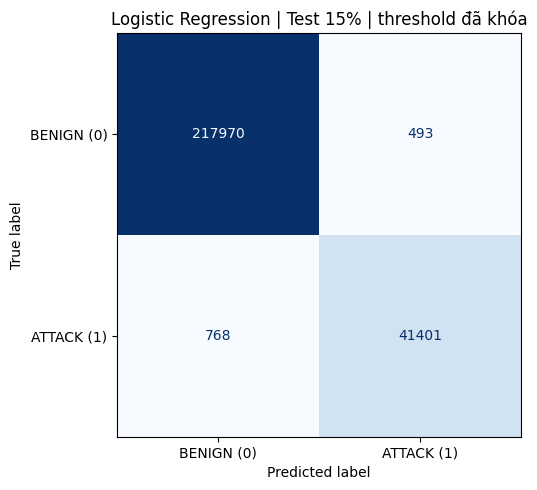

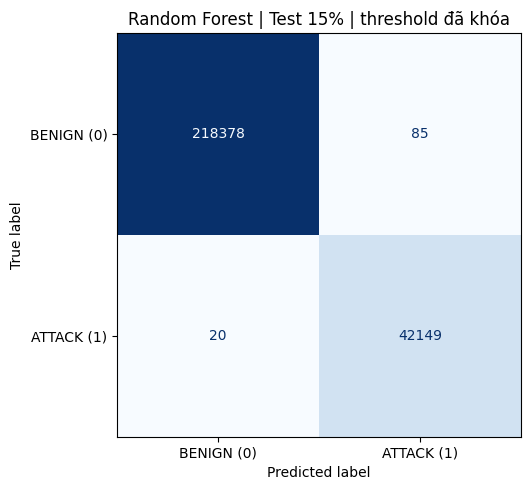

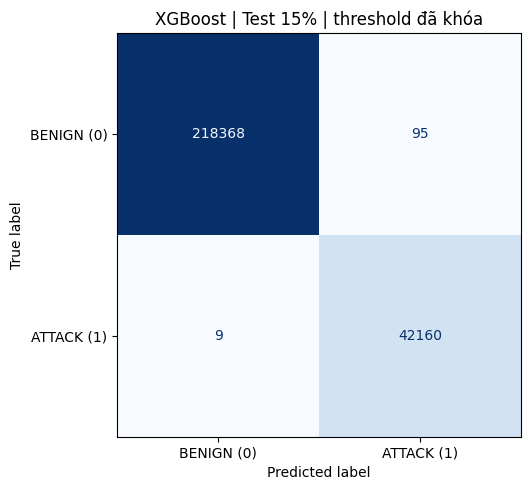

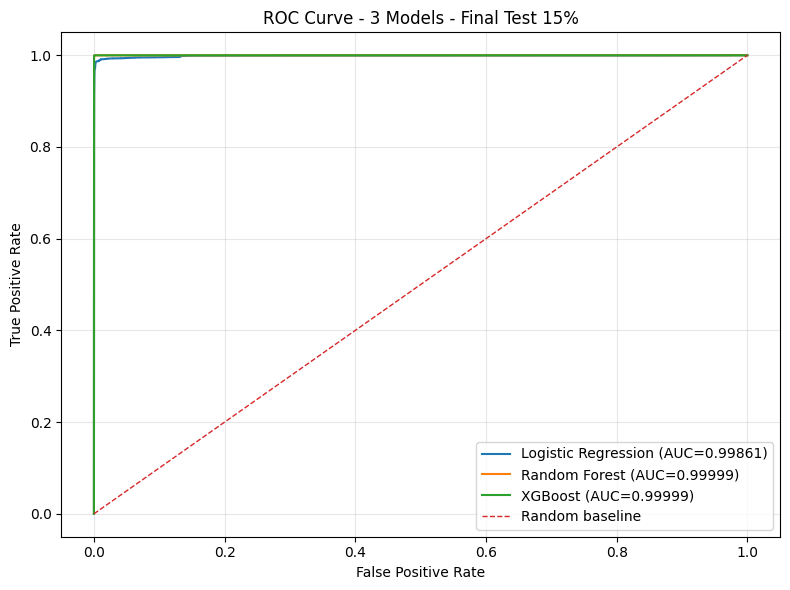

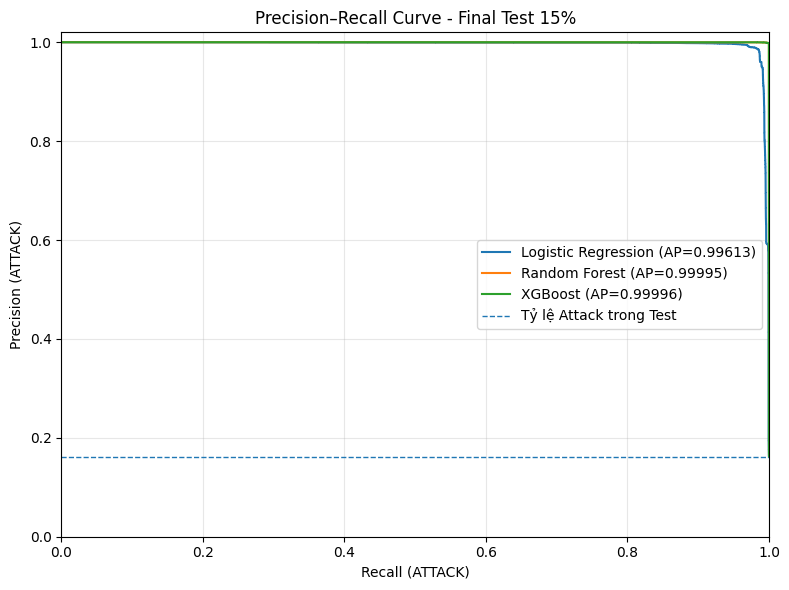

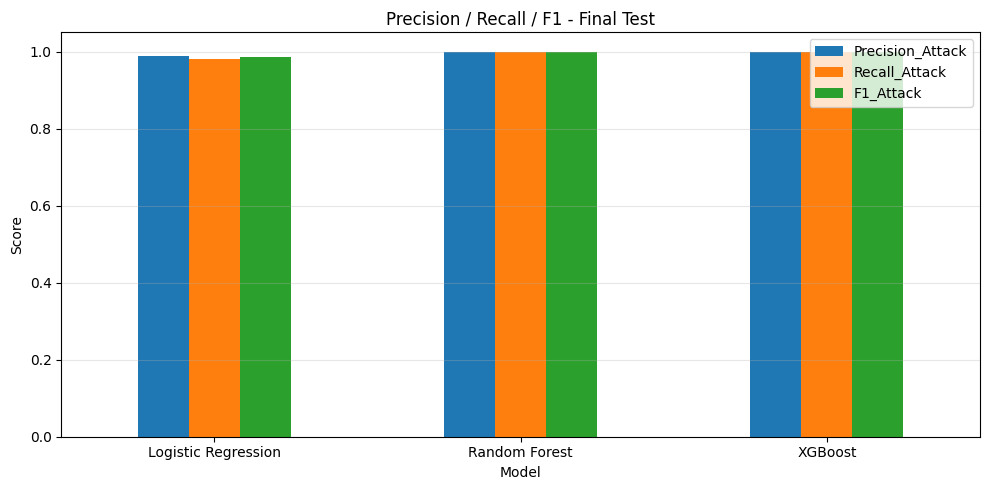

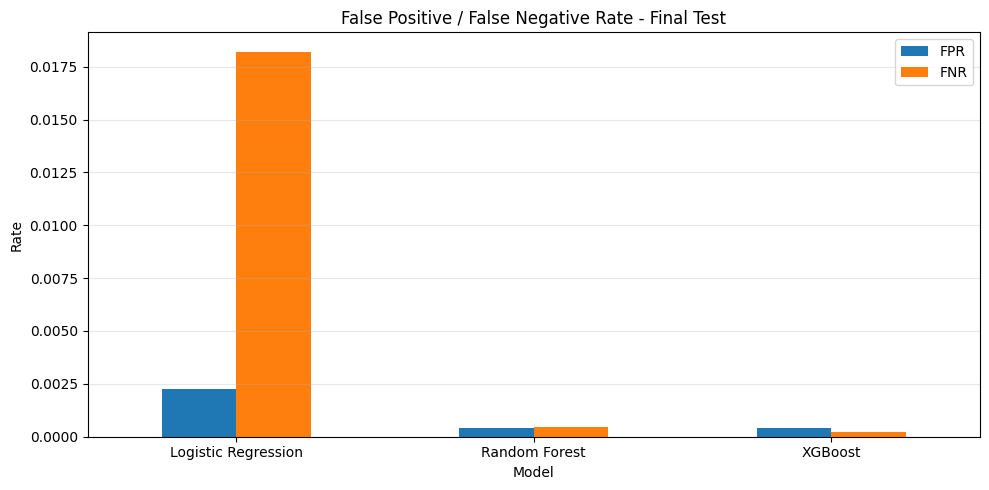

Đã lưu 3 ma trận nhầm lẫn và 4 biểu đồ so sánh.


In [56]:
# VẼ CONFUSION MATRIX, ROC, PR VÀ BIỂU ĐỒ SO SÁNH

# 1. Ma trận nhầm lẫn: mỗi mô hình một ảnh.
for name, spec in MODEL_SPECS_B12.items():
    fig, ax = plt.subplots(figsize=(6, 5))
    ConfusionMatrixDisplay(
        confusion_matrix=confusions_b12[name],
        display_labels=['BENIGN (0)', 'ATTACK (1)']
    ).plot(ax=ax, values_format='d', cmap='Blues', colorbar=False)
    ax.set_title(f'{name} | Test 15% | threshold đã khóa')
    fig.tight_layout()
    fig.savefig(REPORT_B12/f"{spec['prefix'].lower()}_test_confusion_matrix.png",
                dpi=180,bbox_inches='tight')
    plt.show()

# 2. ROC Curve chung.
fig, ax = plt.subplots(figsize=(8, 6))
for name in MODEL_SPECS_B12:
    fpr_vals, tpr_vals, _ = roc_curve(y_test_b12, SCORES_B12[name])
    area = roc_auc_score(y_test_b12, SCORES_B12[name])
    ax.plot(fpr_vals, tpr_vals, label=f'{name} (AUC={area:.5f})')
ax.plot([0,1],[0,1],linestyle='--',linewidth=1,label='Random baseline')
ax.set(xlabel='False Positive Rate',ylabel='True Positive Rate',
       title='ROC Curve - 3 Models - Final Test 15%')
ax.legend(); ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(REPORT_B12/'final_test_roc_comparison.png',dpi=180,bbox_inches='tight')
plt.show()

# 3. Precision–Recall Curve chung.
fig, ax = plt.subplots(figsize=(8, 6))
for name in MODEL_SPECS_B12:
    pvals, rvals, _ = precision_recall_curve(y_test_b12, SCORES_B12[name])
    ap = average_precision_score(y_test_b12, SCORES_B12[name])
    ax.plot(rvals, pvals, label=f'{name} (AP={ap:.5f})')
ax.axhline(float(y_test_b12.mean()), linestyle='--', linewidth=1,
           label='Tỷ lệ Attack trong Test')
ax.set(xlabel='Recall (ATTACK)', ylabel='Precision (ATTACK)',
       title='Precision–Recall Curve - Final Test 15%', xlim=(0,1), ylim=(0,1.02))
ax.legend(); ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(REPORT_B12/'final_test_pr_comparison.png',dpi=180,bbox_inches='tight')
plt.show()

# 4. So sánh Precision / Recall / F1.
ax = metrics_b12.set_index('Model')[
    ['Precision_Attack','Recall_Attack','F1_Attack']
].plot(kind='bar', figsize=(10, 5), rot=0)
ax.set(title='Precision / Recall / F1 - Final Test', ylabel='Score', ylim=(0,1.05))
ax.grid(axis='y',alpha=0.3)
plt.tight_layout()
plt.savefig(REPORT_B12/'final_test_precision_recall_f1.png',dpi=180,bbox_inches='tight')
plt.show()

# 5. So sánh FPR / FNR (giá trị càng thấp càng tốt).
ax = metrics_b12.set_index('Model')[['FPR','FNR']].plot(
    kind='bar', figsize=(10, 5), rot=0)
ax.set(title='False Positive / False Negative Rate - Final Test',ylabel='Rate')
ax.grid(axis='y',alpha=0.3)
plt.tight_layout()
plt.savefig(REPORT_B12/'final_test_fpr_fnr.png',dpi=180,bbox_inches='tight')
plt.show()
print('Đã lưu 3 ma trận nhầm lẫn và 4 biểu đồ so sánh.')

In [57]:
# PHÂN TÍCH TEST THEO NGÀY VÀ TỪNG LOẠI TẤN CÔNG
# Đây là phân tích mô tả trên Test, KHÔNG dùng để chỉnh model/threshold.

def group_metrics_b12(frame):
    tn,fp,fn,tp = confusion_matrix(frame['y_true'],frame['y_pred'],labels=[0,1]).ravel()
    return {
        'Rows': len(frame), 'BENIGN': int(tn+fp), 'ATTACK': int(fn+tp),
        'TN': int(tn), 'FP': int(fp), 'FN': int(fn), 'TP': int(tp),
        'Recall_Attack': tp/(tp+fn) if (tp+fn) else np.nan,
        'FPR': fp/(tn+fp) if (tn+fp) else np.nan
    }

by_day_b12 = []
by_attack_b12 = []

for name in MODEL_SPECS_B12:
    frame = pd.DataFrame({
        'source_file':test_source_b12,
        'original_label':test_type_b12,
        'y_true':y_test_b12,
        'y_pred':PREDS_B12[name]
    })
    for day, sub in frame.groupby('source_file', sort=True):
        by_day_b12.append({'Model':name,'Source_File':day,**group_metrics_b12(sub)})

    # Recall theo loại ATTACK gốc. Chỉ nhóm nhãn dương (ATTACK=1).
    only_attacks = frame.loc[frame['y_true'] == 1]
    for attack_type, sub in only_attacks.groupby('original_label', sort=True):
        detected = int((sub['y_pred'] == 1).sum())
        missed = len(sub) - detected
        by_attack_b12.append({
            'Model':name,'Attack_Type':attack_type,'Actual_ATTACK':len(sub),
            'Detected_TP':detected,'Missed_FN':missed,
            'Recall_Attack':detected/len(sub)
        })

day_metrics_b12 = pd.DataFrame(by_day_b12)
attack_metrics_b12 = pd.DataFrame(by_attack_b12)
display(day_metrics_b12.round(5))
print('RECALL THEO LOẠI TẤN CÔNG:')
display(attack_metrics_b12.pivot(index='Attack_Type',columns='Model',
                                  values='Recall_Attack').round(5))

day_metrics_b12.to_csv(REPORT_B12/'final_test_by_day.csv',
                        index=False,encoding='utf-8-sig')
attack_metrics_b12.to_csv(REPORT_B12/'final_test_by_attack_type.csv',
                           index=False,encoding='utf-8-sig')
print('\nChú ý: dữ liệu các ngày trong outer Test là stratified random, KHÔNG phải future holdout.')

,Model,Source_File,Rows,BENIGN,ATTACK,TN,FP,FN,TP,Recall_Attack,FPR
0,Logistic Regression,Benign-Monday.parquet,52564,52564,0,52486,78,0,0,NaN,0.00148
1,Logistic Regression,Bruteforce-Tuesday.parquet,46068,44990,1078,44869,121,92,986,0.91466,0.00269
2,Logistic Regression,DoS-Wednesday.parquet,68926,43155,25771,43078,77,243,25528,0.99057,0.00178
3,Logistic Regression,Infiltration-Webattacks-Thursday.parquet,39504,38774,730,38633,141,124,606,0.83014,0.00364
4,Logistic Regression,Portscan-DDos-Botnet-Friday.parquet,53570,38980,14590,38904,76,309,14281,0.97882,0.00195
5,Random Forest,Benign-Monday.parquet,52564,52564,0,52562,2,0,0,NaN,0.00004
6,Random Forest,Bruteforce-Tuesday.parquet,46068,44990,1078,44988,2,5,1073,0.99536,0.00004
7,Random Forest,DoS-Wednesday.parquet,68926,43155,25771,43152,3,4,25767,0.99984,0.00007
8,Random Forest,Infiltration-Webattacks-Thursday.parquet,39504,38774,730,38697,77,9,721,0.98767,0.00199
9,Random Forest,Portscan-DDos-Botnet-Friday.parquet,53570,38980,14590,38979,1,2,14588,0.99986,0.00003


RECALL THEO LOẠI TẤN CÔNG:


Model,Logistic Regression,Random Forest,XGBoost
Attack_Type,,,
Botnet,0.04878,0.99187,0.99187
DDoS,0.99902,1.00000,1.00000
DoS GoldenEye,0.92261,0.99914,1.00000
DoS Hulk,0.99912,1.00000,1.00000
DoS Slowhttptest,0.73077,0.99615,0.99615
DoS Slowloris,0.89492,0.99661,1.00000
FTP-Patator,1.00000,1.00000,1.00000
Heartbleed,1.00000,1.00000,1.00000
Infiltration,0.00000,0.80000,0.60000



Chú ý: dữ liệu các ngày trong outer Test là stratified random, KHÔNG phải future holdout.
